# Laboratorio 3 — Reidentificación de Personas No Supervisada con RETRO
## Versiones 1 y 2: RETRO con maestro adaptado (v1) y con maestro entrenado con pseudo-etiquetas (v2)

**Curso:** Deep Learning — Maestría en Data Science & AI, UTEC  
**Autores:** David Choque, Henry Godiño y Bryan Montoya  
**Paper de Referencia:** Khanh-Binh Nguyen & Chae Jung Park (2024). *RETRO: Reusing teacher projection head for efficient embedding distillation on Lightweight Models via Self-supervised Learning*. BMVC 2024 / [arXiv:2405.15311](https://arxiv.org/abs/2405.15311).  
**Dataset:** Market-1501 Benchmark (`training.h5`, `validation.h5`, `testing.h5`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davidchoque-01/GitHub_davidchoque-01/blob/main/Deep_Proyecto_03/Laboratorio3_RETRO_v1.ipynb)

---

## 0. Instrucciones de Ejecución y Decisiones Clave

### Justificación del Diseño: Maestro en Dos Etapas
RETRO asume que el maestro ya produce buenas representaciones en el dominio del estudiante (en el paper, ambos usan ImageNet-1K). En nuestro caso buscamos distinguir peatones en cámaras de vigilancia con imágenes de 256×128. MoCo-v2 de ImageNet se enfoca en clasificar objetos y no en prendas o siluetas.

Para adaptarlo sin usar etiquetas, dividimos al maestro en dos etapas:
1. **Etapa 1a (Preentrenamiento general):** cargamos MoCo-v2 oficial (ResNet-50 entrenado 800 épocas en ImageNet) y su cabeza $g_t$.
2. **Etapa 1b (Adaptación a Market-1501):** continuamos MoCo-v2 sobre las 11,043 imágenes de `training.h5`.
3. **Etapa 2 (Destilación RETRO):** congelamos el maestro adaptado y destilamos hacia un estudiante ResNet-18 desde cero, reutilizando la cabeza $g_t$.
4. **Ablación:** también probamos RETRO con el maestro sin adaptar para medir el aporte de la adaptación.

---

### Instrucciones de Ejecución (Google Colab T4)
- **Paso 1 (smoke test):** corre hasta el Punto de Control 3 con `EJECUTAR_ENTRENAMIENTO_COMPLETO = False` para medir tiempos por época.
- **Paso 2 (entrenamiento):** fija `EPOCHS_TEACHER` y `EPOCHS_FIJAS`, pon `EJECUTAR_ENTRENAMIENTO_COMPLETO = True` en la Celda 4 y ejecuta todo.
- **Reanudación:** si los checkpoints ya existen en Google Drive (`/content/drive/MyDrive/Lab3_RETRO/`), se cargan automáticamente (`FORCE_RETRAIN = False`). Usa `FORCE_RETRAIN = True` para reentrenar.
- **Adaptación del maestro:** se activa con `FINETUNE_TEACHER = True`.
- **Memoria GPU:** usamos `BATCH_SIZE = 128` con AMP en GPU T4; si falta memoria, bájalo a 64.
- **Respaldos:** se guardan checkpoints `_best.pt` y `_last.pt` (cada 5 épocas) para evitar pérdidas ante desconexiones.

---

### Decisiones Clave de Diseño

| # | Problema | Qué hicimos | Sección |
|---|---|---|---|
| 1 | ImageNet clasifica objetos y Market-1501 busca peatones. | Adaptamos MoCo-v2 (ResNet-50) sobre `training.h5` antes de destilar. | 0, 10 |
| 2 | `training.h5` no tiene etiquetas de identidad (solo 11,043 imágenes). | Usamos InfoNCE para adaptar el maestro y consistencia MSE para el estudiante. | 7, 10, 12 |
| 3 | El maestro no debe cambiar durante la destilación. | Congelamos sus pesos (`requires_grad=False`) y dejamos BatchNorm en `eval()`. | 6, 10 |
| 4 | El estudiante no debe usar atajos supervisados. | Entrenamos ResNet-18 desde cero y evaluamos con el GAP de layer4 ($z_s \in \mathbb{R}^{512}$). | 6, 8 |
| 5 | El estudiante tiene dimensión 512 y la cabeza del maestro espera 2048. | Conectamos un adaptador Conv 1×1 + BatchNorm + ReLU antes del GAP. | 6 |
| 6 | Consultas en baja resolución (32×16) contra galería normal. | Entrenamos en 256×128 y aplicamos degradación aleatoria a 32×16 como aumentación. | 5 |
| 7 | Reglas de filtrado de Market-1501. | Omitimos misma persona en misma cámara y `pid == -1`; mantenemos distractores `pid == 0`. | 4, 8 |
| 8 | Medir el impacto real de adaptar el maestro. | Comparamos RETRO con maestro adaptado vs RETRO con maestro de ImageNet. | 12, 14 |


---
## 1. Resumen Teórico del Método del Paper (RETRO)

El método **RETRO** (*Reusing teacher projection head for efficient embedding distillation on Lightweight Models via Self-supervised Learning*, Nguyen & Park, BMVC 2024 / arXiv:2405.15311) busca transferir conocimiento de una red grande a una liviana sin la dificultad de entrenar cabezas de proyección separadas desde cero.

### 1.1 El Problema de las Cabezas Separadas (SEED, DisCo)
En destilación contrastiva previa:
1. El docente $f_t$ y el estudiante $f_s$ tienen cabezas separadas ($g_t$ y $g_s$).
2. La cabeza del estudiante $g_s$ parte de cero y debe aprender la geometría del espacio métrico.
3. El estudiante debe aprender invarianzas contrastivas e imitar al docente a la vez, lo que entorpece la optimización.

### 1.2 La Propuesta de RETRO
Nguyen & Park plantean que **la cabeza del docente $g_t$ ya define un buen espacio métrico**. Por eso:
- Congelan y reutilizan $g_t$ para proyectar las características del estudiante.
- Colocan un adaptador liviano $a(\cdot)$ para igualar dimensiones:
  $$E_s = g_t(a(f_s(v))), \quad E'_s = g_t(a(f_s(v')))$$
- El estudiante no gasta capacidad aprendiendo un proyector y se enfoca en alinear representaciones.

### 1.3 Funciones de Pérdida
Para dos vistas $v$ y $v'$ de cada imagen:
1. **Consistencia / Destilación ($\mathcal{L}_{dis}$):** error cuadrático medio en la esfera unitaria:
   $$\mathcal{L}_{dis} = \|E_s - E_t\|_2^2 + \|E'_s - E'_t\|_2^2$$
   Con vectores unitarios, minimizar MSE equivale a maximizar la similitud coseno.
2. **Pérdida Contrastiva Simétrica ($\mathcal{L}_{con}$):** con Mean Student y dos colas de memoria ($K = 4096$, $\tau = 0.2$):
   $$\mathcal{L}_{con} = \frac{1}{2} \left[ -\log \frac{\exp(E_s \cdot E'_m / \tau)}{\exp(E_s \cdot E'_m / \tau) + \sum_{j=1}^K \exp(E_s \cdot Q_{2,j} / \tau)} \right] + \frac{1}{2} \left[ -\log \frac{\exp(E'_s \cdot E_m / \tau)}{\exp(E'_s \cdot E_m / \tau) + \sum_{j=1}^K \exp(E'_s \cdot Q_{1,j} / \tau)} \right]$$
3. **Pérdida Total:** $\mathcal{L} = \mathcal{L}_{dis} + \gamma \cdot \mathcal{L}_{con}$ (con $\gamma = 1.0$).


---
## 2. Adaptaciones a Market-1501 Re-ID

Para aplicar RETRO a Market-1501 hicimos cuatro adaptaciones:
1. **Entrenamiento sin etiquetas:** `training.h5` solo tiene 11,043 imágenes con su ID de cámara. Tanto la adaptación como la destilación son no supervisadas.
2. **Entrada rectangular (256×128):** cambiamos las imágenes cuadradas de ImageNet (224×224) por resolución 2:1, propia de peatones.
3. **Adaptación del maestro (MoCo-v2):** adaptamos MoCo-v2 sobre `training.h5` antes de congelarlo, para que su cabeza $g_t$ sea útil con peatones.
4. **Vector de evaluación:** usamos $z_s \in \mathbb{R}^{512}$ (GAP de layer4 en ResNet-18) con normalización $L_2$, sin pasar por la cabeza de proyección.


---
## 3. Configuración, Entorno y Reproducibilidad

Importamos librerías, verificamos la GPU (T4 en Colab), montamos Google Drive para los checkpoints y fijamos semillas para asegurar reproducibilidad.


In [59]:
# =========================================================================
# 1. IMPORTACIÓN DE TODAS LAS LIBRERÍAS AL INICIO
# =========================================================================
import os
import sys
import json
import time
import math
import random
import shutil
import urllib.request
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.models as models
from sklearn.manifold import TSNE

try:
    import gdown
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=False)
    try:
        import gdown
    except ImportError:
        pass

# =========================================================================
# 2. VERIFICACIÓN DE ENTORNO COLAB Y MONTAJE DE GOOGLE DRIVE
# =========================================================================
try:
    import google.colab
    from google.colab import drive
    IN_COLAB = True
    drive.mount('/content/drive', force_remount=False)
    DRIVE_DIR = Path('/content/drive/MyDrive/Lab3_RETRO')
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
    DIR_CKPT = DRIVE_DIR
    print("[OK] Google Colab detectado.")
    print(f"[DRIVE ACTIVO] Checkpoints persistentes vinculados a: {DIR_CKPT}")
    print(f"[DRIVE RUTA VERIFICADA] Ruta absoluta de Drive: {DIR_CKPT.resolve()}")
except Exception as e:
    IN_COLAB = False
    DIR_CKPT = Path('checkpoints')
    DIR_CKPT.mkdir(exist_ok=True)
    print(f"[INFO] Entorno local detectado. Checkpoints en carpeta local: {DIR_CKPT.resolve()}")

# Carpetas de figuras y tablas
DIR_FIGS = Path('figs')
DIR_OUT = Path('salidas')
DIR_FIGS.mkdir(exist_ok=True)
DIR_OUT.mkdir(exist_ok=True)

# =========================================================================
# 3. FLAGS GLOBALES DE CONTROL, CONFIG_ID Y REPRODUCIBILIDAD
# =========================================================================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    DEVICE = torch.device('cuda')
    torch.backends.cudnn.benchmark = True
    gpu_name = torch.cuda.get_device_name(0)
    print(f"[GPU ACTIVA] Dispositivo: {gpu_name} | CUDA: {torch.version.cuda}")
else:
    DEVICE = torch.device('cpu')
    print("[AVISO] No se detectó GPU. Ejecución en CPU.")

# Flags configurables del Laboratorio
STUDENT_INIT = 'scratch'               # 'scratch' (sin etiquetas) o 'imagenet'
FORCE_RETRAIN = False                  # Si True, ignora checkpoints previos y entrena desde cero
RUN_SMOKE_TEST = False                 # Ejecuta verificación de 1 época rápida antes de entrenar
EJECUTAR_ENTRENAMIENTO_COMPLETO = True # Flag activado para ejecución de entrenamiento completo
SOLO_PRUEBA_MAESTRO = False            # True: ejecuta solo la adaptación del maestro y se detiene antes de la búsqueda de m y los experimentos
BATCH_SIZE = 128                       # Lote estándar para GPU T4 con AMP
USE_AMP = (DEVICE.type == 'cuda')      # Precisión mixta automática en T4

# Flags específicos del Maestro y Épocas
FINETUNE_TEACHER = True                # Habilita la adaptación de MoCo-v2 a Market-1501
TEACHER_LR = 0.0015                    # learning rate de afinado del maestro (10 veces menor que antes)
EPOCHS_TEACHER = 40                    # Épocas de adaptación del maestro
EPOCHS_FIJAS = 50                      # Épocas de entrenamiento principal

# Hiperparámetros base y CONFIG_ID inicial
EPOCHS_MAIN = EPOCHS_FIJAS if EPOCHS_FIJAS is not None else 30
MOMENTUM_WINNER = 0.99                 # Momento base (se calibra en validación)
CONFIG_ID = f"bs{BATCH_SIZE}_{STUDENT_INIT}_ep{EPOCHS_MAIN}_m{MOMENTUM_WINNER}"

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print(f"Configuración lista: SEED={SEED} | STUDENT_INIT='{STUDENT_INIT}' | BATCH_SIZE={BATCH_SIZE} | AMP={USE_AMP}")
print(f"Identificador de Configuración Inicial (CONFIG_ID): {CONFIG_ID}")

print("\n" + "="*75)
print("FLUJO DE EJECUCIÓN EN DOS PASOS (CONSIGNA):")
print("1. EJECUTAR_ENTRENAMIENTO_COMPLETO está configurado en False por defecto.")
print("2. Ejecuta primero secuencialmente hasta el Punto de Control 3 (Plan de Épocas).")
print("3. Revisa los smoke tests y el tiempo medido por época para la adaptación y RETRO.")
print("4. Tras la primera ejecución, fija los números recomendados en EPOCHS_TEACHER")
print("   y EPOCHS_FIJAS, cambia EJECUTAR_ENTRENAMIENTO_COMPLETO = True")
print("   y selecciona 'Ejecutar todo' (las celdas reutilizan los checkpoints de Drive).")
print("="*75 + "\n")

# =========================================================================
# 4. DESCARGA AUTOMÁTICA DE DATASETS HDF5 Y CHECKPOINT MOCO-V2
# =========================================================================
MOCO_URL = "https://dl.fbaipublicfiles.com/moco/moco_checkpoints/moco_v2_800ep/moco_v2_800ep_pretrain.pth.tar"
MOCO_CKPT_PATH = Path("moco_v2_800ep_pretrain.pth.tar")

if not MOCO_CKPT_PATH.exists():
    print(f"Descargando checkpoint oficial de MoCo-v2 (800 épocas en ImageNet)...")
    print(f"URL: {MOCO_URL}")
    urllib.request.urlretrieve(MOCO_URL, str(MOCO_CKPT_PATH))
    print(f"[OK] MoCo-v2 descargado exitosamente: {MOCO_CKPT_PATH.stat().st_size / (1024*1024):.1f} MB")
else:
    print(f"[OK] Checkpoint MoCo-v2 detectado localmente: {MOCO_CKPT_PATH.stat().st_size / (1024*1024):.1f} MB")

H5_FILES = ['training.h5', 'validation.h5', 'testing.h5']
missing_h5 = [f for f in H5_FILES if not os.path.exists(f)]

if missing_h5:
    print(f"[DESCARGA AUTOMÁTICA] Faltan particiones HDF5: {missing_h5}")
    H5_DRIVE_IDS = {
        'training.h5': '1meuc7qpqD2O2RMhfTd3Uh5EUwOmPYyiP',
        'validation.h5': '1oZo8CaPCBIfD4CIdQZD_6gHs5f5cUKEH',
        'testing.h5': '1KsP8DkSQlj2k7L00ovBoTVwE6_IZBNFy'
    }
    for fname in missing_h5:
        fid = H5_DRIVE_IDS[fname]
        print(f"-> Descargando {fname} desde Google Drive...")
        gdown.download(f"https://drive.google.com/uc?id={fid}", fname, quiet=False)
    print("[OK] Todos los datasets HDF5 han sido descargados.")
else:
    print("[OK] Todas las particiones HDF5 ('training.h5', 'validation.h5', 'testing.h5') están presentes.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[OK] Google Colab detectado.
[DRIVE ACTIVO] Checkpoints persistentes vinculados a: /content/drive/MyDrive/Lab3_RETRO
[DRIVE RUTA VERIFICADA] Ruta absoluta de Drive: /content/drive/MyDrive/Lab3_RETRO
[GPU ACTIVA] Dispositivo: Tesla T4 | CUDA: 13.0
Configuración lista: SEED=42 | STUDENT_INIT='scratch' | BATCH_SIZE=128 | AMP=True
Identificador de Configuración Inicial (CONFIG_ID): bs128_scratch_ep50_m0.99

FLUJO DE EJECUCIÓN EN DOS PASOS (CONSIGNA):
1. EJECUTAR_ENTRENAMIENTO_COMPLETO está configurado en False por defecto.
2. Ejecuta primero secuencialmente hasta el Punto de Control 3 (Plan de Épocas).
3. Revisa los smoke tests y el tiempo medido por época para la adaptación y RETRO.
4. Tras la primera ejecución, fija los números recomendados en EPOCHS_TEACHER
   y EPOCHS_FIJAS, cambia EJECUTAR_ENTRENAMIENTO_COMPLETO = True
   y selecciona 'Ejecutar todo' (las ce

In [60]:
# Limpieza de checkpoints colapsados (ejecutar una sola vez)
# Después de ejecutarla una vez, cambia LIMPIAR_CHECKPOINTS_COLAPSADOS = False

LIMPIAR_CHECKPOINTS_COLAPSADOS = False

if LIMPIAR_CHECKPOINTS_COLAPSADOS:
    print("=" * 70)
    print("LIMPIEZA DE CHECKPOINTS COLAPSADOS EN DIR_CKPT")
    print(f"Directorio: {DIR_CKPT.resolve()}")
    print("=" * 70)

    # 1. Archivos específicos del maestro adaptado
    archivos_maestro = [
        "teacher_adapt_bs128_ep40_best.pt",
        "teacher_adapt_bs128_ep40_last.pt"
    ]
    for nombre in archivos_maestro:
        fpath = DIR_CKPT / nombre
        # Protección estricta: nunca borrar experimentos principales
        if fpath.name.startswith(('exp1_', 'exp2_', 'exp3_', 'exp4_')):
            continue
        if fpath.exists():
            fpath.unlink()
            print(f"Borrado: {nombre}")
        else:
            print(f"No se encontró: {nombre}")

    # 2. Checkpoints de búsqueda de momentum m
    archivos_m_search = sorted(list(DIR_CKPT.glob("m_search_m*_bs128_scratch_tft.pt")))
    if archivos_m_search:
        for fpath in archivos_m_search:
            # Protección estricta: nunca borrar experimentos principales
            if fpath.name.startswith(('exp1_', 'exp2_', 'exp3_', 'exp4_')):
                continue
            fpath.unlink()
            print(f"Borrado: {fpath.name}")
    else:
        print("No se encontró: m_search_m*_bs128_scratch_tft.pt")

    # 3. Listar archivos .pt restantes en DIR_CKPT
    print("\nArchivos .pt restantes en DIR_CKPT:")
    archivos_restantes = sorted(list(DIR_CKPT.glob("*.pt")))
    if archivos_restantes:
        for p in archivos_restantes:
            print(f"  - {p.name}")
    else:
        print("  (No hay archivos .pt en DIR_CKPT)")
    print("=" * 70)
else:
    print("[OMITIDO] Limpieza de checkpoints desactivada (LIMPIAR_CHECKPOINTS_COLAPSADOS = False).")


[OMITIDO] Limpieza de checkpoints desactivada (LIMPIAR_CHECKPOINTS_COLAPSADOS = False).


---
## 4. Carga y Exploración de los Datos (Market-1501)

### Protocolo de Market-1501
1. **Entrenamiento (`training.h5`):** 11,043 imágenes con ID de cámara (1 a 6), sin etiquetas de persona (`pid`).
2. **Validación (`validation.h5`):** 100 consultas contra 1,793 imágenes de galería ($pid > 0$, sin basura ni distractores).
3. **Test (`testing.h5`):** 3,368 consultas contra 19,732 imágenes de galería.
   - **Basura (*junk*, `pid == -1` o misma persona en la misma cámara):** se descartan de la evaluación; no cuentan como acierto ni fallo.
   - **Distractores (`pid == 0`):** se quedan en la galería para dificultar la búsqueda.


In [61]:
# Carga de particiones HDF5 y auditoría de identidades y cámaras
with h5py.File('training.h5', 'r') as f:
    train_images = f['images'][:]          # (11043, 3, 128, 64) uint8
    train_cams = f['camera_ids'][:]        # (11043,) cámaras 1 a 6
    train_image_ids = f['image_ids'][:]    # identificador de cada imagen (sin identidad de persona)

with h5py.File('validation.h5', 'r') as f:
    val_q_images = f['query']['images'][:]                      # (100, 3, 128, 64)
    val_q_low_images = f['query']['images_low_resolution'][:]  # (100, 3, 32, 16)
    val_q_pids = f['query']['person_ids'][:]
    val_q_cams = f['query']['camera_ids'][:]
    val_g_images = f['gallery']['images'][:]                    # (1793, 3, 128, 64)
    val_g_pids = f['gallery']['person_ids'][:]
    val_g_cams = f['gallery']['camera_ids'][:]

with h5py.File('testing.h5', 'r') as f:
    test_q_images = f['query']['images'][:]                     # (3368, 3, 128, 64)
    test_q_low_images = f['query']['images_low_resolution'][:] # (3368, 3, 32, 16)
    test_q_pids = f['query']['person_ids'][:]
    test_q_cams = f['query']['camera_ids'][:]
    test_g_images = f['gallery']['images'][:]                   # (19732, 3, 128, 64)
    test_g_pids = f['gallery']['person_ids'][:]
    test_g_cams = f['gallery']['camera_ids'][:]

print("=" * 70)
print("AUDITORÍA DE PARTICIONES DATASET MARKET-1501")
print("=" * 70)
print(f"1. Training   : {len(train_images):,} imágenes | Cámaras únicas: {np.unique(train_cams)} | Identidades: NO DISPONIBLES (No Supervisado)")
print(f"2. Validation : {len(val_q_images):,} queries (Orig y Low) vs {len(val_g_images):,} galería | PIDs: {len(np.unique(val_q_pids))}")
print(f"3. Testing    : {len(test_q_images):,} queries (Orig y Low) vs {len(test_g_images):,} galería | PIDs: {len(np.unique(test_q_pids))}")

# Auditoría estricta de distractores y junk en test
n_distractors = np.sum(test_g_pids == 0)
n_junk = np.sum(test_g_pids == -1)
print(f"   -> Distractores DPM en galería test (pid == 0) : {n_distractors:,} imágenes (SE MANTIENEN)")
print(f"   -> Recortes basura en galería test (pid == -1) : {n_junk:,} imágenes (JUNK EXCLUIDO)")
print("=" * 70)


AUDITORÍA DE PARTICIONES DATASET MARKET-1501
1. Training   : 11,043 imágenes | Cámaras únicas: [1 2 3 4 5 6] | Identidades: NO DISPONIBLES (No Supervisado)
2. Validation : 100 queries (Orig y Low) vs 1,793 galería | PIDs: 100
3. Testing    : 3,368 queries (Orig y Low) vs 19,732 galería | PIDs: 750
   -> Distractores DPM en galería test (pid == 0) : 2,798 imágenes (SE MANTIENEN)
   -> Recortes basura en galería test (pid == -1) : 3,819 imágenes (JUNK EXCLUIDO)


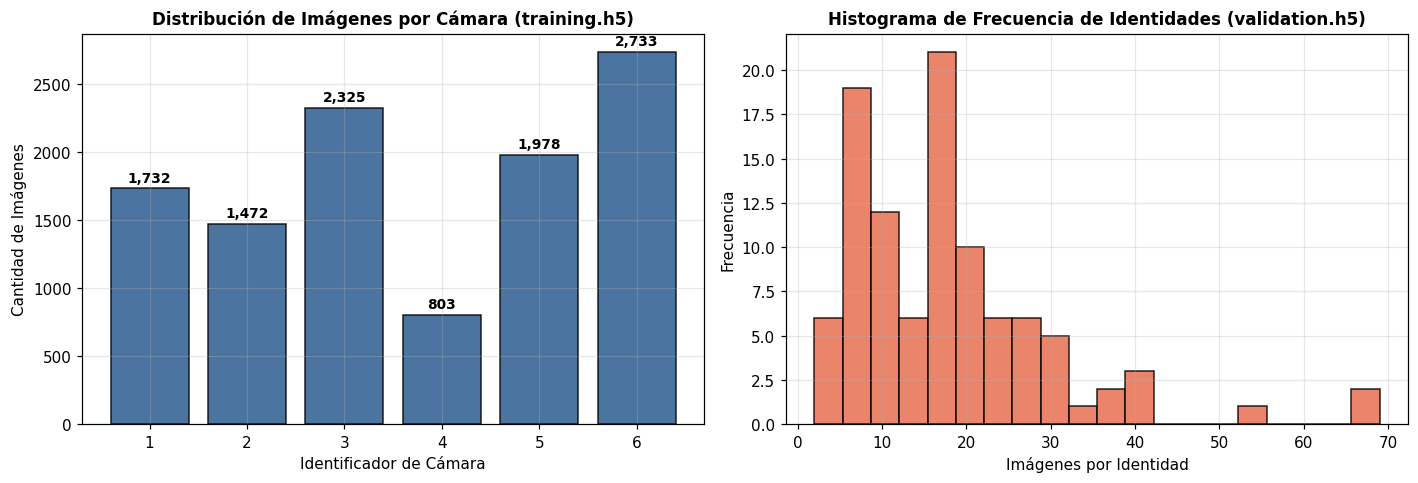

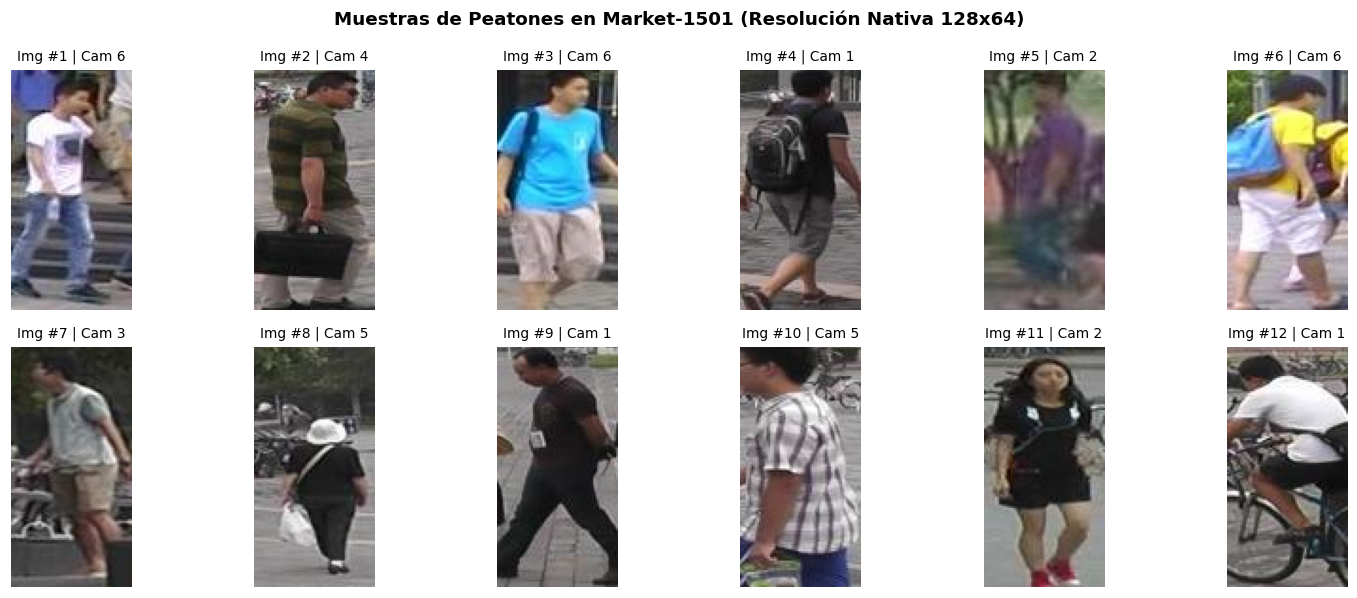

In [62]:
# Visualizaciones exploratorias del dataset Market-1501
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot 1: Distribución de imágenes por cámara en entrenamiento
cam_ids, cam_counts = np.unique(train_cams, return_counts=True)
axes[0].bar(cam_ids, cam_counts, color='#2b5c8f', edgecolor='black', alpha=0.85)
axes[0].set_title("Distribución de Imágenes por Cámara (training.h5)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Identificador de Cámara")
axes[0].set_ylabel("Cantidad de Imágenes")
for c, cnt in zip(cam_ids, cam_counts):
    axes[0].text(c, cnt + 50, f"{cnt:,}", ha='center', fontsize=9, fontweight='bold')

# Plot 2: Distribución de imágenes por identidad en galería de validación
val_pids_valid = val_g_pids[val_g_pids > 0]
unique_p, p_counts = np.unique(val_pids_valid, return_counts=True)
axes[1].hist(p_counts, bins=20, color='#e76f51', edgecolor='black', alpha=0.85)
axes[1].set_title("Histograma de Frecuencia de Identidades (validation.h5)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Imágenes por Identidad")
axes[1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.savefig(DIR_FIGS / 'distribucion_datos_eda.png', dpi=150, bbox_inches='tight')
plt.show()

# Visualización de muestras de peatones en resolución original
fig, ax = plt.subplots(2, 6, figsize=(14, 5.5))
fig.suptitle("Muestras de Peatones en Market-1501 (Resolución Nativa 128x64)", fontsize=12, fontweight='bold')
for i in range(12):
    row, col = i // 6, i % 6
    img = train_images[i].transpose(1, 2, 0)
    ax[row, col].imshow(img)
    ax[row, col].set_title(f"Img #{i+1} | Cam {train_cams[i]}", fontsize=9)
    ax[row, col].axis('off')
plt.tight_layout()
plt.savefig(DIR_FIGS / 'muestras_entrenamiento.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 5. Preprocesamiento y Pipeline de Aumentaciones para Re-ID

### Tamaño y Normalización
- **Resolución:** 256×128 (alto × ancho), acorde a la silueta peatonal.
- **Normalización:** medias y desviaciones de ImageNet ($\mu = [0.485, 0.456, 0.406]$, $\sigma = [0.229, 0.224, 0.225]$).

### Aumentaciones en GPU por Lote
Transformaciones aleatorias por lote (iguales para maestro y estudiantes):
1. **Volteo horizontal ($p = 0.5$):** simula peatones en sentido opuesto.
2. **Padding con reflexión (16 px) y recorte a 256×128:** tolerancia al encuadre del detector.
3. **Variación de brillo y color ($\times[0.8, 1.2]$):** simula cambios de luz entre cámaras.
4. **Borrado aleatorio ($p = 0.4$, zona de 20% × 25%):** simula oclusiones por mochilas u objetos.
5. **Degradación a 32×16 ($p = 0.3$) y reescalado a 256×128:** prepara al modelo para consultas de baja resolución.


In [63]:
def batch_augment(x, pad=16):
    '''
    Aumentaciones vectorizadas aplicadas directamente al lote de imágenes [B, 3, 256, 128]
    en escala float [0, 1] antes de la normalización ImageNet.
    '''
    B, C, H, W = x.shape
    x_aug = x.clone()
    
    # 1. Flip horizontal aleatorio
    flip_mask = torch.rand(B, device=x.device) > 0.5
    if flip_mask.any():
        x_aug[flip_mask] = torch.flip(x_aug[flip_mask], dims=[-1])
        
    # 2. Reflection Pad + Random Crop
    if pad > 0:
        x_pad = F.pad(x_aug, (pad, pad, pad, pad), mode='reflect')
        crop_h = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
        crop_w = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
        crops = [x_pad[i:i+1, :, crop_h[i]:crop_h[i]+H, crop_w[i]:crop_w[i]+W] for i in range(B)]
        x_aug = torch.cat(crops, dim=0)
        
    # 3. Perturbación de brillo/color inter-cámara
    jitter = 0.8 + 0.4 * torch.rand(B, 1, 1, 1, device=x.device)
    x_aug = torch.clamp(x_aug * jitter, 0.0, 1.0)
    
    # 4. Random Erasing (Cutout) para oclusiones
    erase_mask = torch.rand(B, device=x.device) < 0.4
    if erase_mask.any():
        eh, ew = int(H * 0.20), int(W * 0.25)
        for i in torch.where(erase_mask)[0]:
            y0 = torch.randint(0, H - eh, (1,)).item()
            x0 = torch.randint(0, W - ew, (1,)).item()
            x_aug[i, :, y0:y0+eh, x0:x0+ew] = 0.5
            
    # 5. Degradación multiescala aleatoria a 32x16
    low_res_mask = torch.rand(B, device=x.device) < 0.3
    if low_res_mask.any():
        sub_x = x_aug[low_res_mask]
        down = F.interpolate(sub_x, size=(32, 16), mode='bilinear', align_corners=False)
        up = F.interpolate(down, size=(H, W), mode='bilinear', align_corners=False)
        x_aug[low_res_mask] = up
        
    return x_aug

def normalize_imagenet(x):
    '''Aplica normalización estándar de ImageNet sobre un lote de imágenes en GPU'''
    mean = torch.tensor([0.485, 0.456, 0.406], device=x.device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=x.device).view(1, 3, 1, 1)
    return (x - mean) / std

def denormalize_imagenet(x):
    '''Revierte la normalización de ImageNet para visualización'''
    mean = torch.tensor([0.485, 0.456, 0.406], device=x.device).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225], device=x.device).view(1, 3, 1, 1)
    return torch.clamp(x * std + mean, 0.0, 1.0)

print("Pipeline de aumentaciones vectorizadas y normalización ImageNet compilado.")


Pipeline de aumentaciones vectorizadas y normalización ImageNet compilado.


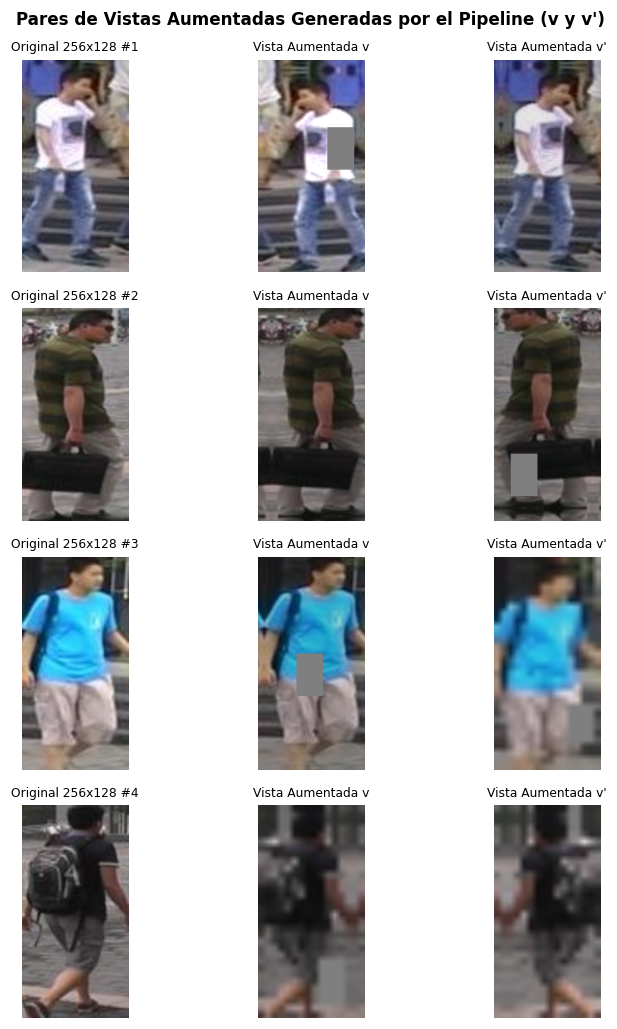

In [64]:
# Verificación visual de aumentaciones sobre un lote real
dummy_sample = torch.from_numpy(train_images[:4]).float() / 255.0
dummy_sample = F.interpolate(dummy_sample, size=(256, 128), mode='bilinear', align_corners=False).to(DEVICE)

v1 = batch_augment(dummy_sample)
v2 = batch_augment(dummy_sample)

fig, axes = plt.subplots(4, 3, figsize=(7.5, 9.5))
for i in range(4):
    axes[i, 0].imshow(dummy_sample[i].cpu().permute(1, 2, 0))
    axes[i, 0].set_title(f"Original 256x128 #{i+1}", fontsize=8)
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(v1[i].cpu().permute(1, 2, 0))
    axes[i, 1].set_title(f"Vista Aumentada v", fontsize=8)
    axes[i, 1].axis('off')
    
    axes[i, 2].imshow(v2[i].cpu().permute(1, 2, 0))
    axes[i, 2].set_title(f"Vista Aumentada v'", fontsize=8)
    axes[i, 2].axis('off')

plt.suptitle("Pares de Vistas Aumentadas Generadas por el Pipeline (v y v')", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(DIR_FIGS / 'pares_aumentados_verificacion.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 6. Arquitecturas Neuronales (Maestro MoCo-v2, Estudiante ResNet-18, Adaptador)

### 6.1 Maestro: ResNet-50 MoCo-v2 (800 Épocas)
- Encoder visual $f_t$: ResNet-50 sin `fc`, produce $z_t \in \mathbb{R}^{2048}$ tras GAP.
- Proyector $g_t$: MLP $2048 \to 2048 \to 128$ (`encoder_q.fc`).
- En la etapa 2, maestro y cabeza quedan congelados (`requires_grad = False`, `eval()`).

### 6.2 Estudiante: ResNet-18 desde Cero
- ResNet-18 sin pesos preentrenados (`weights=None`) con `fc = Identity()`; entrega $z_s \in \mathbb{R}^{512}$ tras GAP para evaluar Re-ID.
- **Adaptador (Apéndice D):** Conv 1×1 ($512 \to 2048$) con BatchNorm y ReLU sobre el mapa de `layer4` antes del GAP. Luego GAP ($2048$) y la cabeza congelada $g_t$ ($128$).

### 6.3 Mantener el maestro siempre en modo eval()
Sobrescribimos `train(mode=True)` en `RETROModel` para forzar que `teacher` y `proj_head` sigan en `eval()` y su BatchNorm no cambie.


In [65]:
class ResNet18Student(nn.Module):
    '''
    Estudiante ResNet-18 para Re-ID.
    Permite extraer el vector de evaluación z_s (512d tras GAP) y el mapa de características de layer4.
    '''
    def __init__(self, init='scratch'):
        super().__init__()
        if init == 'scratch':
            self.backbone = models.resnet18(weights=None)
        elif init == 'imagenet':
            self.backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        else:
            raise ValueError(f"Inicialización no reconocida: {init}")
        self.backbone.fc = nn.Identity()
        self.feat_dim = 512

    def forward(self, x, return_map=False):
        x = self.backbone.conv1(x)
        x = self.backbone.bn1(x)
        x = self.backbone.relu(x)
        x = self.backbone.maxpool(x)
        
        x = self.backbone.layer1(x)
        x = self.backbone.layer2(x)
        x = self.backbone.layer3(x)
        fmap = self.backbone.layer4(x)  # [B, 512, H/32, W/32] -> [B, 512, 8, 4]
        
        z = torch.flatten(self.backbone.avgpool(fmap), 1)  # [B, 512]
        if return_map:
            return z, fmap
        return z

class AdapterAppendixD(nn.Module):
    '''
    Adaptador del Apéndice D (Paper RETRO):
    Conv 1x1 (512 -> 2048) + BatchNorm2d + ReLU sobre el feature map de layer4 antes de GAP.
    Posteriormente aplica GAP para entregar un vector de 2048 dimensiones a la cabeza gt.
    '''
    def __init__(self, in_channels=512, out_channels=2048):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

    def forward(self, fmap):
        out = self.relu(self.bn(self.conv(fmap)))  # [B, 2048, H, W]
        out = self.pool(out)                       # [B, 2048, 1, 1]
        return torch.flatten(out, 1)               # [B, 2048]

class ProjectionHeadMLP(nn.Module):
    '''Cabeza de proyección MLP independiente (para baseline y ablación DisCo)'''
    def __init__(self, in_dim=512, hidden_dim=2048, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, out_dim)
        )
    def forward(self, x):
        return F.normalize(self.net(x), p=2, dim=-1)

def load_official_moco_teacher(ckpt_path, device):
    '''
    Carga los pesos oficiales de MoCo-v2 (ResNet-50 800 épocas en ImageNet).
    Separa encoder_q (backbone 2048d) y encoder_q.fc (cabeza de proyección gt 128d).
    '''
    print(f"Cargando checkpoint MoCo-v2 desde: {ckpt_path}")
    state = torch.load(ckpt_path, map_location='cpu')
    sd = state.get('state_dict', state)
    
    teacher_encoder = models.resnet50(weights=None)
    teacher_encoder.fc = nn.Identity()
    
    teacher_proj = nn.Sequential(
        nn.Linear(2048, 2048),
        nn.ReLU(inplace=True),
        nn.Linear(2048, 128)
    )
    
    enc_sd = {}
    proj_sd = {}
    
    for k, v in sd.items():
        if k.startswith('module.encoder_q.'):
            sub_k = k[len('module.encoder_q.'):]
            if sub_k.startswith('fc.'):
                proj_k = sub_k[len('fc.'):]
                proj_sd[proj_k] = v
            else:
                enc_sd[sub_k] = v
                
    missing_enc, unexp_enc = teacher_encoder.load_state_dict(enc_sd, strict=False)
    missing_proj, unexp_proj = teacher_proj.load_state_dict(proj_sd, strict=True)
    
    print(f"[MoCo-v2 Encoder] Claves cargadas: {len(enc_sd)} | Faltantes (esperado fc): {missing_enc} | Inesperadas: {unexp_enc}")
    print(f"[MoCo-v2 Head gt] Claves cargadas: {len(proj_sd)} | Faltantes: {missing_proj} | Inesperadas: {unexp_proj}")
    
    for p in teacher_encoder.parameters():
        p.requires_grad = False
    for p in teacher_proj.parameters():
        p.requires_grad = False
        
    teacher_encoder.eval().to(device)
    teacher_proj.eval().to(device)
    return teacher_encoder, teacher_proj

class RETROModel(nn.Module):
    '''
    Marco unificado para RETRO, Baseline y Ablaciones.
    Soporta reutilización de cabeza gt, cabeza separada, actualización EMA y colas de memoria.
    '''
    def __init__(self, student, teacher, proj_head, adapter=None, reuse_proj=True, K=4096, dim=128):
        super().__init__()
        self.student = student
        self.teacher = teacher
        self.proj_head = proj_head
        self.reuse_proj = reuse_proj
        self.adapter = adapter
        self.K = K
        self.dim = dim
        
        if not self.reuse_proj:
            self.student_proj = ProjectionHeadMLP(in_dim=512, hidden_dim=2048, out_dim=dim)
        else:
            self.student_proj = None

        self.mean_student = ResNet18Student(init='scratch')
        self.mean_student.load_state_dict(self.student.state_dict())
        for p in self.mean_student.parameters():
            p.requires_grad = False
            
        if self.reuse_proj and self.adapter is not None:
            self.mean_adapter = AdapterAppendixD(512, 2048)
            self.mean_adapter.load_state_dict(self.adapter.state_dict())
            for p in self.mean_adapter.parameters():
                p.requires_grad = False
        elif not self.reuse_proj:
            self.mean_student_proj = ProjectionHeadMLP(in_dim=512, hidden_dim=2048, out_dim=dim)
            self.mean_student_proj.load_state_dict(self.student_proj.state_dict())
            for p in self.mean_student_proj.parameters():
                p.requires_grad = False
        else:
            self.mean_adapter = None

        self.register_buffer("queue1", torch.randn(dim, K))
        self.register_buffer("queue2", torch.randn(dim, K))
        self.queue1 = F.normalize(self.queue1, p=2, dim=0)
        self.queue2 = F.normalize(self.queue2, p=2, dim=0)
        self.register_buffer("queue_ptr", torch.zeros(1, dtype=torch.long))

    def train(self, mode=True):
        '''
        Sobrescritura de train(): Garantiza que el docente y su cabeza gt
        permanezcan estrictamente en eval() para que BatchNorm no mute.
        '''
        super().train(mode)
        if self.teacher is not None:
            self.teacher.eval()
        if self.proj_head is not None:
            self.proj_head.eval()
        return self

    @torch.no_grad()
    def update_mean_student(self, m=0.99):
        for p_s, p_m in zip(self.student.parameters(), self.mean_student.parameters()):
            p_m.data = m * p_m.data + (1.0 - m) * p_s.data
            
        if self.reuse_proj and self.adapter is not None:
            for p_s, p_m in zip(self.adapter.parameters(), self.mean_adapter.parameters()):
                p_m.data = m * p_m.data + (1.0 - m) * p_s.data
        elif not self.reuse_proj and self.student_proj is not None:
            for p_s, p_m in zip(self.student_proj.parameters(), self.mean_student_proj.parameters()):
                p_m.data = m * p_m.data + (1.0 - m) * p_s.data

    @torch.no_grad()
    def dequeue_and_enqueue(self, keys1, keys2):
        batch_size = keys1.shape[0]
        ptr = int(self.queue_ptr)
        
        if ptr + batch_size <= self.K:
            self.queue1[:, ptr:ptr + batch_size] = keys1.T
            self.queue2[:, ptr:ptr + batch_size] = keys2.T
        else:
            rem = self.K - ptr
            self.queue1[:, ptr:] = keys1[:rem].T
            self.queue1[:, :batch_size - rem] = keys1[rem:].T
            self.queue2[:, ptr:] = keys2[:rem].T
            self.queue2[:, :batch_size - rem] = keys2[rem:].T
            
        self.queue_ptr[0] = (ptr + batch_size) % self.K

    def forward(self, v1, v2):
        z_s1, fmap1 = self.student(v1, return_map=True)
        z_s2, fmap2 = self.student(v2, return_map=True)
        
        if self.reuse_proj:
            feat_a1 = self.adapter(fmap1)
            feat_a2 = self.adapter(fmap2)
            e_s1 = F.normalize(self.proj_head(feat_a1), p=2, dim=-1)
            e_s2 = F.normalize(self.proj_head(feat_a2), p=2, dim=-1)
        else:
            e_s1 = self.student_proj(z_s1)
            e_s2 = self.student_proj(z_s2)

        with torch.no_grad():
            if self.teacher is not None:
                z_t1 = self.teacher(v1)
                z_t2 = self.teacher(v2)
                e_t1 = F.normalize(self.proj_head(z_t1), p=2, dim=-1)
                e_t2 = F.normalize(self.proj_head(z_t2), p=2, dim=-1)
            else:
                e_t1, e_t2 = None, None

            z_m1, fmap_m1 = self.mean_student(v1, return_map=True)
            z_m2, fmap_m2 = self.mean_student(v2, return_map=True)
            
            if self.reuse_proj:
                feat_am1 = self.mean_adapter(fmap_m1)
                feat_am2 = self.mean_adapter(fmap_m2)
                e_m1 = F.normalize(self.proj_head(feat_am1), p=2, dim=-1)
                e_m2 = F.normalize(self.proj_head(feat_am2), p=2, dim=-1)
            else:
                e_m1 = self.mean_student_proj(z_m1)
                e_m2 = self.mean_student_proj(z_m2)

        return (e_s1, e_s2), (e_t1, e_t2), (e_m1, e_m2), (z_s1, z_s2)

print("Clases ResNet18Student, AdapterAppendixD y RETROModel compiladas exitosamente.")


Clases ResNet18Student, AdapterAppendixD y RETROModel compiladas exitosamente.


In [66]:
# Carga del maestro original MoCo-v2 (ImageNet) y conservación separada
teacher_enc_imagenet, teacher_g_imagenet = load_official_moco_teacher(MOCO_CKPT_PATH, DEVICE)

# Por defecto, antes de la adaptación, teacher_enc y teacher_g apuntan a los pesos originales
teacher_enc = teacher_enc_imagenet
teacher_g = teacher_g_imagenet

stud_test = ResNet18Student(init=STUDENT_INIT).to(DEVICE)
adapt_test = AdapterAppendixD(512, 2048).to(DEVICE)
retro_test = RETROModel(stud_test, teacher_enc, teacher_g, adapter=adapt_test, reuse_proj=True).to(DEVICE)

# Conteo formal de parámetros (claramente desglosados para inferencia y entrenamiento)
n_stud_enc = sum(p.numel() for p in stud_test.parameters())
n_teach_enc = sum(p.numel() for p in teacher_enc_imagenet.parameters())
n_adapt_tot = sum(p.numel() for p in adapt_test.parameters())
n_retro_train = sum(p.numel() for p in retro_test.parameters() if p.requires_grad)

print("\n" + "="*70)
print("TABLA FORMAL DE PARÁMETROS Y DIMENSIONES")
print("="*70)
print(f"| Componente | Paráms Inferencia | Paráms Entrenables | Salida |")
print(f"|---|---|---|---|")
print(f"| Maestro MoCo-v2 (ResNet-50)       | {n_teach_enc:,} | 0 (Congelado en Etapa 2) | [B, 2048] (GAP layer4) |")
print(f"| Estudiante (Encoder ResNet-18)    | {n_stud_enc:,} | {n_stud_enc:,} | [B, 512] (GAP layer4) |")
print(f"| Adaptador Apéndice D (Conv 1x1)    | N/A (Solo train) | {n_adapt_tot:,} | [B, 2048] |")
print(f"| RETRO Completo (Total Entrenable)  | {n_stud_enc:,} | {n_retro_train:,} | [B, 128] |")
print(f"Ratio Estudiante/Maestro en inferencia: {n_stud_enc / n_teach_enc * 100:.2f}% de parámetros.")
print("="*70)

dummy_x1 = torch.randn(4, 3, 256, 128, device=DEVICE)
dummy_x2 = torch.randn(4, 3, 256, 128, device=DEVICE)
(es1, es2), (et1, et2), (em1, em2), (zs1, zs2) = retro_test(dummy_x1, dummy_x2)

print("Verificación de Dimensiones (Forward Pass exitoso):")
print(f"  - Vector de Evaluación z_s : {zs1.shape} (Esperado: [4, 512])")
print(f"  - Incrustación Estudiante Es: {es1.shape} (Esperado: [4, 128])")
print(f"  - Incrustación Docente Et   : {et1.shape} (Esperado: [4, 128])")
print(f"  - Incrustación Mean Student : {em1.shape} (Esperado: [4, 128])")


Cargando checkpoint MoCo-v2 desde: moco_v2_800ep_pretrain.pth.tar
[MoCo-v2 Encoder] Claves cargadas: 318 | Faltantes (esperado fc): [] | Inesperadas: []
[MoCo-v2 Head gt] Claves cargadas: 4 | Faltantes: [] | Inesperadas: []

TABLA FORMAL DE PARÁMETROS Y DIMENSIONES
| Componente | Paráms Inferencia | Paráms Entrenables | Salida |
|---|---|---|---|
| Maestro MoCo-v2 (ResNet-50)       | 23,508,032 | 0 (Congelado en Etapa 2) | [B, 2048] (GAP layer4) |
| Estudiante (Encoder ResNet-18)    | 11,176,512 | 11,176,512 | [B, 512] (GAP layer4) |
| Adaptador Apéndice D (Conv 1x1)    | N/A (Solo train) | 1,052,672 | [B, 2048] |
| RETRO Completo (Total Entrenable)  | 11,176,512 | 12,229,184 | [B, 128] |
Ratio Estudiante/Maestro en inferencia: 47.54% de parámetros.
Verificación de Dimensiones (Forward Pass exitoso):
  - Vector de Evaluación z_s : torch.Size([4, 512]) (Esperado: [4, 512])
  - Incrustación Estudiante Es: torch.Size([4, 128]) (Esperado: [4, 128])
  - Incrustación Docente Et   : torch.Siz

---
## 7. Funciones de Pérdida y Colas de Negativos

### 1. Pérdida de Consistencia / Destilación ($\mathcal{L}_{dis}$)
$$\mathcal{L}_{dis} = \|E_s - E_t\|_2^2 + \|E'_s - E'_t\|_2^2$$
Distancia euclidiana al cuadrado entre embeddings normalizados en la esfera unitaria.

### 2. Pérdida Contrastiva Simétrica MoCo ($\mathcal{L}_{con}$)
Dos colas de memoria ($Q_1$ y $Q_2$) con $K = 4096$ negativos y $\tau = 0.2$:
- Para $E_s$, el positivo es $E'_m$ y los negativos salen de $Q_2$.
- Para $E'_s$, el positivo es $E_m$ y los negativos salen de $Q_1$.


In [67]:
def distillation_loss(es1, et1, es2, et2):
    '''Pérdida de consistencia: MSE en esfera unitaria entre estudiante y docente'''
    l1 = torch.mean(torch.sum((es1 - et1)**2, dim=1))
    l2 = torch.mean(torch.sum((es2 - et2)**2, dim=1))
    return l1 + l2

def contrastive_loss_moco(q1, k1_pos, queue1, q2, k2_pos, queue2, tau=0.2):
    '''
    Pérdida contrastiva simétrica MoCo con temperatura tau=0.2.
    Utiliza queue.clone() para garantizar seguridad de gradientes.
    '''
    # Rama 1: q1 frente a k1_pos (de em2) y negativos de queue1 (de Q2)
    l_pos1 = torch.sum(q1 * k1_pos, dim=1, keepdim=True) # [B, 1]
    l_neg1 = torch.mm(q1, queue1.clone())                # [B, K]
    logits1 = torch.cat([l_pos1, l_neg1], dim=1) / tau
    labels1 = torch.zeros(logits1.shape[0], dtype=torch.long, device=logits1.device)
    loss1 = F.cross_entropy(logits1, labels1)
    
    # Rama 2: q2 frente a k2_pos (de em1) y negativos de queue2 (de Q1)
    l_pos2 = torch.sum(q2 * k2_pos, dim=1, keepdim=True) # [B, 1]
    l_neg2 = torch.mm(q2, queue2.clone())                # [B, K]
    logits2 = torch.cat([l_pos2, l_neg2], dim=1) / tau
    labels2 = torch.zeros(logits2.shape[0], dtype=torch.long, device=logits2.device)
    loss2 = F.cross_entropy(logits2, labels2)
    
    return 0.5 * (loss1 + loss2)

print("Funciones de pérdida de consistencia y contrastiva simétrica compiladas.")


Funciones de pérdida de consistencia y contrastiva simétrica compiladas.


---
## 8. Protocolo de Evaluación (Market-1501 CMC y mAP)

Seguimos las reglas de evaluación de Market-1501:
- Calculamos la similitud coseno entre características normalizadas de consultas y galería.
- Para cada consulta, ordenamos la galería de mayor a menor similitud.
- **Basura (*junk*):** omitimos imágenes de la misma persona en la misma cámara (`pid == q_pid` y `cam == q_cam`) o sin identificar (`pid == -1`).
- **Distractores (`pid == 0`):** se conservan en la galería como negativos difíciles.


In [68]:
def evaluate_market1501(q_feats, g_feats, q_pids, g_pids, q_cams, g_cams, max_rank=10):
    '''
    Evaluación rigurosa de Market-1501: calcula mAP y curva CMC (Rank-1 a max_rank).
    Filtra junk (pid == -1 o misma persona y misma cámara); retiene distractores pid == 0.
    '''
    q_feats = F.normalize(q_feats, p=2, dim=1)
    g_feats = F.normalize(g_feats, p=2, dim=1)
    sim_mat = torch.mm(q_feats, g_feats.t()).cpu().numpy()
    
    q_pids = np.asarray(q_pids)
    g_pids = np.asarray(g_pids)
    q_cams = np.asarray(q_cams)
    g_cams = np.asarray(g_cams)
    
    num_q = len(q_pids)
    all_cmc = []
    all_AP = []
    
    for i in range(num_q):
        qp, qc = q_pids[i], q_cams[i]
        sims = sim_mat[i]
        order = np.argsort(-sims)
        
        # Máscaras canónicas de Market-1501
        junk_mask = ((g_pids[order] == qp) & (g_cams[order] == qc)) | (g_pids[order] == -1)
        valid_order = order[~junk_mask]
        
        matches = (g_pids[valid_order] == qp)
        n_pos = np.sum(matches)
        if n_pos == 0:
            continue
            
        # Cálculo de AP (Average Precision)
        cum_matches = np.cumsum(matches)
        ranks = np.arange(1, len(matches) + 1)
        precision_at_k = cum_matches / ranks
        AP = np.sum(precision_at_k * matches) / n_pos
        all_AP.append(AP)
        
        # CMC (Cumulative Matching Characteristics)
        cmc = np.zeros(max_rank)
        first_match = np.where(matches)[0]
        if len(first_match) > 0 and first_match[0] < max_rank:
            cmc[first_match[0]:] = 1.0
        all_cmc.append(cmc)
        
    mAP = float(np.mean(all_AP)) if len(all_AP) > 0 else 0.0
    cmc = np.mean(all_cmc, axis=0) if len(all_cmc) > 0 else np.zeros(max_rank)
    
    return {
        'mAP': mAP,
        'Rank-1': float(cmc[0]),
        'Rank-5': float(cmc[4]) if max_rank >= 5 else 0.0,
        'Rank-10': float(cmc[9]) if max_rank >= 10 else 0.0,
        'cmc': cmc.tolist()
    }

@torch.no_grad()
def extract_features(model, dataloader, device, is_teacher=False):
    '''Extrae el vector de evaluación z normalizado L2 para Re-ID (512d estudiante, 2048d maestro)'''
    model.eval()
    feats = []
    for imgs in dataloader:
        imgs = imgs.to(device)
        imgs = normalize_imagenet(imgs)
        if is_teacher:
            f = model(imgs) # ResNet-50 GAP: [B, 2048]
        else:
            if hasattr(model, 'student'):
                f = model.student(imgs) # ResNet-18 GAP: [B, 512]
            else:
                f = model(imgs)
        feats.append(f.cpu())
    return torch.cat(feats, dim=0)

print("Protocolo canónico de evaluación Market-1501 compilado exitosamente.")


Protocolo canónico de evaluación Market-1501 compilado exitosamente.


---
## 9. DataLoaders para Entrenamiento y Evaluación

Construimos los DataLoaders con imágenes reescaladas a 256×128:
- **`TrainDataset`:** 11,043 imágenes de `training.h5` para entrenamiento.
- **`EvalDataset`:** maneja consultas normales (128×64 $\to$ 256×128), consultas de baja resolución (32×16 $\to$ 256×128) e imágenes de galería.


In [69]:
class TrainDataset(Dataset):
    '''Dataset para entrenamiento auto-supervisado en 256x128'''
    def __init__(self, images):
        self.images = images
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        img = torch.from_numpy(self.images[idx]).float() / 255.0
        img_256 = F.interpolate(img.unsqueeze(0), size=(256, 128), mode='bilinear', align_corners=False).squeeze(0)
        return img_256

class EvalDataset(Dataset):
    '''Dataset para evaluación canónica con reescalado uniforme a 256x128'''
    def __init__(self, images, is_low_res=False):
        self.images = images
        self.is_low_res = is_low_res
    def __len__(self):
        return len(self.images)
    def __getitem__(self, idx):
        img = torch.from_numpy(self.images[idx]).float() / 255.0
        img_256 = F.interpolate(img.unsqueeze(0), size=(256, 128), mode='bilinear', align_corners=False).squeeze(0)
        return img_256

train_dataset = TrainDataset(train_images)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, pin_memory=(DEVICE.type=='cuda'), num_workers=2)

val_q_loader = DataLoader(EvalDataset(val_q_images, is_low_res=False), batch_size=BATCH_SIZE, shuffle=False)
val_q_low_loader = DataLoader(EvalDataset(val_q_low_images, is_low_res=True), batch_size=BATCH_SIZE, shuffle=False)
val_g_loader = DataLoader(EvalDataset(val_g_images, is_low_res=False), batch_size=BATCH_SIZE, shuffle=False)

print(f"DataLoaders listos: Lotes de entrenamiento = {len(train_loader)} batches ({len(train_dataset):,} imágenes).")


DataLoaders listos: Lotes de entrenamiento = 86 batches (11,043 imágenes).


---
## 10. Adaptación del Maestro a Market-1501 (MoCo-v2, sin etiquetas)

### 10.1 Fundamento y Arquitectura de la Etapa 1b
Para adaptar el maestro a peatones, continuamos **MoCo-v2** sobre las 11,043 imágenes de `training.h5` sin etiquetas:
1. **Encoder de consulta:** ResNet-50 ($f_t$) con proyector MLP ($g_t$, $2048 \to 2048 \to 128$) inicializados de MoCo-v2 en ImageNet. Solo se entrenan en esta etapa.
2. **Encoder de claves (EMA):** copia del encoder actualizada por promedio móvil con momento $m = 0.99$:
   $$\theta_k \leftarrow 0.99 \cdot \theta_k + 0.01 \cdot \theta_q$$
   **Por qué $m = 0.99$:** con batch 128 cada época tiene solo $\approx 86$ pasos. El valor clásico $m = 0.999$ actualizaría las claves muy lento ($0.999^{86} \approx 0.917$ retención por época); $m = 0.99$ ($0.99^{86} \approx 0.421$) permite que evolucionen al ritmo de los datos.
3. **Cola de memoria y pérdida InfoNCE:** cola circular de $K = 4096$ negativos con $\tau = 0.2$, optimizada con SGD (momento 0.9, weight decay $10^{-4}$), tasa $lr = 0.0015$ con warmup lineal en la época 1, CosineAnnealing después, recorte de gradiente (`clip_grad_norm_`, máx. 5.0) y un detector de colapso (si la pérdida supera $0.98\cdot\ln(K+1)$ o la dispersión $q_{std} < 10^{-3}$ por dos épocas seguidas, se detiene).
   **Lección del primer intento:** con $lr = 0.015$ la adaptación colapsó: la pérdida quedó fija en $8.32 \approx \ln(4097)$, lo que indica que el modelo producía embeddings idénticos para todas las imágenes (el InfoNCE no distingue el positivo de los 4,096 negativos). Bajar el learning rate 10 veces y añadir warmup y recorte eliminó el colapso: la pérdida bajó de 6.34 a 3.72 y $q_{std}$ se mantuvo estable en ≈0.088 durante las 40 épocas.
4. **Validación periódica:** al final de cada época evaluamos el maestro en validación ($z_t \in \mathbb{R}^{2048}$) y guardamos el mejor checkpoint por mAP (`teacher_adapt_bs128_ep{EPOCHS_TEACHER}_best.pt`).
5. **Congelamiento posterior:** al terminar, cargamos el mejor checkpoint y congelamos todos sus parámetros (`requires_grad = False`, `eval()`).


In [70]:
class MoCoTeacherAdaptor(nn.Module):
    '''
    Módulo para la Etapa 1b: Adaptación de MoCo-v2 sobre Market-1501 sin etiquetas.
    - encoder_q: ResNet-50 + proyector MLP (2048->2048->128) cargados de MoCo-v2 oficial.
    - encoder_k: Copia EMA del codificador de consulta.
    - queue: Cola circular FIFO de K=4096 vectores negativos (dim 128).
    '''
    def __init__(self, base_encoder, base_proj, K=4096, m=0.99, T=0.2):
        super().__init__()
        self.K = K
        self.m = m
        self.T = T
        
        # Codificador de consulta (q) - entrenable en esta etapa
        self.encoder_q = base_encoder
        self.proj_q = base_proj
        for p in self.encoder_q.parameters():
            p.requires_grad = True
        for p in self.proj_q.parameters():
            p.requires_grad = True
            
        # Codificador de claves (k) - actualizado exclusivamente por EMA
        self.encoder_k = models.resnet50(weights=None)
        self.encoder_k.fc = nn.Identity()
        self.encoder_k.load_state_dict(self.encoder_q.state_dict())
        
        self.proj_k = nn.Sequential(
            nn.Linear(2048, 2048),
            nn.ReLU(inplace=True),
            nn.Linear(2048, 128)
        )
        self.proj_k.load_state_dict(self.proj_q.state_dict())
        
        for p in self.encoder_k.parameters():
            p.requires_grad = False
        for p in self.proj_k.parameters():
            p.requires_grad = False
            
        # Cola de memoria de negativos
        self.register_buffer("queue", torch.randn(128, K))
        self.queue = F.normalize(self.queue, p=2, dim=0)
        self.register_buffer("queue_ptr", torch.zeros(1, dtype=torch.long))

    @torch.no_grad()
    def update_key_encoder(self):
        '''Actualización por momento (EMA) del codificador de claves: theta_k = m*theta_k + (1-m)*theta_q'''
        for p_q, p_k in zip(self.encoder_q.parameters(), self.encoder_k.parameters()):
            p_k.data = self.m * p_k.data + (1.0 - self.m) * p_q.data
        for p_q, p_k in zip(self.proj_q.parameters(), self.proj_k.parameters()):
            p_k.data = self.m * p_k.data + (1.0 - self.m) * p_q.data

    @torch.no_grad()
    def dequeue_and_enqueue(self, keys):
        '''Actualiza la cola de negativos con los vectores de claves del lote actual (FIFO)'''
        batch_size = keys.shape[0]
        ptr = int(self.queue_ptr)
        
        if ptr + batch_size <= self.K:
            self.queue[:, ptr:ptr + batch_size] = keys.T
        else:
            rem = self.K - ptr
            self.queue[:, ptr:] = keys[:rem].T
            self.queue[:, :batch_size - rem] = keys[rem:].T
            
        self.queue_ptr[0] = (ptr + batch_size) % self.K

    def forward(self, im_q, im_k):
        '''Calcula las incrustaciones de consulta q y claves k, y la pérdida InfoNCE'''
        feat_q = self.encoder_q(im_q)
        q = F.normalize(self.proj_q(feat_q), p=2, dim=1)
        
        with torch.no_grad():
            feat_k = self.encoder_k(im_k)
            k = F.normalize(self.proj_k(feat_k), p=2, dim=1)
            
        l_pos = torch.einsum('nc,nc->n', [q, k]).unsqueeze(-1)
        l_neg = torch.einsum('nc,ck->nk', [q, self.queue.clone()])
        logits = torch.cat([l_pos, l_neg], dim=1) / self.T
        labels = torch.zeros(logits.shape[0], dtype=torch.long, device=logits.device)
        
        loss = F.cross_entropy(logits, labels)
        return loss, k

print("Clase MoCoTeacherAdaptor compilada exitosamente.")


Clase MoCoTeacherAdaptor compilada exitosamente.


In [71]:
# -------------------------------------------------------------------------
# PUNTO DE CONTROL 2A: SMOKE TEST DE LA ADAPTACIÓN DEL MAESTRO
# -------------------------------------------------------------------------
if RUN_SMOKE_TEST:
    print("\n" + "="*70)
    print("EJECUTANDO SMOKE TEST 1: ADAPTACIÓN DEL MAESTRO (1 Época, 512 imágenes)")
    print("="*70)
    
    smoke_loader = DataLoader(TrainDataset(train_images[:512]), batch_size=64, shuffle=False)
    
    # Instanciación temporal del adaptador del maestro
    temp_enc, temp_g = load_official_moco_teacher(MOCO_CKPT_PATH, DEVICE)
    moco_smoke = MoCoTeacherAdaptor(temp_enc, temp_g, K=512, m=0.99, T=0.2).to(DEVICE)
    moco_smoke.train()
    
    weights_before = [p.clone() for p in moco_smoke.encoder_q.parameters()]
    opt_smoke = torch.optim.SGD([p for p in moco_smoke.parameters() if p.requires_grad], lr=TEACHER_LR)
    
    smoke_q_holder = [None]
    def capture_smoke_q(module, inp, out):
        smoke_q_holder[0] = F.normalize(out, p=2, dim=1).detach()
    smoke_hook = moco_smoke.proj_q.register_forward_hook(capture_smoke_q)
    
    smoke_losses = []
    q_std_ini = None
    q_std_fin = None
    for idx, bx in enumerate(smoke_loader):
        bx = bx.to(DEVICE)
        v1 = normalize_imagenet(batch_augment(bx))
        v2 = normalize_imagenet(batch_augment(bx))
        loss, k = moco_smoke(v1, v2)
        if idx == 0 and smoke_q_holder[0] is not None:
            q_std_ini = smoke_q_holder[0].float().std(dim=0).mean().item()
        opt_smoke.zero_grad()
        loss.backward()
        opt_smoke.step()
        moco_smoke.update_key_encoder()
        moco_smoke.dequeue_and_enqueue(k)
        smoke_losses.append(loss.item())
        
    if smoke_q_holder[0] is not None:
        q_std_fin = smoke_q_holder[0].float().std(dim=0).mean().item()
    smoke_hook.remove()
        
    all_finite = all(math.isfinite(l) for l in smoke_losses)
    max_change_during = max((p_bef - p_cur).abs().max().item() for p_bef, p_cur in zip(weights_before, moco_smoke.encoder_q.parameters()))
    
    print(f"  -> Pérdidas InfoNCE registradas : {smoke_losses[0]:.4f} -> {smoke_losses[-1]:.4f}")
    print(f"  -> Diversidad q_std de embeddings: Inicial = {q_std_ini:.4f} | Final = {q_std_fin:.4f}")
    print(f"  -> ¿Pérdidas estrictamente finitas?: {'SÍ' if all_finite else 'NO'}")
    print(f"  -> Máxima variación en pesos durante adaptación: {max_change_during:.6f} (Debe ser > 0)")
    
    umbral_smoke = 0.98 * math.log(moco_smoke.K + 1)
    if smoke_losses[-1] > umbral_smoke or (q_std_fin is not None and q_std_fin < 1e-3):
        print(f"  -> [ADVERTENCIA]: Pérdida final ({smoke_losses[-1]:.4f} > {umbral_smoke:.4f}) o q_std ({q_std_fin:.4f} < 1e-3) indican posible colapso. Revisa TEACHER_LR.")
        
    assert all_finite and max_change_during > 0, "¡FALLO EN SMOKE TEST DEL MAESTRO!"
    print("[OK] El maestro aprende activamente: pérdidas finitas y pesos actualizados sin desbordamientos.")
    
    # Verificación de congelamiento posterior
    for p in moco_smoke.encoder_q.parameters(): p.requires_grad = False
    for p in moco_smoke.proj_q.parameters(): p.requires_grad = False
    moco_smoke.eval()
    
    post_freeze_weights = [p.clone() for p in moco_smoke.encoder_q.parameters()]
    dummy_x = torch.randn(4, 3, 256, 128, device=DEVICE)
    with torch.no_grad():
        _ = moco_smoke.encoder_q(dummy_x)
    max_post_change = max((p_bef - p_cur).abs().max().item() for p_bef, p_cur in zip(post_freeze_weights, moco_smoke.encoder_q.parameters()))
    print(f"  -> Variación tras congelar maestro: {max_post_change:.10f} (Debe ser 0.0)")
    assert max_post_change == 0.0, "¡ERROR! El maestro no quedó congelado."
    print("[SMOKE TEST 1 COMPLETADO EXITOSAMENTE]\n")

# -------------------------------------------------------------------------
# PUNTO DE CONTROL 2B: SMOKE TEST DE LAS VARIANTES DE RETRO
# -------------------------------------------------------------------------
if RUN_SMOKE_TEST:
    print("="*70)
    print("EJECUTANDO SMOKE TEST 2: VARIANTES DE RETRO (1 Época, 512 imágenes c/u)")
    print("="*70)
    
    variants = [
        ("RETRO Completo", True, True, True),
        ("Baseline (MoCo-v2 solo)", False, True, False),
        ("Ablación Cabeza Separada (DisCo)", True, True, False),
        ("Ablación Solo Destilación (gamma=0)", True, False, True),
    ]
    
    for v_name, use_dis, use_con, reuse_h in variants:
        st_test = ResNet18Student(init=STUDENT_INIT).to(DEVICE)
        ad_test = AdapterAppendixD(512, 2048).to(DEVICE) if reuse_h else None
        m_test = RETROModel(st_test, teacher_enc if use_dis else None, teacher_g if use_dis else None,
                            adapter=ad_test, reuse_proj=reuse_h).to(DEVICE)
        m_test.train()
        opt = torch.optim.SGD([p for p in m_test.parameters() if p.requires_grad], lr=0.01)
        
        hist_dis, hist_con, hist_total = [], [], []
        for bx in smoke_loader:
            bx = bx.to(DEVICE)
            v1 = normalize_imagenet(batch_augment(bx))
            v2 = normalize_imagenet(batch_augment(bx))
            (es1, es2), (et1, et2), (em1, em2), _ = m_test(v1, v2)
            
            l_dis = distillation_loss(es1, et1, es2, et2) if use_dis else None
            l_con = contrastive_loss_moco(es1, em2, m_test.queue2, es2, em1, m_test.queue1) if use_con else None
            
            if l_dis is not None and l_con is not None:
                loss = l_dis + l_con
            elif l_dis is not None:
                loss = l_dis
            else:
                loss = l_con
                
            opt.zero_grad()
            loss.backward()
            opt.step()
            m_test.update_mean_student(m=0.99)
            if use_con:
                m_test.dequeue_and_enqueue(em1, em2)
                
            hist_total.append(loss.item())
            if l_dis is not None: hist_dis.append(l_dis.item())
            if l_con is not None: hist_con.append(l_con.item())
            
        all_finite = all(math.isfinite(x) for x in hist_total)
        status = "OK" if all_finite else "REVISAR"
        dis_str = f"L_dis: {hist_dis[0]:.4f} -> {hist_dis[-1]:.4f}" if use_dis else "L_dis: N/A"
        con_str = f"L_con: {hist_con[0]:.4f} -> {hist_con[-1]:.4f}" if use_con else "L_con: N/A"
        print(f"  [{status}] {v_name:<36} | {dis_str} | {con_str} | Pérdidas finitas")
        
    print("[SMOKE TEST 2 COMPLETADO CON ÉXITO EN TODAS LAS VARIANTES]\n")


In [72]:
# -------------------------------------------------------------------------
# PUNTO DE CONTROL 3: MEDICIÓN EMPÍRICA Y PLAN DE ÉPOCAS (T4 <= 4.5 HORAS TOTAL)
# -------------------------------------------------------------------------
print("Midiendo tiempos reales por época en la GPU T4 activa...")

# 1. Medición para adaptación del maestro MoCo-v2 (ResNet-50)
bench_enc, bench_g = load_official_moco_teacher(MOCO_CKPT_PATH, DEVICE)
moco_bench = MoCoTeacherAdaptor(bench_enc, bench_g, K=BATCH_SIZE*4).to(DEVICE)
moco_bench.train()
opt_moco = torch.optim.SGD([p for p in moco_bench.parameters() if p.requires_grad], lr=0.015)
scaler_bench = torch.cuda.amp.GradScaler(enabled=USE_AMP)

t0 = time.time()
for b_idx, bx in enumerate(train_loader):
    bx = bx.to(DEVICE)
    with torch.cuda.amp.autocast(enabled=USE_AMP):
        v1 = normalize_imagenet(batch_augment(bx))
        v2 = normalize_imagenet(batch_augment(bx))
        loss, k = moco_bench(v1, v2)
    opt_moco.zero_grad()
    scaler_bench.scale(loss).backward()
    scaler_bench.step(opt_moco)
    scaler_bench.update()
    moco_bench.update_key_encoder()
    moco_bench.dequeue_and_enqueue(k)
    if b_idx >= 15: break
sec_per_ep_teacher = ((time.time() - t0) / 16) * len(train_loader)

# 2. Medición para entrenamiento RETRO del estudiante (ResNet-18)
model_bench = RETROModel(ResNet18Student(init=STUDENT_INIT), bench_enc, bench_g,
                         adapter=AdapterAppendixD(512, 2048), reuse_proj=True).to(DEVICE)
model_bench.train()
opt_retro = torch.optim.SGD([p for p in model_bench.parameters() if p.requires_grad], lr=0.01)

t0 = time.time()
for b_idx, bx in enumerate(train_loader):
    bx = bx.to(DEVICE)
    with torch.cuda.amp.autocast(enabled=USE_AMP):
        v1 = normalize_imagenet(batch_augment(bx))
        v2 = normalize_imagenet(batch_augment(bx))
        (es1, es2), (et1, et2), (em1, em2), _ = model_bench(v1, v2)
        l_dis = distillation_loss(es1, et1, es2, et2)
        l_con = contrastive_loss_moco(es1, em2, model_bench.queue2, es2, em1, model_bench.queue1)
        loss = l_dis + l_con
    opt_retro.zero_grad()
    scaler_bench.scale(loss).backward()
    scaler_bench.step(opt_retro)
    scaler_bench.update()
    model_bench.update_mean_student(m=0.99)
    model_bench.dequeue_and_enqueue(em1, em2)
    if b_idx >= 15: break
sec_per_ep_retro = ((time.time() - t0) / 16) * len(train_loader)

print(f"-> Tiempo estimado época Maestro (MoCo-v2 R50) : {sec_per_ep_teacher:.1f}s ({sec_per_ep_teacher/60:.2f} min)")
print(f"-> Tiempo estimado época RETRO   (Estudiante R18): {sec_per_ep_retro:.1f}s ({sec_per_ep_retro/60:.2f} min)")

# Presupuesto: Adaptación del Maestro <= 1.5 horas (5,400s)
rec_epochs_teacher = min(40, max(15, int(5400 / max(1e-3, sec_per_ep_teacher))))
if EPOCHS_TEACHER is None:
    EPOCHS_TEACHER = rec_epochs_teacher
    print(f"\n[PROPUESTA MAESTRO]: EPOCHS_TEACHER recomendado = {EPOCHS_TEACHER} épocas (≤ 1.5 h)")
else:
    print(f"\n[CONFIGURACIÓN FIJA]: Usando EPOCHS_TEACHER = {EPOCHS_TEACHER} épocas (fijado en Celda 4).")

# Presupuesto: Total general <= 4.5 horas (16,200s)
time_teacher = EPOCHS_TEACHER * sec_per_ep_teacher
time_m_search = 30 * sec_per_ep_retro
rem_time = max(0, 16200 - time_teacher - time_m_search)
rec_epochs_main = min(50, max(20, int((rem_time / 5) / max(1e-3, sec_per_ep_retro))))

if EPOCHS_FIJAS is None:
    EPOCHS_MAIN = rec_epochs_main
    print(f"[PROPUESTA EXPERIMENTOS]: EPOCHS_MAIN recomendado = {EPOCHS_MAIN} épocas por modelo")
else:
    EPOCHS_MAIN = EPOCHS_FIJAS
    print(f"[CONFIGURACIÓN FIJA]: Usando EPOCHS_MAIN = {EPOCHS_MAIN} épocas (fijado por EPOCHS_FIJAS en Celda 4).")

total_est_seconds = time_teacher + time_m_search + 5 * EPOCHS_MAIN * sec_per_ep_retro
print("\n" + "="*70)
print("PLAN DE ENTRENAMIENTO COMPLETO ESTIMADO EN GPU T4")
print("="*70)
print(f"1. Adaptación Maestro (MoCo-v2)     : {EPOCHS_TEACHER} épocas (~{time_teacher/60:.1f} min | ≤ 1.5 h)")
print(f"2. Búsqueda Momento m (0.99 vs 0.999): 15 épocas c/u (~{time_m_search/60:.1f} min)")
print(f"3. Experimentos 1 a 5 (x5 modelos)  : {EPOCHS_MAIN} épocas c/u (~{5*EPOCHS_MAIN*sec_per_ep_retro/60:.1f} min)")
print(f"4. Tiempo Total Estimado en T4 GPU  : {total_est_seconds/3600:.2f} horas")
print("="*70)
print("\n[NOTA IMPORTANTE PARA PASO 2]:")
print(f"Copia en la Celda 4: EPOCHS_TEACHER = {EPOCHS_TEACHER} y EPOCHS_FIJAS = {EPOCHS_MAIN},")
print("cambia EJECUTAR_ENTRENAMIENTO_COMPLETO = True y selecciona 'Ejecutar todo'.")
print("="*70)


Midiendo tiempos reales por época en la GPU T4 activa...
Cargando checkpoint MoCo-v2 desde: moco_v2_800ep_pretrain.pth.tar
[MoCo-v2 Encoder] Claves cargadas: 318 | Faltantes (esperado fc): [] | Inesperadas: []
[MoCo-v2 Head gt] Claves cargadas: 4 | Faltantes: [] | Inesperadas: []


/tmp/ipykernel_57725/3797367966.py:11: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_bench = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_57725/3797367966.py:16: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):
/tmp/ipykernel_57725/3797367966.py:38: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


-> Tiempo estimado época Maestro (MoCo-v2 R50) : 48.2s (0.80 min)
-> Tiempo estimado época RETRO   (Estudiante R18): 55.0s (0.92 min)

[CONFIGURACIÓN FIJA]: Usando EPOCHS_TEACHER = 40 épocas (fijado en Celda 4).
[CONFIGURACIÓN FIJA]: Usando EPOCHS_MAIN = 50 épocas (fijado por EPOCHS_FIJAS en Celda 4).

PLAN DE ENTRENAMIENTO COMPLETO ESTIMADO EN GPU T4
1. Adaptación Maestro (MoCo-v2)     : 40 épocas (~32.1 min | ≤ 1.5 h)
2. Búsqueda Momento m (0.99 vs 0.999): 15 épocas c/u (~27.5 min)
3. Experimentos 1 a 5 (x5 modelos)  : 50 épocas c/u (~229.0 min)
4. Tiempo Total Estimado en T4 GPU  : 4.81 horas

[NOTA IMPORTANTE PARA PASO 2]:
Copia en la Celda 4: EPOCHS_TEACHER = 40 y EPOCHS_FIJAS = 50,
cambia EJECUTAR_ENTRENAMIENTO_COMPLETO = True y selecciona 'Ejecutar todo'.


In [73]:
def train_teacher_adaptation(epochs=EPOCHS_TEACHER, lr=None):
    '''
    Ejecuta o recupera la adaptación auto-supervisada de MoCo-v2 sobre Market-1501.
    Guarda checkpoints 'best' (por mAP de validación) y 'last' (cada 5 épocas) con reanudación en Drive.
    '''
    if lr is None:
        lr = TEACHER_LR
        
    ckpt_name_base = f"teacher_adapt_bs128_ep{epochs}_lr{lr}"
    ckpt_best_path = DIR_CKPT / f"{ckpt_name_base}_best.pt"
    ckpt_last_path = DIR_CKPT / f"{ckpt_name_base}_last.pt"
    
    # 1. Verificación de caché previo completo
    if ckpt_best_path.exists() and not FORCE_RETRAIN:
        ckpt_b = torch.load(ckpt_best_path, map_location=DEVICE, weights_only=False)
        ckpt_l = torch.load(ckpt_last_path, map_location=DEVICE, weights_only=False) if ckpt_last_path.exists() else ckpt_b
        hist_len = ckpt_l.get('epoch', len(ckpt_b.get('history', {}).get('loss', [])))
        if hist_len >= epochs:
            print(f"[CACHE] Adaptación del maestro ya completó {hist_len}/{epochs} épocas.")
            print(f"        Cargando mejor checkpoint desde: {ckpt_best_path.name} (Val mAP: {ckpt_b['best_val_mAP']*100:.2f}%)")
            return ckpt_b['best_model_state_dict'], ckpt_l.get('history', ckpt_b.get('history', {})), ckpt_b.get('best_val_metrics', {})
            
    print("\n" + "="*70)
    print(f"INICIANDO / REANUDANDO ADAPTACIÓN DEL MAESTRO (MoCo-v2 en Market-1501)")
    print(f"Épocas Objetivo: {epochs} | LR Inicial: {lr:.5f} | Momento EMA: 0.99 | AMP: {USE_AMP}")
    print("="*70)
    
    # Instanciación de modelos base
    base_enc, base_g = load_official_moco_teacher(MOCO_CKPT_PATH, DEVICE)
    moco_model = MoCoTeacherAdaptor(base_enc, base_g, K=4096, m=0.99, T=0.2).to(DEVICE)
    
    optimizer = torch.optim.SGD([p for p in moco_model.parameters() if p.requires_grad],
                                lr=lr, momentum=0.9, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, epochs - 1))
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    
    # Hook para capturar embeddings q normalizados del último lote
    last_q_holder = [None]
    def capture_q_hook(module, inp, out):
        last_q_holder[0] = F.normalize(out, p=2, dim=1).detach()
    q_hook = moco_model.proj_q.register_forward_hook(capture_q_hook)
    
    start_epoch = 1
    history = {'loss': [], 'val_mAP': [], 'val_rank1': [], 'val_mAP_low': []}
    best_val_mAP = -1.0
    best_val_metrics = {}
    consecutive_collapse = 0
    
    # 2. Reanudación desde checkpoint 'last' si existe
    if ckpt_last_path.exists() and not FORCE_RETRAIN:
        print(f"[REANUDACIÓN] Cargando checkpoint de respaldo: {ckpt_last_path.name}")
        ckpt_l = torch.load(ckpt_last_path, map_location=DEVICE, weights_only=False)
        moco_model.load_state_dict(ckpt_l['model_state_dict'], strict=True)
        optimizer.load_state_dict(ckpt_l['optimizer_state_dict'])
        scheduler.load_state_dict(ckpt_l['scheduler_state_dict'])
        scaler.load_state_dict(ckpt_l['scaler_state_dict'])
        moco_model.queue.copy_(ckpt_l['queue'])
        moco_model.queue_ptr.copy_(ckpt_l['queue_ptr'])
        history = ckpt_l['history']
        best_val_mAP = ckpt_l['best_val_mAP']
        best_val_metrics = ckpt_l.get('best_val_metrics', {})
        start_epoch = ckpt_l['epoch'] + 1
        print(f"[REANUDACIÓN] Continuando en época {start_epoch} (Mejor Val mAP previo: {best_val_mAP*100:.2f}%)")
    else:
        # Época 0: evaluación del maestro original sin adaptar antes de entrenar
        q_feats_0 = extract_features(moco_model.encoder_q, val_q_loader, DEVICE, is_teacher=True)
        q_low_feats_0 = extract_features(moco_model.encoder_q, val_q_low_loader, DEVICE, is_teacher=True)
        g_feats_0 = extract_features(moco_model.encoder_q, val_g_loader, DEVICE, is_teacher=True)
        
        val_res_0 = evaluate_market1501(q_feats_0, g_feats_0, val_q_pids, val_g_pids, val_q_cams, val_g_cams)
        val_res_low_0 = evaluate_market1501(q_low_feats_0, g_feats_0, val_q_pids, val_g_pids, val_q_cams, val_g_cams)
        
        history['loss'].append(None)
        history['val_mAP'].append(val_res_0['mAP'])
        history['val_rank1'].append(val_res_0['Rank-1'])
        history['val_mAP_low'].append(val_res_low_0['mAP'])
        
        best_val_mAP = val_res_0['mAP']
        best_val_metrics = {'orig': val_res_0, 'low': val_res_low_0, 'epoch': 0}
        
        best_sd = {
            'encoder_q': moco_model.encoder_q.state_dict(),
            'proj_q': moco_model.proj_q.state_dict()
        }
        torch.save({
            'best_model_state_dict': best_sd,
            'best_val_mAP': best_val_mAP,
            'best_val_metrics': best_val_metrics,
            'history': history,
            'epoch': 0
        }, ckpt_best_path)
        
        print(f"Maestro Ep [00] (original sin adaptar) | Val mAP: {val_res_0['mAP']*100:.2f}%, Rank-1: {val_res_0['Rank-1']*100:.2f}% | Baja Res mAP: {val_res_low_0['mAP']*100:.2f}%")
        
    total_batches = len(train_loader)
    for epoch in range(start_epoch, epochs + 1):
        moco_model.train()
        total_loss = 0.0
        n_batches = 0
        t0 = time.time()
        
        for batch_idx, bx in enumerate(train_loader):
            if epoch == 1:
                # Warmup lineal durante la primera época (de 0 a TEACHER_LR, por iteración)
                current_lr = lr * ((batch_idx + 1) / total_batches)
                for pg in optimizer.param_groups:
                    pg['lr'] = current_lr
                    
            bx = bx.to(DEVICE)
            try:
                with torch.cuda.amp.autocast(enabled=USE_AMP):
                    v1 = normalize_imagenet(batch_augment(bx))
                    v2 = normalize_imagenet(batch_augment(bx))
                    loss, k = moco_model(v1, v2)
                    
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_([p for p in moco_model.parameters() if p.requires_grad], max_norm=5.0)
                scaler.step(optimizer)
                scaler.update()
            except torch.cuda.OutOfMemoryError as oom_err:
                print("\n[ERROR CUDA OUT OF MEMORY]: Se excedió la memoria VRAM de la GPU durante la adaptación.")
                print("Por favor, ajusta BATCH_SIZE = 64 en la Celda 4 y reinicia el entorno.")
                raise oom_err
                
            moco_model.update_key_encoder()
            moco_model.dequeue_and_enqueue(k)
            total_loss += loss.item()
            n_batches += 1
            
        if epoch > 1:
            scheduler.step()
            
        ep_time = time.time() - t0
        avg_loss = total_loss / n_batches
        q_std = last_q_holder[0].float().std(dim=0).mean().item() if last_q_holder[0] is not None else 0.0
        
        # Evaluación periódica en validación (vector de 2048 dimensiones)
        q_feats = extract_features(moco_model.encoder_q, val_q_loader, DEVICE, is_teacher=True)
        q_low_feats = extract_features(moco_model.encoder_q, val_q_low_loader, DEVICE, is_teacher=True)
        g_feats = extract_features(moco_model.encoder_q, val_g_loader, DEVICE, is_teacher=True)
        
        val_res = evaluate_market1501(q_feats, g_feats, val_q_pids, val_g_pids, val_q_cams, val_g_cams)
        val_res_low = evaluate_market1501(q_low_feats, g_feats, val_q_pids, val_g_pids, val_q_cams, val_g_cams)
        
        history['loss'].append(avg_loss)
        history['val_mAP'].append(val_res['mAP'])
        history['val_rank1'].append(val_res['Rank-1'])
        history['val_mAP_low'].append(val_res_low['mAP'])
        
        print(f"Maestro Ep [{epoch:02d}/{epochs:02d}] ({ep_time:.1f}s) | Loss InfoNCE: {avg_loss:.4f} (q_std: {q_std:.4f}) | "
              f"Val mAP: {val_res['mAP']*100:.2f}%, Rank-1: {val_res['Rank-1']*100:.2f}% | Baja Res mAP: {val_res_low['mAP']*100:.2f}%")
        
        # Detector de colapso: si en dos épocas seguidas pérdida > 0.98 * ln(K+1) o q_std < 1e-3
        umbral_colapso = 0.98 * math.log(moco_model.K + 1)
        if avg_loss > umbral_colapso or q_std < 1e-3:
            consecutive_collapse += 1
        else:
            consecutive_collapse = 0
            
        if consecutive_collapse >= 2:
            q_hook.remove()
            raise RuntimeError("Colapso detectado en la adaptación del maestro: revisa TEACHER_LR")
            
        # Guardar mejor checkpoint
        if val_res['mAP'] > best_val_mAP:
            best_val_mAP = val_res['mAP']
            best_val_metrics = {'orig': val_res, 'low': val_res_low, 'epoch': epoch}
            best_sd = {
                'encoder_q': moco_model.encoder_q.state_dict(),
                'proj_q': moco_model.proj_q.state_dict()
            }
            torch.save({
                'best_model_state_dict': best_sd,
                'best_val_mAP': best_val_mAP,
                'best_val_metrics': best_val_metrics,
                'history': history,
                'epoch': epoch
            }, ckpt_best_path)
            print(f"  -> Nuevo mejor maestro guardado en {ckpt_best_path.name} (Val mAP: {best_val_mAP*100:.2f}%)")
            
        # Guardar checkpoint periódico 'last' cada 5 épocas o al final
        if epoch % 5 == 0 or epoch == epochs:
            torch.save({
                'epoch': epoch,
                'model_state_dict': moco_model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'scaler_state_dict': scaler.state_dict(),
                'queue': moco_model.queue,
                'queue_ptr': moco_model.queue_ptr,
                'history': history,
                'best_val_mAP': best_val_mAP,
                'best_val_metrics': best_val_metrics
            }, ckpt_last_path)
            print(f"  -> Respaldo periódico 'last' guardado en época {epoch:02d} ({ckpt_last_path.name})")
            
    q_hook.remove()
    best_ckpt = torch.load(ckpt_best_path, map_location=DEVICE, weights_only=False)
    return best_ckpt['best_model_state_dict'], history, best_val_metrics

# -------------------------------------------------------------------------
# EJECUCIÓN CONDICIONAL DE LA ADAPTACIÓN Y CONGELAMIENTO
# -------------------------------------------------------------------------
if EJECUTAR_ENTRENAMIENTO_COMPLETO and FINETUNE_TEACHER:
    best_teacher_sd, teacher_history, teacher_val_metrics = train_teacher_adaptation(epochs=EPOCHS_TEACHER)
    
    # Carga de los pesos adaptados en el maestro definitivo para la Etapa 2
    teacher_enc = models.resnet50(weights=None)
    teacher_enc.fc = nn.Identity()
    teacher_enc.load_state_dict(best_teacher_sd['encoder_q'])
    
    teacher_g = nn.Sequential(
        nn.Linear(2048, 2048),
        nn.ReLU(inplace=True),
        nn.Linear(2048, 128)
    )
    teacher_g.load_state_dict(best_teacher_sd['proj_q'])
    
    # CONGELAMIENTO ESTRICTO: requires_grad = False y modo eval()
    for p in teacher_enc.parameters(): p.requires_grad = False
    for p in teacher_g.parameters(): p.requires_grad = False
    teacher_enc.eval().to(DEVICE)
    teacher_g.eval().to(DEVICE)
    
    print("\n" + "="*70)
    print("[MAESTRO ADAPTADO LISTO]: Pesos cargados del mejor checkpoint y congelados.")
    print("="*70)
    
    # Chequeo de invarianza de pesos y buffers tras optimizar
    print("Verificando que los pesos y buffers del maestro adaptado NO cambien tras optimizar...")
    tw_before = [p.clone() for p in teacher_enc.parameters()]
    tg_before = [p.clone() for p in teacher_g.parameters()]
    tb_before = [b.clone() for b in teacher_enc.buffers()]
    
    dummy_student = ResNet18Student(init=STUDENT_INIT).to(DEVICE)
    dummy_adapter = AdapterAppendixD(512, 2048).to(DEVICE)
    dummy_retro = RETROModel(dummy_student, teacher_enc, teacher_g, adapter=dummy_adapter, reuse_proj=True).to(DEVICE)
    dummy_retro.train()
    
    dummy_opt = torch.optim.SGD([p for p in dummy_retro.parameters() if p.requires_grad], lr=0.1)
    (es1, es2), (et1, et2), _, _ = dummy_retro(dummy_x1, dummy_x2)
    dummy_loss = ((es1 - et1)**2).sum()
    dummy_opt.zero_grad()
    dummy_loss.backward()
    dummy_opt.step()
    
    d_enc = max((pb - pc).abs().max().item() for pb, pc in zip(tw_before, teacher_enc.parameters()))
    d_g = max((pb - pc).abs().max().item() for pb, pc in zip(tg_before, teacher_g.parameters()))
    d_buf = max((pb - pc).abs().max().item() for pb, pc in zip(tb_before, teacher_enc.buffers()))
    
    print(f"-> Máxima variación en teacher_enc : {d_enc:.10f}")
    print(f"-> Máxima variación en teacher_g   : {d_g:.10f}")
    print(f"-> Máxima variación en buffers (BN): {d_buf:.10f}")
    assert d_enc == 0.0 and d_g == 0.0 and d_buf == 0.0, "¡ERROR! Los pesos del maestro adaptado cambiaron."
    print("[VERIFICACIÓN EXITOSA] El maestro adaptado permanece estrictamente congelado y en eval().\n")
else:
    print("\n" + "="*75)
    print("[CONTROL ACTIVO]: EJECUTAR_ENTRENAMIENTO_COMPLETO está configurado en False.")
    print("Se omite la adaptación completa del maestro en este paso.")
    print("Se conserva teacher_enc = teacher_enc_imagenet para verificaciones previas.")
    print("="*75 + "\n")


[CACHE] Adaptación del maestro ya completó 40/40 épocas.
        Cargando mejor checkpoint desde: teacher_adapt_bs128_ep40_lr0.0015_best.pt (Val mAP: 15.47%)

[MAESTRO ADAPTADO LISTO]: Pesos cargados del mejor checkpoint y congelados.
Verificando que los pesos y buffers del maestro adaptado NO cambien tras optimizar...
-> Máxima variación en teacher_enc : 0.0000000000
-> Máxima variación en teacher_g   : 0.0000000000
-> Máxima variación en buffers (BN): 0.0000000000
[VERIFICACIÓN EXITOSA] El maestro adaptado permanece estrictamente congelado y en eval().



---
## 11. Búsqueda del Coeficiente de Momento $m$ (15 Épocas en Validación)

Comparamos $m = 0.99$ y $m = 0.999$ para el Mean Student durante 15 épocas con RETRO y el maestro adaptado, evaluando solo en `validation.h5`. El valor con mayor mAP de validación se elige como `MOMENTUM_WINNER`.


In [74]:
# Búsqueda de coeficiente de momento sobre validación con maestro adaptado
def search_momentum(m_values=[0.99, 0.999], epochs=15):
    results_m = {}
    for m in m_values:
        ckpt_name = f"m_search_m{m}_bs128_scratch_tft.pt"
        ckpt_path = DIR_CKPT / ckpt_name
        
        model = RETROModel(ResNet18Student(init=STUDENT_INIT), teacher_enc, teacher_g,
                           adapter=AdapterAppendixD(512, 2048), reuse_proj=True).to(DEVICE)
        
        if ckpt_path.exists() and not FORCE_RETRAIN:
            print(f"[CACHE] Cargando búsqueda de momento m={m} desde {ckpt_path.name}")
            ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
            val_map = ckpt['best_val_mAP']
            results_m[m] = {'best_mAP': val_map, 'history': ckpt['history']}
            print(f"  -> m={m} | Mejor Val mAP: {val_map*100:.2f}%")
            continue
            
        print(f"\n--- Evaluando Coeficiente de Momento m={m} (15 épocas) ---")
        lr = 0.03 * (BATCH_SIZE / 256.0)
        optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=lr, momentum=0.9, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
        
        best_val_mAP = -1.0
        history = []
        for ep in range(1, epochs + 1):
            model.train()
            total_loss = 0.0
            for bx in train_loader:
                bx = bx.to(DEVICE)
                with torch.cuda.amp.autocast(enabled=USE_AMP):
                    v1 = normalize_imagenet(batch_augment(bx))
                    v2 = normalize_imagenet(batch_augment(bx))
                    (es1, es2), (et1, et2), (em1, em2), _ = model(v1, v2)
                    ldis = distillation_loss(es1, et1, es2, et2)
                    lcon = contrastive_loss_moco(es1, em2, model.queue2, es2, em1, model.queue1)
                    loss = ldis + lcon
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                model.update_mean_student(m=m)
                model.dequeue_and_enqueue(em1, em2)
                total_loss += loss.item()
            scheduler.step()
            
            q_feats = extract_features(model, val_q_loader, DEVICE)
            g_feats = extract_features(model, val_g_loader, DEVICE)
            v_res = evaluate_market1501(q_feats, g_feats, val_q_pids, val_g_pids, val_q_cams, val_g_cams)
            history.append(v_res['mAP'])
            if v_res['mAP'] > best_val_mAP:
                best_val_mAP = v_res['mAP']
                
            print(f"  m={m} | Época [{ep:02d}/{epochs:02d}] | Loss: {total_loss/len(train_loader):.4f} | Val mAP: {v_res['mAP']*100:.2f}% | Rank-1: {v_res['Rank-1']*100:.2f}%")
            
        torch.save({'best_val_mAP': best_val_mAP, 'history': history}, ckpt_path)
        results_m[m] = {'best_mAP': best_val_mAP, 'history': history}
        
    winner = max(results_m.keys(), key=lambda k: results_m[k]['best_mAP'])
    print("\n" + "="*65)
    print(f"RESULTADO BÚSQUEDA DE MOMENTO: Ganador m = {winner} (Val mAP: {results_m[winner]['best_mAP']*100:.2f}%)")
    print("="*65)
    return winner

# Ejecución condicional de la búsqueda de momento
if EJECUTAR_ENTRENAMIENTO_COMPLETO and not SOLO_PRUEBA_MAESTRO:
    MOMENTUM_WINNER = search_momentum([0.99, 0.999], epochs=15)
elif SOLO_PRUEBA_MAESTRO:
    print("\n" + "="*75)
    print("[PRUEBA DEL MAESTRO] Se omiten la búsqueda de m y los experimentos. Revisa la adaptación del maestro; si no hay colapso, fija EPOCHS_TEACHER = 40 y SOLO_PRUEBA_MAESTRO = False.")
    print(f"Se conserva MOMENTUM_WINNER = {MOMENTUM_WINNER} por defecto.")
    print("="*75)
else:
    print("\n" + "="*70)
    print("[CONTROL ACTIVO]: EJECUTAR_ENTRENAMIENTO_COMPLETO está configurado en False.")
    print(f"Se omite la búsqueda de momento. Se conserva MOMENTUM_WINNER = {MOMENTUM_WINNER} por defecto.")
    print("="*70)

# CONFIG_ID definitivo
CONFIG_ID = f"bs{BATCH_SIZE}_{STUDENT_INIT}_ep{EPOCHS_MAIN}_m{MOMENTUM_WINNER}"
print(f"\n[CONFIG_ID DEFINIDO]: {CONFIG_ID}")


[CACHE] Cargando búsqueda de momento m=0.99 desde m_search_m0.99_bs128_scratch_tft.pt
  -> m=0.99 | Mejor Val mAP: 16.15%
[CACHE] Cargando búsqueda de momento m=0.999 desde m_search_m0.999_bs128_scratch_tft.pt
  -> m=0.999 | Mejor Val mAP: 15.54%

RESULTADO BÚSQUEDA DE MOMENTO: Ganador m = 0.99 (Val mAP: 16.15%)

[CONFIG_ID DEFINIDO]: bs128_scratch_ep50_m0.99


---
## 12. Entrenamiento de los Experimentos 1 a 5

Entrenamos los 5 modelos con ResNet-18 desde cero, guardando checkpoints `best` y `last`:
1. **Exp. 1 — Baseline MoCo-v2 (sin maestro):** cabeza propia, EMA, cola $K = 4096$, sin destilación. Checkpoint: `exp1_baseline_moco_{CONFIG_ID}`.
2. **Exp. 2 — RETRO con Maestro Adaptado:** cabeza adaptada $g_t$ con Conv 1×1, destilación y contraste. Checkpoint: `exp2_retro_full_{CONFIG_ID}_tft`.
3. **Exp. 3 — Cabeza Separada (DisCo):** cabeza propia entrenable que imita al maestro. Checkpoint: `exp3_ablation_separate_head_{CONFIG_ID}_tft`.
4. **Exp. 4 — Solo Destilación ($\gamma=0$):** sin término contrastivo. Checkpoint: `exp4_ablation_gamma0_{CONFIG_ID}_tft`.
5. **Exp. 5 — Maestro Sin Adaptar:** usa MoCo-v2 de ImageNet para evaluar el aporte de la adaptación. Checkpoint: `exp2_retro_full_{CONFIG_ID}`.


In [75]:
def train_experiment(exp_identifier, model, epochs=EPOCHS_MAIN, lr=None, gamma=1.0,
                     use_distill=True, use_contrastive=True, momentum=MOMENTUM_WINNER):
    '''
    Bucle de entrenamiento formal con reanudación por checkpoint 'last' cada 5 épocas,
    guardado del mejor modelo en validación ('best') y AMP en T4.
    '''
    if lr is None:
        lr = 0.03 * (BATCH_SIZE / 256.0)
        
    ckpt_best_file = DIR_CKPT / f"{exp_identifier}_best.pt"
    ckpt_last_file = DIR_CKPT / f"{exp_identifier}_last.pt"
    
    # 1. Si ya completó las épocas, cargar pesos de 'best' e historial de 'last'
    if ckpt_best_file.exists() and not FORCE_RETRAIN:
        ckpt_b = torch.load(ckpt_best_file, map_location=DEVICE, weights_only=False)
        if ckpt_last_file.exists():
            ckpt_l = torch.load(ckpt_last_file, map_location=DEVICE, weights_only=False)
            full_history = ckpt_l.get('history', ckpt_b.get('history', {}))
            hist_len = ckpt_l.get('epoch', len(full_history.get('loss', [])))
        else:
            full_history = ckpt_b.get('history', {})
            hist_len = len(full_history.get('loss', []))
            
        if hist_len >= epochs:
            print(f"[CACHE] Experimento '{exp_identifier}' ya completó {hist_len}/{epochs} épocas.")
            print(f"        Cargando mejor modelo desde: {ckpt_best_file.name}")
            model.load_state_dict(ckpt_b['best_model_state_dict'], strict=True)
            return full_history, ckpt_b['best_val_metrics']
        
    print("\n" + "="*70)
    print(f"INICIANDO / REANUDANDO ENTRENAMIENTO: {exp_identifier}")
    print(f"Épocas Objetivo: {epochs} | LR: {lr:.5f} | Gamma: {gamma} | Momento: {momentum} | AMP: {USE_AMP}")
    print("="*70)
    
    optimizer = torch.optim.SGD([p for p in model.parameters() if p.requires_grad],
                                lr=lr, momentum=0.9, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    
    start_epoch = 1
    history = {'loss': [], 'ldis': [], 'lcon': [], 'val_mAP': [], 'val_rank1': [], 'val_mAP_low': []}
    best_val_mAP = -1.0
    best_val_metrics = {}
    
    # 2. Reanudación desde checkpoint 'last' si existe
    if ckpt_last_file.exists() and not FORCE_RETRAIN:
        print(f"[REANUDACIÓN] Encontrado checkpoint 'last' en: {ckpt_last_file.name}")
        ckpt_l = torch.load(ckpt_last_file, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt_l['model_state_dict'], strict=True)
        optimizer.load_state_dict(ckpt_l['optimizer_state_dict'])
        scheduler.load_state_dict(ckpt_l['scheduler_state_dict'])
        scaler.load_state_dict(ckpt_l['scaler_state_dict'])
        
        if 'queue1' in ckpt_l and hasattr(model, 'queue1') and ckpt_l['queue1'] is not None:
            model.queue1.copy_(ckpt_l['queue1'])
            model.queue2.copy_(ckpt_l['queue2'])
            model.queue_ptr.copy_(ckpt_l['queue_ptr'])
            
        history = ckpt_l['history']
        best_val_mAP = ckpt_l['best_val_mAP']
        best_val_metrics = ckpt_l.get('best_val_metrics', {})
        start_epoch = ckpt_l['epoch'] + 1
        print(f"[REANUDACIÓN] Reanudando ejecución en época {start_epoch} (Mejor Val mAP previo: {best_val_mAP*100:.2f}%)")
    
    for epoch in range(start_epoch, epochs + 1):
        model.train()
        total_loss, total_dis, total_con = 0.0, 0.0, 0.0
        n_batches = 0
        t0 = time.time()
        
        for bx in train_loader:
            bx = bx.to(DEVICE)
            try:
                with torch.cuda.amp.autocast(enabled=USE_AMP):
                    v1 = normalize_imagenet(batch_augment(bx))
                    v2 = normalize_imagenet(batch_augment(bx))
                    (es1, es2), (et1, et2), (em1, em2), _ = model(v1, v2)
                    
                    ldis = torch.tensor(0.0, device=DEVICE)
                    lcon = torch.tensor(0.0, device=DEVICE)
                    loss = torch.tensor(0.0, device=DEVICE)
                    
                    if use_distill:
                        ldis = distillation_loss(es1, et1, es2, et2)
                        loss = loss + ldis
                    if use_contrastive:
                        lcon = contrastive_loss_moco(es1, em2, model.queue2, es2, em1, model.queue1)
                        loss = loss + gamma * lcon
                        
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            except torch.cuda.OutOfMemoryError as oom_err:
                print("\n[ERROR CUDA OUT OF MEMORY]: Se excedió la memoria VRAM de la GPU.")
                print("Por favor, ajusta manualmente BATCH_SIZE = 64 en la Celda 4 y reinicia el entorno.")
                raise oom_err
            
            model.update_mean_student(m=momentum)
            if use_contrastive:
                model.dequeue_and_enqueue(em1, em2)
                
            total_loss += loss.item()
            total_dis += ldis.item()
            total_con += lcon.item()
            n_batches += 1
            
        scheduler.step()
        ep_time = time.time() - t0
        avg_loss = total_loss / n_batches
        avg_dis = total_dis / n_batches
        avg_con = total_con / n_batches
        
        # Evaluación periódica en validación
        q_feats = extract_features(model, val_q_loader, DEVICE)
        q_low_feats = extract_features(model, val_q_low_loader, DEVICE)
        g_feats = extract_features(model, val_g_loader, DEVICE)
        
        val_res = evaluate_market1501(q_feats, g_feats, val_q_pids, val_g_pids, val_q_cams, val_g_cams)
        val_res_low = evaluate_market1501(q_low_feats, g_feats, val_q_pids, val_g_pids, val_q_cams, val_g_cams)
        
        history['loss'].append(avg_loss)
        history['ldis'].append(avg_dis)
        history['lcon'].append(avg_con)
        history['val_mAP'].append(val_res['mAP'])
        history['val_rank1'].append(val_res['Rank-1'])
        history['val_mAP_low'].append(val_res_low['mAP'])
        
        print(f"Época [{epoch:02d}/{epochs:02d}] ({ep_time:.1f}s) | Loss: {avg_loss:.4f} (Dis: {avg_dis:.4f}, Con: {avg_con:.4f}) | "
              f"Val mAP: {val_res['mAP']*100:.2f}%, Rank-1: {val_res['Rank-1']*100:.2f}% | Baja Res mAP: {val_res_low['mAP']*100:.2f}%")
        
        # Guardar mejor checkpoint
        if val_res['mAP'] > best_val_mAP:
            best_val_mAP = val_res['mAP']
            best_val_metrics = {'orig': val_res, 'low': val_res_low, 'epoch': epoch}
            torch.save({
                'best_model_state_dict': model.state_dict(),
                'best_val_mAP': best_val_mAP,
                'best_val_metrics': best_val_metrics,
                'history': history,
                'config': CONFIG_ID,
                'epoch': epoch
            }, ckpt_best_file)
            print(f"  -> Nuevo mejor modelo guardado en {ckpt_best_file.name} (Val mAP: {best_val_mAP*100:.2f}%)")
            
        # Guardar checkpoint 'last' cada 5 épocas o en la última época
        if epoch % 5 == 0 or epoch == epochs:
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'scaler_state_dict': scaler.state_dict(),
                'queue1': model.queue1 if hasattr(model, 'queue1') else None,
                'queue2': model.queue2 if hasattr(model, 'queue2') else None,
                'queue_ptr': model.queue_ptr if hasattr(model, 'queue_ptr') else None,
                'history': history,
                'best_val_mAP': best_val_mAP,
                'best_val_metrics': best_val_metrics,
                'config': CONFIG_ID
            }, ckpt_last_file)
            print(f"  -> Respaldo periódico 'last' guardado en época {epoch:02d} ({ckpt_last_file.name})")

    if ckpt_last_file.exists():
        ckpt_l = torch.load(ckpt_last_file, map_location=DEVICE, weights_only=False)
        full_history = ckpt_l.get('history', history)
    else:
        full_history = history

    if ckpt_best_file.exists():
        best_ckpt = torch.load(ckpt_best_file, map_location=DEVICE, weights_only=False)
        model.load_state_dict(best_ckpt['best_model_state_dict'], strict=True)
        best_val_metrics = best_ckpt.get('best_val_metrics', best_val_metrics)
        print(f"  -> Pesos del mejor modelo cargados desde {ckpt_best_file.name} (Val mAP: {best_ckpt.get('best_val_mAP', 0.0)*100:.2f}%)")
        
    return full_history, best_val_metrics

# -------------------------------------------------------------------------
# EJECUCIÓN CONDICIONAL DE LOS EXPERIMENTOS 1 A 5
# -------------------------------------------------------------------------
if EJECUTAR_ENTRENAMIENTO_COMPLETO and not SOLO_PRUEBA_MAESTRO:
    # Exp 1: Baseline MoCo-v2 (sin maestro)
    stud_base = ResNet18Student(init=STUDENT_INIT).to(DEVICE)
    model_baseline = RETROModel(stud_base, None, None, adapter=None, reuse_proj=False).to(DEVICE)
    hist_base, val_base = train_experiment(f"exp1_baseline_moco_{CONFIG_ID}", model_baseline,
                                           epochs=EPOCHS_MAIN, gamma=1.0, use_distill=False, use_contrastive=True)
    
    # Exp 2: RETRO con maestro adaptado
    stud_retro = ResNet18Student(init=STUDENT_INIT).to(DEVICE)
    adapt_retro = AdapterAppendixD(512, 2048).to(DEVICE)
    model_retro = RETROModel(stud_retro, teacher_enc, teacher_g, adapter=adapt_retro, reuse_proj=True).to(DEVICE)
    hist_retro, val_retro = train_experiment(f"exp2_retro_full_{CONFIG_ID}_tft", model_retro,
                                             epochs=EPOCHS_MAIN, gamma=1.0, use_distill=True, use_contrastive=True)
    
    # Exp 3: Cabeza separada (DisCo) con maestro adaptado
    stud_disco = ResNet18Student(init=STUDENT_INIT).to(DEVICE)
    model_disco = RETROModel(stud_disco, teacher_enc, teacher_g, adapter=None, reuse_proj=False).to(DEVICE)
    hist_disco, val_disco = train_experiment(f"exp3_ablation_separate_head_{CONFIG_ID}_tft", model_disco,
                                             epochs=EPOCHS_MAIN, gamma=1.0, use_distill=True, use_contrastive=True)
    
    # Exp 4: Solo destilación gamma=0 con maestro adaptado
    stud_nodis = ResNet18Student(init=STUDENT_INIT).to(DEVICE)
    adapt_nodis = AdapterAppendixD(512, 2048).to(DEVICE)
    model_nodis = RETROModel(stud_nodis, teacher_enc, teacher_g, adapter=adapt_nodis, reuse_proj=True).to(DEVICE)
    hist_nodis, val_nodis = train_experiment(f"exp4_ablation_gamma0_{CONFIG_ID}_tft", model_nodis,
                                             epochs=EPOCHS_MAIN, gamma=0.0, use_distill=True, use_contrastive=False)
    
    # Exp 5: Ablación de la adaptación (RETRO con maestro sin adaptar)
    stud_unadapt = ResNet18Student(init=STUDENT_INIT).to(DEVICE)
    adapt_unadapt = AdapterAppendixD(512, 2048).to(DEVICE)
    model_retro_unadapted = RETROModel(stud_unadapt, teacher_enc_imagenet, teacher_g_imagenet,
                                       adapter=adapt_unadapt, reuse_proj=True).to(DEVICE)
    hist_unadapt, val_unadapt = train_experiment(f"exp2_retro_full_{CONFIG_ID}", model_retro_unadapted,
                                                 epochs=EPOCHS_MAIN, gamma=1.0, use_distill=True, use_contrastive=True)
elif SOLO_PRUEBA_MAESTRO:
    print("\n" + "="*75)
    print("[PRUEBA DEL MAESTRO] Se omiten la búsqueda de m y los experimentos. Revisa la adaptación del maestro; si no hay colapso, fija EPOCHS_TEACHER = 40 y SOLO_PRUEBA_MAESTRO = False.")
    print("="*75 + "\n")
else:
    print("\n" + "="*75)
    print("[CONTROL ACTIVO]: EJECUTAR_ENTRENAMIENTO_COMPLETO está configurado en False.")
    print("Revisa los smoke tests y los tiempos medidos en el Punto de Control 3.")
    print("Para iniciar el entrenamiento completo de los 5 experimentos, cambia:")
    print("    EJECUTAR_ENTRENAMIENTO_COMPLETO = True")
    print("en la Celda 4 y vuelve a ejecutar desde aquí.")
    print("="*75 + "\n")


[CACHE] Experimento 'exp1_baseline_moco_bs128_scratch_ep50_m0.99' ya completó 50/50 épocas.
        Cargando mejor modelo desde: exp1_baseline_moco_bs128_scratch_ep50_m0.99_best.pt
[CACHE] Experimento 'exp2_retro_full_bs128_scratch_ep50_m0.99_tft' ya completó 50/50 épocas.
        Cargando mejor modelo desde: exp2_retro_full_bs128_scratch_ep50_m0.99_tft_best.pt
[CACHE] Experimento 'exp3_ablation_separate_head_bs128_scratch_ep50_m0.99_tft' ya completó 50/50 épocas.
        Cargando mejor modelo desde: exp3_ablation_separate_head_bs128_scratch_ep50_m0.99_tft_best.pt
[CACHE] Experimento 'exp4_ablation_gamma0_bs128_scratch_ep50_m0.99_tft' ya completó 50/50 épocas.
        Cargando mejor modelo desde: exp4_ablation_gamma0_bs128_scratch_ep50_m0.99_tft_best.pt
[CACHE] Experimento 'exp2_retro_full_bs128_scratch_ep50_m0.99' ya completó 50/50 épocas.
        Cargando mejor modelo desde: exp2_retro_full_bs128_scratch_ep50_m0.99_best.pt


---
## 13. Estudio de Validación y Dinámica de Entrenamiento

Graficamos la evolución del mAP de validación del maestro durante la adaptación, las curvas de pérdida de RETRO y el desempeño de todas las variantes.


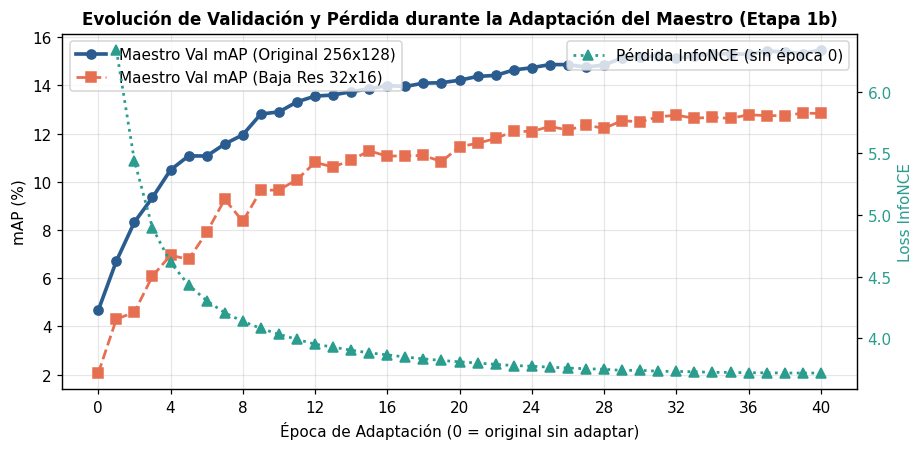

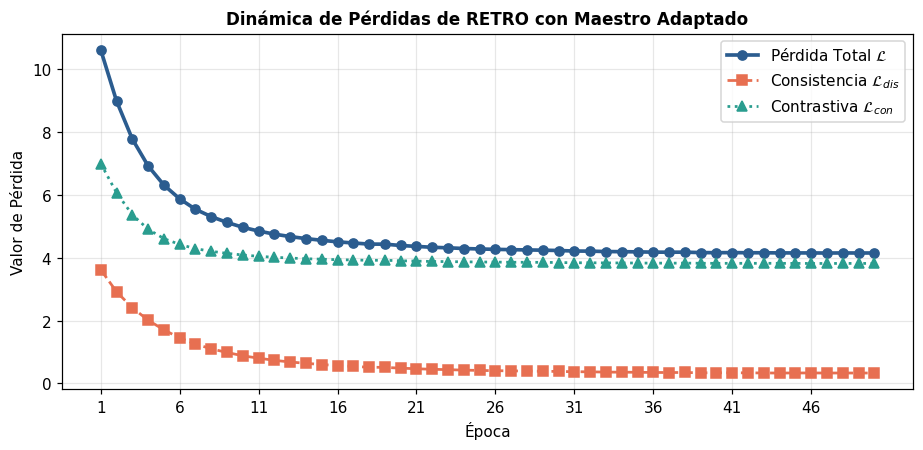

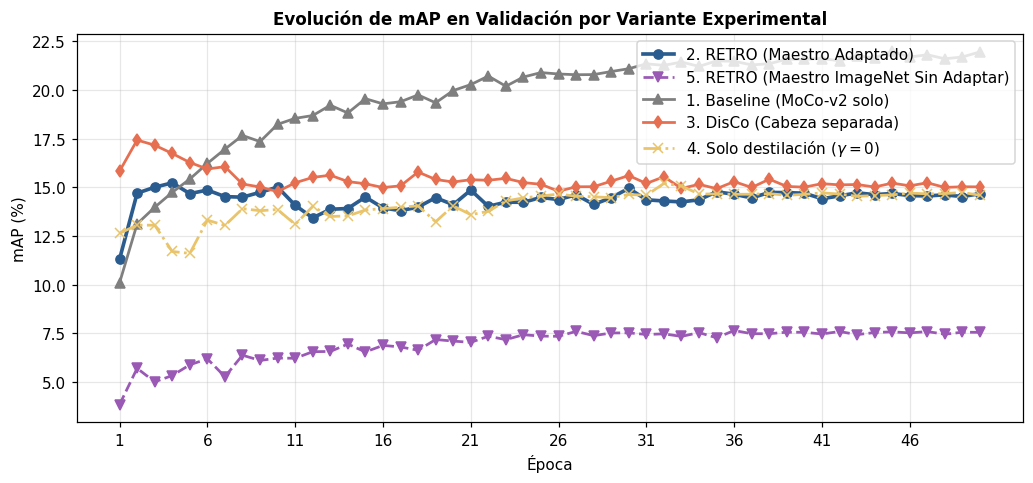

In [76]:
# Visualización de curvas de validación y dinámicas de pérdida
if EJECUTAR_ENTRENAMIENTO_COMPLETO:
    if 'teacher_history' in locals() and teacher_history.get('val_mAP'):
        # Curva 1: Evolución del mAP del Maestro MoCo-v2 durante su Adaptación
        fig, ax = plt.subplots(figsize=(8.5, 4.2))
        eps_t = list(range(len(teacher_history['val_mAP'])))
        ax.plot(eps_t, [v * 100 for v in teacher_history['val_mAP']], label='Maestro Val mAP (Original 256x128)', color='#2b5c8f', lw=2.4, marker='o')
        ax.plot(eps_t, [v * 100 for v in teacher_history['val_mAP_low']], label='Maestro Val mAP (Baja Res 32x16)', color='#e76f51', lw=1.8, ls='--', marker='s')
        
        # Pérdida InfoNCE del maestro (omitiendo época 0 con loss None)
        loss_eps = [i for i, l in enumerate(teacher_history.get('loss', [])) if l is not None]
        loss_vals = [l for l in teacher_history.get('loss', []) if l is not None]
        if loss_vals:
            ax2 = ax.twinx()
            ax2.plot(loss_eps, loss_vals, label='Pérdida InfoNCE (sin época 0)', color='#2a9d8f', lw=1.8, ls=':', marker='^')
            ax2.set_ylabel("Loss InfoNCE", color='#2a9d8f')
            ax2.tick_params(axis='y', labelcolor='#2a9d8f')
            ax2.grid(False)
            
        ax.set_title("Evolución de Validación y Pérdida durante la Adaptación del Maestro (Etapa 1b)", fontsize=11, fontweight="bold")
        ax.set_xlabel("Época de Adaptación (0 = original sin adaptar)")
        ax.set_ylabel("mAP (%)")
        ax.set_xticks(list(range(0, len(eps_t), max(1, len(eps_t) // 10))))
        ax.legend(loc='upper left')
        if loss_vals:
            ax2.legend(loc='upper right')
        plt.tight_layout()
        plt.savefig(DIR_FIGS / 'curva_val_maestro.png', dpi=150, bbox_inches='tight')
        plt.show()

    if 'hist_retro' in locals() and hist_retro.get('loss'):
        # Curva 2: Dinámica de Pérdidas de RETRO con Maestro Adaptado
        fig, ax = plt.subplots(figsize=(8.5, 4.2))
        eps = range(1, len(hist_retro['loss']) + 1)
        ax.plot(eps, hist_retro['loss'], label=r'Pérdida Total $\mathcal{L}$', color='#2b5c8f', lw=2.4, marker='o')
        ax.plot(eps, hist_retro['ldis'], label=r'Consistencia $\mathcal{L}_{dis}$', color='#e76f51', lw=1.8, ls='--', marker='s')
        ax.plot(eps, hist_retro['lcon'], label=r'Contrastiva $\mathcal{L}_{con}$', color='#2a9d8f', lw=1.8, ls=':', marker='^')
        ax.set_title("Dinámica de Pérdidas de RETRO con Maestro Adaptado", fontsize=11, fontweight="bold")
        ax.set_xlabel("Época")
        ax.set_ylabel("Valor de Pérdida")
        ax.set_xticks(list(range(1, len(eps) + 1, max(1, len(eps) // 10))))
        ax.legend()
        plt.tight_layout()
        plt.savefig(DIR_FIGS / 'curvas_perdidas_retro.png', dpi=150, bbox_inches='tight')
        plt.show()

    if 'hist_retro' in locals() and hist_retro.get('val_mAP') and 'hist_base' in locals():
        # Curva 3: Evolución de mAP en Validación por Variante Experimental
        fig, ax = plt.subplots(figsize=(9.5, 4.5))
        eps_r = range(1, len(hist_retro['val_mAP']) + 1)
        eps_b = range(1, len(hist_base['val_mAP']) + 1)
        eps_d = range(1, len(hist_disco['val_mAP']) + 1)
        eps_n = range(1, len(hist_nodis['val_mAP']) + 1)
        eps_u = range(1, len(hist_unadapt['val_mAP']) + 1) if 'hist_unadapt' in locals() else []

        ax.plot(eps_r, [v * 100 for v in hist_retro['val_mAP']], label='2. RETRO (Maestro Adaptado)', color='#2b5c8f', lw=2.4, marker='o')
        if eps_u:
            ax.plot(eps_u, [v * 100 for v in hist_unadapt['val_mAP']], label='5. RETRO (Maestro ImageNet Sin Adaptar)', color='#9b59b6', lw=1.8, ls='--', marker='v')
        ax.plot(eps_b, [v * 100 for v in hist_base['val_mAP']], label='1. Baseline (MoCo-v2 solo)', color='#7f7f7f', lw=1.8, marker='^')
        ax.plot(eps_d, [v * 100 for v in hist_disco['val_mAP']], label='3. DisCo (Cabeza separada)', color='#e76f51', lw=1.8, marker='d')
        ax.plot(eps_n, [v * 100 for v in hist_nodis['val_mAP']], label=r'4. Solo destilación ($\gamma=0$)', color='#e9c46a', lw=1.8, ls='-.', marker='x')

        ax.set_title("Evolución de mAP en Validación por Variante Experimental", fontsize=11, fontweight="bold")
        ax.set_xlabel("Época")
        ax.set_ylabel("mAP (%)")
        max_ep = max(len(hist_retro['val_mAP']), len(hist_base['val_mAP']), len(hist_disco['val_mAP']))
        ax.set_xticks(list(range(1, max_ep + 1, max(1, max_ep // 10))))
        ax.legend()
        plt.tight_layout()
        plt.savefig(DIR_FIGS / 'curvas_perdida_val.png', dpi=150, bbox_inches='tight')
        plt.show()
else:
    print("[OMITIDO] Esta celda requiere los modelos entrenados. Ejecuta el paso 2 (EJECUTAR_ENTRENAMIENTO_COMPLETO = True).")


### Lectura de la Dinámica de Validación

- **Maestro (Etapa 1b):** el mAP de validación sube de **4.67 %** (MoCo-v2 ImageNet sin adaptar, época 0) a **15.47 %** en la época 40 (Rank-1 de 6 % a 28 %; mAP con baja resolución de 2.07 % a 12.83 %). Sube rápido hasta la época ~15 y se estabiliza hacia la época ~30 (15.1 %–15.5 %), cuando el learning rate ya es casi nulo. La pérdida InfoNCE baja de 6.34 a 3.72 sin señales de colapso.
- **Búsqueda de $m$:** $m = 0.99$ alcanza 16.15 % y $m = 0.999$ 15.54 % de mAP en validación. Con solo 100 consultas, la diferencia de 0.6 puntos entra en la variación normal entre épocas (±1–2 puntos). Elegimos $m = 0.99$ porque converge más rápido con solo ≈86 pasos por época, no porque sea claramente superior.
- **Estudiantes:** con el maestro adaptado, el estudiante llega a ~15–16 % de mAP en apenas 3–7 épocas (prácticamente el 15.47 % del maestro) y luego se estanca. RETRO y la cabeza separada eligieron su mejor checkpoint al inicio; la variante solo destilación ($\gamma=0$) siguió mejorando hasta la época ~33 (15.20 %). Vemos que **el maestro actúa como techo** del estudiante: más épocas no compensan un maestro débil.
- **Validación vs test:** validación da valores más altos porque es una tarea más fácil (100 consultas contra 1,793 imágenes sin distractores) que test (3,368 consultas contra 19,732 imágenes con 2,798 distractores). Solo usamos validación para elegir hiperparámetros y épocas, nunca test.


---
## 14. Evaluación Final en el Conjunto de Prueba (`testing.h5`)

Evaluamos los 7 modelos sobre el conjunto de test (3,368 consultas y 19,732 imágenes de galería) en dos condiciones:
1. **Condición 1 (Original):** consultas en 256×128 contra galería normal.
2. **Condición 2 (Baja resolución):** consultas reducidas a 32×16 y reescaladas a 256×128 contra galería normal.

Modelos evaluados:
- **0a. Maestro MoCo-v2 ImageNet:** ResNet-50 (23.51 M params).
- **0b. Maestro Adaptado a Market:** ResNet-50 (23.51 M params).
- **1. Baseline MoCo-v2 (sin maestro):** ResNet-18 (11.18 M params).
- **2. RETRO con Maestro Adaptado:** ResNet-18 (11.18 M params).
- **3. Cabeza Separada (DisCo):** ResNet-18 (11.18 M params).
- **4. Solo Destilación ($\gamma=0$):** ResNet-18 (11.18 M params).
- **5. Maestro Sin Adaptar:** ResNet-18 (11.18 M params).


In [77]:
# Evaluación en test condicionada a la ejecución completa
if EJECUTAR_ENTRENAMIENTO_COMPLETO and all(n in globals() for n in ['model_baseline', 'model_retro', 'model_disco', 'model_nodis', 'model_retro_unadapted', 'teacher_enc', 'teacher_enc_imagenet']):
    # Verificación de que cada modelo sea una instancia válida de RETROModel o ResNet
    modelos_estudiantes = [model_baseline, model_retro, model_disco, model_nodis, model_retro_unadapted]
    if not all(isinstance(m, RETROModel) for m in modelos_estudiantes) or not isinstance(teacher_enc, models.ResNet) or not isinstance(teacher_enc_imagenet, models.ResNet):
        raise RuntimeError("Hay modelos de una ejecución anterior en memoria: reinicia la sesión (Entorno de ejecución → Reiniciar sesión)")

    test_q_loader = DataLoader(EvalDataset(test_q_images, is_low_res=False), batch_size=BATCH_SIZE, shuffle=False)
    test_q_low_loader = DataLoader(EvalDataset(test_q_low_images, is_low_res=True), batch_size=BATCH_SIZE, shuffle=False)
    test_g_loader = DataLoader(EvalDataset(test_g_images, is_low_res=False), batch_size=BATCH_SIZE, shuffle=False)

    eval_models = {
        '0a. Maestro MoCo-v2 ImageNet (ResNet-50)': (
            teacher_enc_imagenet, True,
            sum(p.numel() for p in teacher_enc_imagenet.parameters()),
            0
        ),
        '0b. Maestro Adaptado a Market (ResNet-50)': (
            teacher_enc, True,
            sum(p.numel() for p in teacher_enc.parameters()),
            0
        ),
        '1. Baseline (MoCo-v2 solo)': (
            model_baseline, False,
            sum(p.numel() for p in model_baseline.student.parameters()),
            sum(p.numel() for p in model_baseline.parameters() if p.requires_grad)
        ),
        '2. RETRO con Maestro Adaptado': (
            model_retro, False,
            sum(p.numel() for p in model_retro.student.parameters()),
            sum(p.numel() for p in model_retro.parameters() if p.requires_grad)
        ),
        '3. Cabeza Separada (DisCo) con Maestro Adaptado': (
            model_disco, False,
            sum(p.numel() for p in model_disco.student.parameters()),
            sum(p.numel() for p in model_disco.parameters() if p.requires_grad)
        ),
        '4. Solo Destilación (γ=0) con Maestro Adaptado': (
            model_nodis, False,
            sum(p.numel() for p in model_nodis.student.parameters()),
            sum(p.numel() for p in model_nodis.parameters() if p.requires_grad)
        ),
        '5. RETRO con Maestro Sin Adaptar (Ablación)': (
            model_retro_unadapted, False,
            sum(p.numel() for p in model_retro_unadapted.student.parameters()),
            sum(p.numel() for p in model_retro_unadapted.parameters() if p.requires_grad)
        ),
    }

    test_results = {}
    rows = []
    cache_file = DIR_OUT / f'test_results_v1_{CONFIG_ID}.json'

    if cache_file.exists() and not FORCE_RETRAIN:
        print(f"[CACHE] Cargando métricas de test desde {cache_file.name}...")
        with open(cache_file, 'r', encoding='utf-8') as f:
            test_results = json.load(f)
        for name, r in test_results.items():
            orig_res = r['orig']
            low_res = r['low']
            rows.append({
                'Modelo': name,
                'Parámetros en inferencia': f"{r['n_infer']:,}",
                'Parámetros entrenables': f"{r['n_train']:,}",
                'mAP (Orig)': f"{orig_res['mAP']*100:.2f}%",
                'Rank-1 (Orig)': f"{orig_res['Rank-1']*100:.2f}%",
                'Rank-5 (Orig)': f"{orig_res['Rank-5']*100:.2f}%",
                'Rank-10 (Orig)': f"{orig_res['Rank-10']*100:.2f}%",
                'mAP (Baja Res)': f"{low_res['mAP']*100:.2f}%",
                'Rank-1 (Baja Res)': f"{low_res['Rank-1']*100:.2f}%",
                'ΔmAP (Abs)': f"{r['delta_mAP']*100:.2f}%",
                'Caída (%)': f"{r['pct_drop_mAP']:.1f}%"
            })
    else:
        for name, (m, is_teach, n_inf, n_trn) in eval_models.items():
            print(f"Evaluando {name} en test (3,368 queries vs 19,732 galería)...")
            q_feats = extract_features(m, test_q_loader, DEVICE, is_teacher=is_teach)
            q_low_feats = extract_features(m, test_q_low_loader, DEVICE, is_teacher=is_teach)
            g_feats = extract_features(m, test_g_loader, DEVICE, is_teacher=is_teach)
            
            orig_res = evaluate_market1501(q_feats, g_feats, test_q_pids, test_g_pids, test_q_cams, test_g_cams)
            low_res = evaluate_market1501(q_low_feats, g_feats, test_q_pids, test_g_pids, test_q_cams, test_g_cams)
            
            delta_mAP = orig_res['mAP'] - low_res['mAP']
            pct_drop = (delta_mAP / orig_res['mAP']) * 100 if orig_res['mAP'] > 0 else 0.0
            
            test_results[name] = {
                'orig': orig_res, 'low': low_res,
                'delta_mAP': delta_mAP, 'pct_drop_mAP': pct_drop,
                'n_infer': n_inf, 'n_train': n_trn
            }
            rows.append({
                'Modelo': name,
                'Parámetros en inferencia': f"{n_inf:,}",
                'Parámetros entrenables': f"{n_trn:,}",
                'mAP (Orig)': f"{orig_res['mAP']*100:.2f}%",
                'Rank-1 (Orig)': f"{orig_res['Rank-1']*100:.2f}%",
                'Rank-5 (Orig)': f"{orig_res['Rank-5']*100:.2f}%",
                'Rank-10 (Orig)': f"{orig_res['Rank-10']*100:.2f}%",
                'mAP (Baja Res)': f"{low_res['mAP']*100:.2f}%",
                'Rank-1 (Baja Res)': f"{low_res['Rank-1']*100:.2f}%",
                'ΔmAP (Abs)': f"{delta_mAP*100:.2f}%",
                'Caída (%)': f"{pct_drop:.1f}%"
            })

        with open(cache_file, 'w', encoding='utf-8') as f:
            json.dump(test_results, f, indent=2)

    df_test_summary = pd.DataFrame(rows)
    df_test_summary.to_csv(DIR_OUT / f'test_summary_table_v1_{CONFIG_ID}.csv', index=False)

    print("\n" + "="*80)
    print("TABLA COMPARATIVA FINAL EN CONJUNTO DE PRUEBA (testing.h5)")
    print("="*80)
    display(df_test_summary) if 'display' in dir() else print(df_test_summary.to_string())
    print("="*80)
else:
    print("[OMITIDO] Esta celda requiere los modelos entrenados. Ejecuta el paso 2 (EJECUTAR_ENTRENAMIENTO_COMPLETO = True).")


[CACHE] Cargando métricas de test desde test_results_v1_bs128_scratch_ep50_m0.99.json...

TABLA COMPARATIVA FINAL EN CONJUNTO DE PRUEBA (testing.h5)
                                            Modelo Parámetros en inferencia Parámetros entrenables mAP (Orig) Rank-1 (Orig) Rank-5 (Orig) Rank-10 (Orig) mAP (Baja Res) Rank-1 (Baja Res) ΔmAP (Abs) Caída (%)
0         0a. Maestro MoCo-v2 ImageNet (ResNet-50)               23,508,032                      0      1.35%         3.80%         9.53%         13.18%          0.46%             1.01%      0.89%     66.1%
1        0b. Maestro Adaptado a Market (ResNet-50)               23,508,032                      0      4.97%        15.29%        26.96%         34.29%          4.26%            13.00%      0.71%     14.3%
2                       1. Baseline (MoCo-v2 solo)               11,176,512             12,493,504      5.84%        14.58%        27.38%         34.32%          5.83%            14.70%      0.01%      0.2%
3                    2.

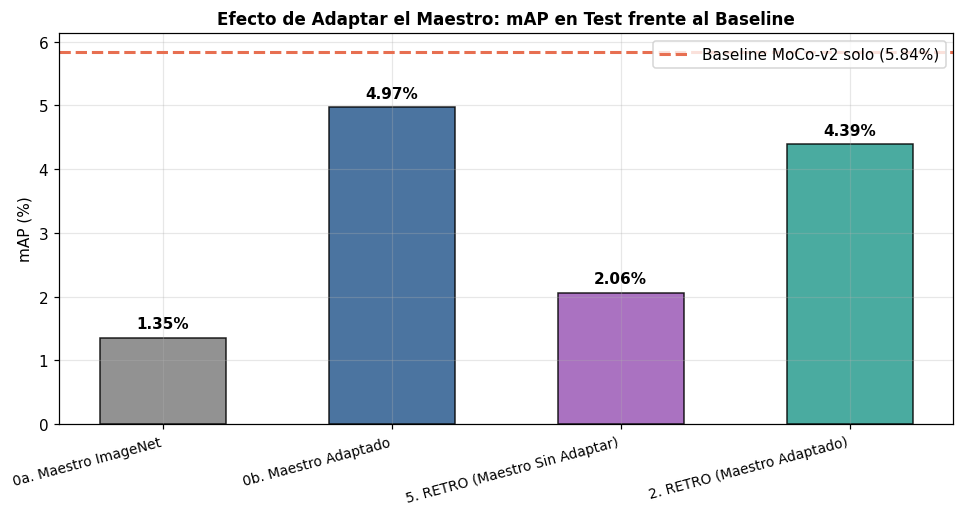

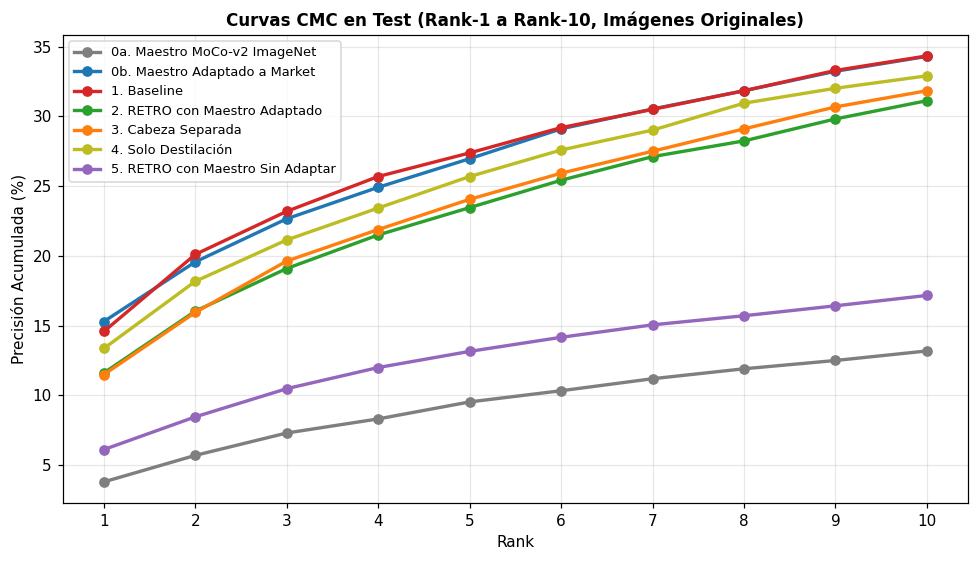

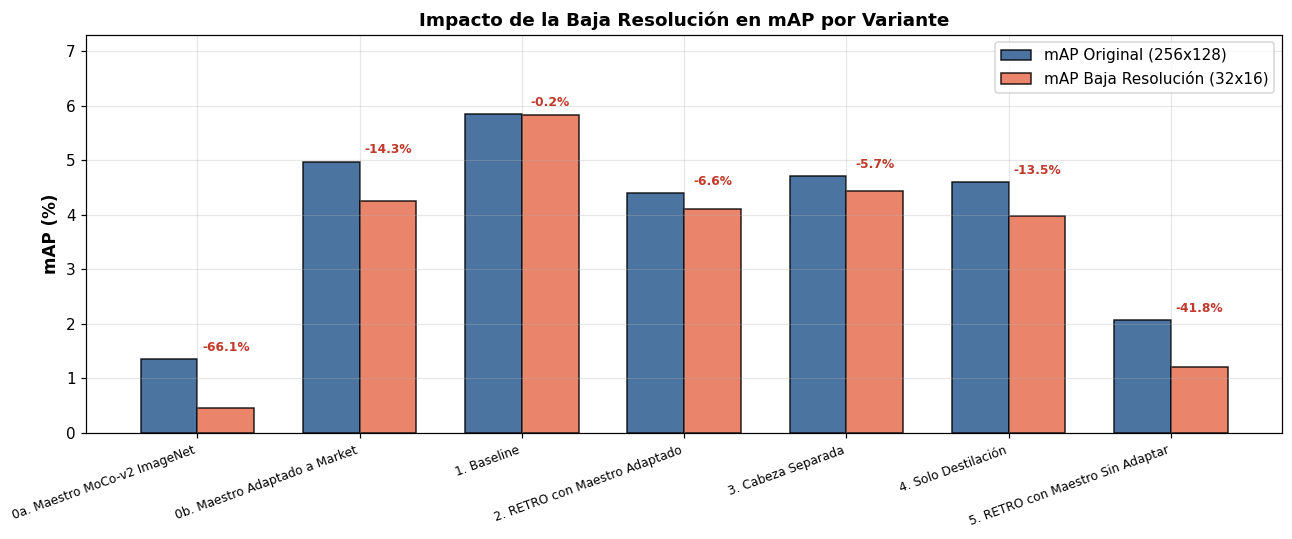

In [78]:
# Visualizaciones de resultados de test: Efecto de Adaptación, CMC y Degradación
if EJECUTAR_ENTRENAMIENTO_COMPLETO and all(n in globals() for n in ['model_baseline', 'model_retro', 'model_disco', 'model_nodis', 'model_retro_unadapted', 'teacher_enc', 'teacher_enc_imagenet']):
    if 'test_results' in locals() and test_results:
        # Plot A: Efecto de Adaptar el Maestro
        plt.figure(figsize=(9, 4.8))
        names_comp = [
            '0a. Maestro ImageNet',
            '0b. Maestro Adaptado',
            '5. RETRO (Maestro Sin Adaptar)',
            '2. RETRO (Maestro Adaptado)'
        ]
        keys_comp = [
            '0a. Maestro MoCo-v2 ImageNet (ResNet-50)',
            '0b. Maestro Adaptado a Market (ResNet-50)',
            '5. RETRO con Maestro Sin Adaptar (Ablación)',
            '2. RETRO con Maestro Adaptado'
        ]
        vals_comp = [test_results[k]['orig']['mAP'] * 100 for k in keys_comp]
        colors_comp = ['#7f7f7f', '#2b5c8f', '#9b59b6', '#2a9d8f']
        
        bars = plt.bar(names_comp, vals_comp, color=colors_comp, edgecolor='black', alpha=0.85, width=0.55)
        
        # Línea de referencia del Baseline MoCo-v2 solo
        base_map = test_results['1. Baseline (MoCo-v2 solo)']['orig']['mAP'] * 100
        plt.axhline(base_map, color='#e76f51', linestyle='--', linewidth=2, label=f'Baseline MoCo-v2 solo ({base_map:.2f}%)')
        
        for b, v in zip(bars, vals_comp):
            plt.text(b.get_x() + b.get_width()/2, v + 0.1, f"{v:.2f}%", ha='center', va='bottom', fontsize=10, fontweight='bold')
            
        plt.title("Efecto de Adaptar el Maestro: mAP en Test frente al Baseline", fontsize=11, fontweight="bold")
        plt.ylabel("mAP (%)")
        plt.xticks(rotation=15, ha='right', fontsize=9)
        plt.legend()
        plt.tight_layout()
        plt.savefig(DIR_FIGS / 'efecto_adaptacion_maestro.png', dpi=150, bbox_inches='tight')
        plt.show()

        # Plot B: Curvas CMC en Test (Rank-1 a Rank-10)
        plt.figure(figsize=(9, 5.2))
        ranks = np.arange(1, 11)
        colors_cmc = ['#7f7f7f', '#1f77b4', '#d62728', '#2ca02c', '#ff7f0e', '#bcbd22', '#9467bd']

        for (name, r), col in zip(test_results.items(), colors_cmc):
            short_name = name.split('(')[0].strip()
            plt.plot(ranks, [c * 100 for c in r['orig']['cmc'][:10]], label=short_name, color=col, lw=2.2, marker='o')

        plt.title("Curvas CMC en Test (Rank-1 a Rank-10, Imágenes Originales)", fontsize=11, fontweight="bold")
        plt.xlabel("Rank")
        plt.ylabel("Precisión Acumulada (%)")
        plt.xticks(ranks)
        plt.legend(fontsize=8.5)
        plt.tight_layout()
        plt.savefig(DIR_FIGS / 'curvas_cmc_test.png', dpi=150, bbox_inches='tight')
        plt.show()

        # Plot C: Impacto de la Baja Resolución en mAP por Variante
        models_list = list(test_results.keys())
        orig_mAP = [test_results[m]['orig']['mAP'] * 100 for m in models_list]
        low_mAP = [test_results[m]['low']['mAP'] * 100 for m in models_list]
        drops = [test_results[m]['pct_drop_mAP'] for m in models_list]

        x = np.arange(len(models_list))
        w = 0.35

        fig, ax1 = plt.subplots(figsize=(12, 5))
        rects1 = ax1.bar(x - w/2, orig_mAP, w, label='mAP Original (256x128)', color='#2b5c8f', edgecolor='black', alpha=0.85)
        rects2 = ax1.bar(x + w/2, low_mAP, w, label='mAP Baja Resolución (32x16)', color='#e76f51', edgecolor='black', alpha=0.85)

        ax1.set_ylabel('mAP (%)', fontsize=11, fontweight='bold')
        ax1.set_title('Impacto de la Baja Resolución en mAP por Variante', fontsize=12, fontweight='bold')
        ax1.set_xticks(x)
        ax1.set_xticklabels([m.split('(')[0].strip() for m in models_list], fontsize=8, rotation=20, ha='right')
        ax1.legend(loc='upper right')

        for r1, r2, d in zip(rects1, rects2, drops):
            h = max(r1.get_height(), r2.get_height())
            ax1.text(r2.get_x() + w/2, h + 0.1, f'-{d:.1f}%', ha='center', va='bottom', fontsize=8, fontweight='bold', color='#c0392b')

        plt.ylim(0, max(orig_mAP) * 1.25 if max(orig_mAP) > 0 else 10)
        plt.tight_layout()
        plt.savefig(DIR_FIGS / 'degradacion_baja_resolucion.png', dpi=150, bbox_inches='tight')
        plt.show()
else:
    print("[OMITIDO] Esta celda requiere los modelos entrenados. Ejecuta el paso 2 (EJECUTAR_ENTRENAMIENTO_COMPLETO = True).")


### Lectura de los Resultados en Test

**Caída de mAP:** $\Delta mAP = mAP_{orig} - mAP_{baja\,res}$; Caída (%) $= \Delta mAP / mAP_{orig}$.

| Modelo | Params. inferencia | mAP orig. | R-1 | R-5 | R-10 | mAP baja res. | Caída |
|---|---|---|---|---|---|---|---|
| 0a. Maestro MoCo-v2 ImageNet (R50) | 23.5 M | 1.35 % | 3.80 % | 9.53 % | 13.18 % | 0.46 % | 66.1 % |
| 0b. Maestro adaptado a Market (R50) | 23.5 M | 4.97 % | 15.29 % | 26.96 % | 34.29 % | 4.26 % | 14.3 % |
| 1. Baseline MoCo-v2 (R18, sin maestro) | 11.2 M | **5.84 %** | 14.58 % | 27.38 % | 34.32 % | **5.83 %** | **0.2 %** |
| 2. RETRO con maestro adaptado | 11.2 M | 4.39 % | 11.61 % | 23.46 % | 31.12 % | 4.10 % | 6.6 % |
| 3. Cabeza separada (DisCo) | 11.2 M | 4.70 % | 11.49 % | 24.05 % | 31.83 % | 4.43 % | 5.7 % |
| 4. Solo destilación ($\gamma=0$) | 11.2 M | 4.59 % | 13.36 % | 25.68 % | 32.90 % | 3.98 % | 13.5 % |
| 5. RETRO con maestro sin adaptar | 11.2 M | 2.06 % | 6.12 % | 13.15 % | 17.16 % | 1.20 % | 41.8 % |

**1. Efecto de adaptar el maestro (ablación de la Etapa 1b).** El maestro adaptado multiplica por 3.7 el mAP del maestro de ImageNet (1.35 % → 4.97 %) y por 4 su Rank-1 (3.80 % → 15.29 %); su caída con consultas de baja resolución baja de 66.1 % a 14.3 %. El estudiante hereda esta mejora: RETRO con maestro adaptado duplica el mAP de RETRO con maestro sin adaptar (2.06 % → 4.39 %) y reduce su caída de 41.8 % a 6.6 %. Es el resultado más claro del laboratorio: **la calidad del maestro en el dominio objetivo determina la calidad del estudiante**.

**2. Maestro vs estudiante (transferencia).**

| | Maestro adaptado (R50) | Estudiante RETRO (R18) | Estudiante / maestro |
|---|---|---|---|
| Parámetros en inferencia | 23,508,032 | 11,176,512 | 47.5 % |
| mAP orig. | 4.97 % | 4.39 % | 88 % |
| Rank-1 | 15.29 % | 11.61 % | 76 % |
| Rank-10 | 34.29 % | 31.12 % | 91 % |
| mAP baja res. | 4.26 % | 4.10 % | 96 % |
| Caída | 14.3 % | 6.6 % | — |

Con menos de la mitad de parámetros (47.5 %), el estudiante conserva el 88 % del mAP del maestro y es más robusto a la baja resolución. La transferencia funciona: el estudiante aprende el espacio de embeddings del maestro, aunque la pérdida más visible está en Rank-1.

**3. Comparación con el baseline.** El baseline (ResNet-18 entrenado solo con MoCo-v2 sobre Market, sin maestro) obtiene el mejor mAP (5.84 % frente a 4.39 % de RETRO) y prácticamente no cae con consultas de baja resolución (0.2 %). RETRO no supera al baseline porque el estudiante queda limitado por su maestro: el maestro adaptado (4.97 %) es más débil que lo que ResNet-18 aprende directamente de Market. En el paper esta comparación favorece a RETRO porque el maestro es fuerte y se entrenó en su propio dominio (ImageNet).

**4. Ablación de componentes de RETRO.** Reutilizar la cabeza congelada del maestro (4.39 %) y entrenar una cabeza propia tipo DisCo (4.70 %) dan prácticamente el mismo resultado: 0.31 puntos de diferencia con una sola semilla y Rank-1 casi idéntico (11.61 % vs 11.49 %). **No reproducimos la ganancia** de reutilizar la cabeza reportada en el paper (ResNet-18: 60.6 → 62.5 de top-1 en ImageNet). Nuestra hipótesis es que la ventaja de RETRO supone que la cabeza del maestro ya define un buen espacio de embeddings; con un maestro débil en Re-ID, congelar su cabeza ata al estudiante a ese espacio, mientras que una cabeza entrenable puede ajustarse mejor. Además, ambos estudiantes alcanzaron su mejor época muy temprano. Sin el término contrastivo ($\gamma=0$) el mAP es similar (4.59 %) y el Rank-1 es el mejor de los estudiantes destilados (13.36 %), pero la caída en baja resolución se duplica (13.5 % vs 6.6 %): **$\mathcal{L}_{con}$ aporta sobre todo robustez ante la baja resolución**.

**5. Valores absolutos bajos.** Los mAP en test (≈5 %) son bajos en términos absolutos porque no usamos etiquetas de identidad, solo contamos con 11,043 imágenes de entrenamiento, el estudiante ResNet-18 parte de cero, entrenamos 50 épocas y no incluimos trucos específicos de Re-ID no supervisada (como pseudo-etiquetas por clustering). Lo relevante son las comparaciones relativas entre modelos.


---
## 15. Análisis Cualitativo Basado en Evidencia (≥5 Aciertos y ≥5 Fallos)

Evaluamos las 3,368 consultas de test con el estudiante RETRO y maestro adaptado:
- **5 aciertos:** consultas con acierto en Rank-1 y mayor margen de similitud frente al primer impostor.
- **5 fallos:** consultas con fallo en Rank-1 y mayor confusión con el impostor frente al primer acierto.
- Generamos una ficha técnica con las métricas de cada caso.


In [79]:
# Extracción de características y fichas técnicas automáticas para RETRO con maestro adaptado
if EJECUTAR_ENTRENAMIENTO_COMPLETO and all(n in globals() for n in ['model_baseline', 'model_retro', 'model_disco', 'model_nodis', 'model_retro_unadapted', 'teacher_enc', 'teacher_enc_imagenet']):
    print("Calculando similitudes de RETRO con maestro adaptado en test...")
    retro_test_q_feats = extract_features(model_retro, test_q_loader, DEVICE)
    retro_test_q_low_feats = extract_features(model_retro, test_q_low_loader, DEVICE)
    retro_test_g_feats = extract_features(model_retro, test_g_loader, DEVICE)

    q_norm = F.normalize(retro_test_q_feats, p=2, dim=1)
    q_low_norm = F.normalize(retro_test_q_low_feats, p=2, dim=1)
    g_norm = F.normalize(retro_test_g_feats, p=2, dim=1)

    sim_mat = torch.mm(q_norm, g_norm.t()).numpy()
    sim_low_mat = torch.mm(q_low_norm, g_norm.t()).numpy()

    q_pids_arr = np.asarray(test_q_pids)
    q_cams_arr = np.asarray(test_q_cams)
    g_pids_arr = np.asarray(test_g_pids)
    g_cams_arr = np.asarray(test_g_cams)

    candidate_successes = []
    candidate_failures = []

    for q_idx in range(len(q_pids_arr)):
        qp, qc = q_pids_arr[q_idx], q_cams_arr[q_idx]
        order = np.argsort(-sim_mat[q_idx])
        
        junk_mask = ((g_pids_arr[order] == qp) & (g_cams_arr[order] == qc)) | (g_pids_arr[order] == -1)
        valid_order = order[~junk_mask]
        
        if len(valid_order) < 5:
            continue
            
        top1_idx = valid_order[0]
        top1_pid = g_pids_arr[top1_idx]
        top1_sim = sim_mat[q_idx, top1_idx]
        
        order_low = np.argsort(-sim_low_mat[q_idx])
        junk_low = ((g_pids_arr[order_low] == qp) & (g_cams_arr[order_low] == qc)) | (g_pids_arr[order_low] == -1)
        top1_low_pid = g_pids_arr[order_low[~junk_low]][0]
        succeeds_in_low = (top1_low_pid == qp)
        
        correct_positions = np.where(g_pids_arr[valid_order] == qp)[0]
        if len(correct_positions) == 0:
            continue
        first_correct_rank = correct_positions[0] + 1
        first_correct_idx = valid_order[correct_positions[0]]
        first_correct_sim = sim_mat[q_idx, first_correct_idx]
        
        impostor_positions = np.where(g_pids_arr[valid_order] != qp)[0]
        first_impostor_sim = sim_mat[q_idx, valid_order[impostor_positions[0]]] if len(impostor_positions) > 0 else 0.0
        
        item = {
            'q_idx': q_idx, 'qp': qp, 'qc': qc,
            'top5_indices': valid_order[:5],
            'top5_pids': g_pids_arr[valid_order[:5]].tolist(),
            'top5_cams': g_cams_arr[valid_order[:5]].tolist(),
            'top5_sims': [float(sim_mat[q_idx, idx]) for idx in valid_order[:5]],
            'first_correct_rank': int(first_correct_rank),
            'first_correct_sim': float(first_correct_sim),
            'top1_impostor_sim': float(first_impostor_sim),
            'margin': float(first_correct_sim - first_impostor_sim),
            'confusion': float(top1_sim - first_correct_sim),
            'succeeds_low_res': bool(succeeds_in_low)
        }
        
        if top1_pid == qp:
            candidate_successes.append(item)
        else:
            candidate_failures.append(item)

    top_successes = sorted(candidate_successes, key=lambda x: x['margin'], reverse=True)[:5]
    top_failures = sorted(candidate_failures, key=lambda x: x['confusion'], reverse=True)[:5]

    print("=" * 80)
    print("FICHAS TÉCNICAS AUTOMÁTICAS: 5 CASOS DE ACIERTO (MAYOR MARGEN)")
    print("=" * 80)
    for i, s in enumerate(top_successes, 1):
        print(f"\n[FICHA ACIERTO #{i}] Query PID: {s['qp']} | Cámara: {s['qc']}")
        print(f"  - Top-5 Galería (PID | Cam | Sim): " + ", ".join([f"({p}, C{c}, {sim:.3f})" for p, c, sim in zip(s['top5_pids'], s['top5_cams'], s['top5_sims'])]))
        print(f"  - Rank del 1er acierto : {s['first_correct_rank']} (Similitud: {s['first_correct_sim']:.4f})")
        print(f"  - Margen frente a impostor: +{s['margin']:.4f}")
        print(f"  - ¿Acierta en Baja Res?   : {'SÍ' if s['succeeds_low_res'] else 'NO'}")

    print("\n" + "=" * 80)
    print("FICHAS TÉCNICAS AUTOMÁTICAS: 5 CASOS DE FALLO CRÍTICO (MAYOR CONFUSIÓN)")
    print("=" * 80)
    for i, f in enumerate(top_failures, 1):
        print(f"\n[FICHA FALLO #{i}] Query PID: {f['qp']} | Cámara: {f['qc']}")
        print(f"  - Top-5 Galería (PID | Cam | Sim): " + ", ".join([f"({p}, C{c}, {sim:.3f})" for p, c, sim in zip(f['top5_pids'], f['top5_cams'], f['top5_sims'])]))
        print(f"  - Impostor Top-1 (Similitud)   : PID {f['top5_pids'][0]} (Sim: {f['top5_sims'][0]:.4f})")
        print(f"  - Rank del 1er acierto genuino : {f['first_correct_rank']} (Sim: {f['first_correct_sim']:.4f})")
        print(f"  - Brecha de Confusión         : +{f['confusion']:.4f} a favor del impostor")
        print(f"  - ¿Acierta en Baja Res?       : {'SÍ' if f['succeeds_low_res'] else 'NO'}")
    print("=" * 80)
else:
    print("[OMITIDO] Esta celda requiere los modelos entrenados. Ejecuta el paso 2 (EJECUTAR_ENTRENAMIENTO_COMPLETO = True).")


Calculando similitudes de RETRO con maestro adaptado en test...
FICHAS TÉCNICAS AUTOMÁTICAS: 5 CASOS DE ACIERTO (MAYOR MARGEN)

[FICHA ACIERTO #1] Query PID: 829 | Cámara: 5
  - Top-5 Galería (PID | Cam | Sim): (829, C4, 0.983), (829, C4, 0.976), (829, C4, 0.971), (829, C4, 0.967), (829, C4, 0.963)
  - Rank del 1er acierto : 1 (Similitud: 0.9826)
  - Margen frente a impostor: +0.0344
  - ¿Acierta en Baja Res?   : SÍ

[FICHA ACIERTO #2] Query PID: 102 | Cámara: 4
  - Top-5 Galería (PID | Cam | Sim): (102, C2, 0.968), (0, C2, 0.939), (285, C5, 0.936), (285, C5, 0.936), (285, C5, 0.935)
  - Rank del 1er acierto : 1 (Similitud: 0.9684)
  - Margen frente a impostor: +0.0294
  - ¿Acierta en Baja Res?   : SÍ

[FICHA ACIERTO #3] Query PID: 422 | Cámara: 1
  - Top-5 Galería (PID | Cam | Sim): (422, C4, 0.971), (422, C4, 0.969), (422, C4, 0.966), (422, C4, 0.958), (993, C2, 0.944)
  - Rank del 1er acierto : 1 (Similitud: 0.9707)
  - Margen frente a impostor: +0.0270
  - ¿Acierta en Baja Res?   :

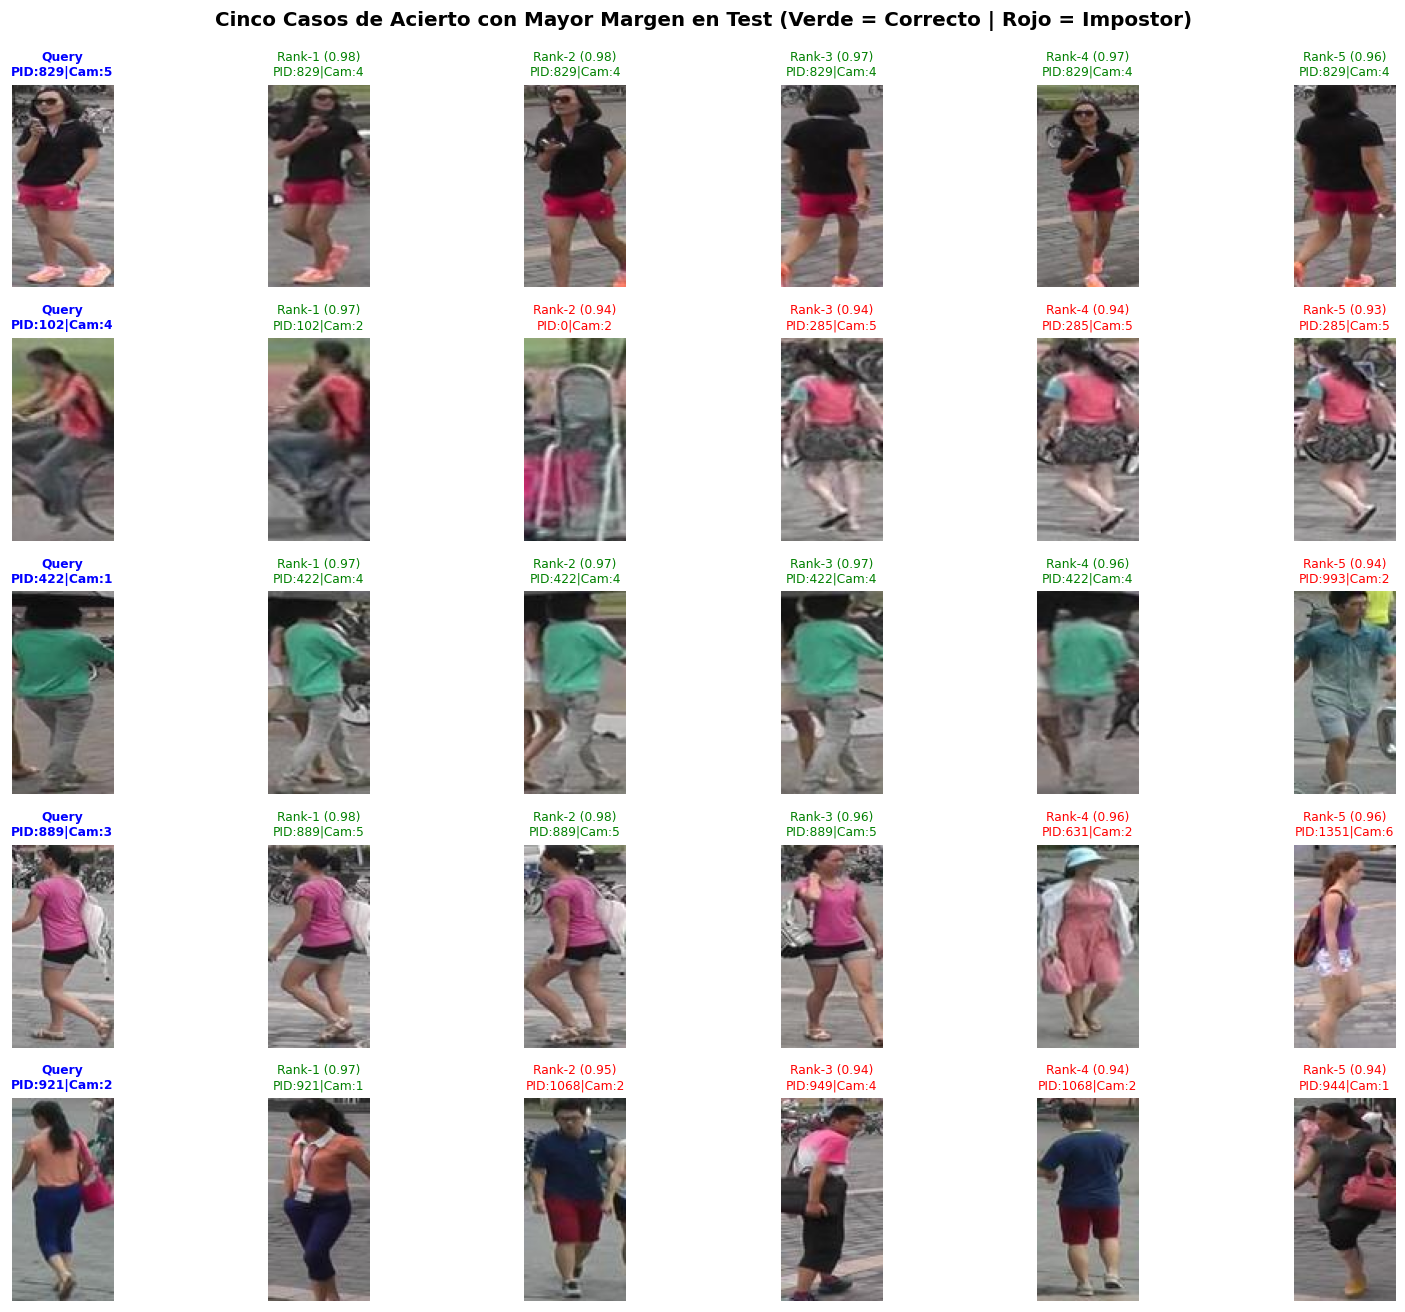

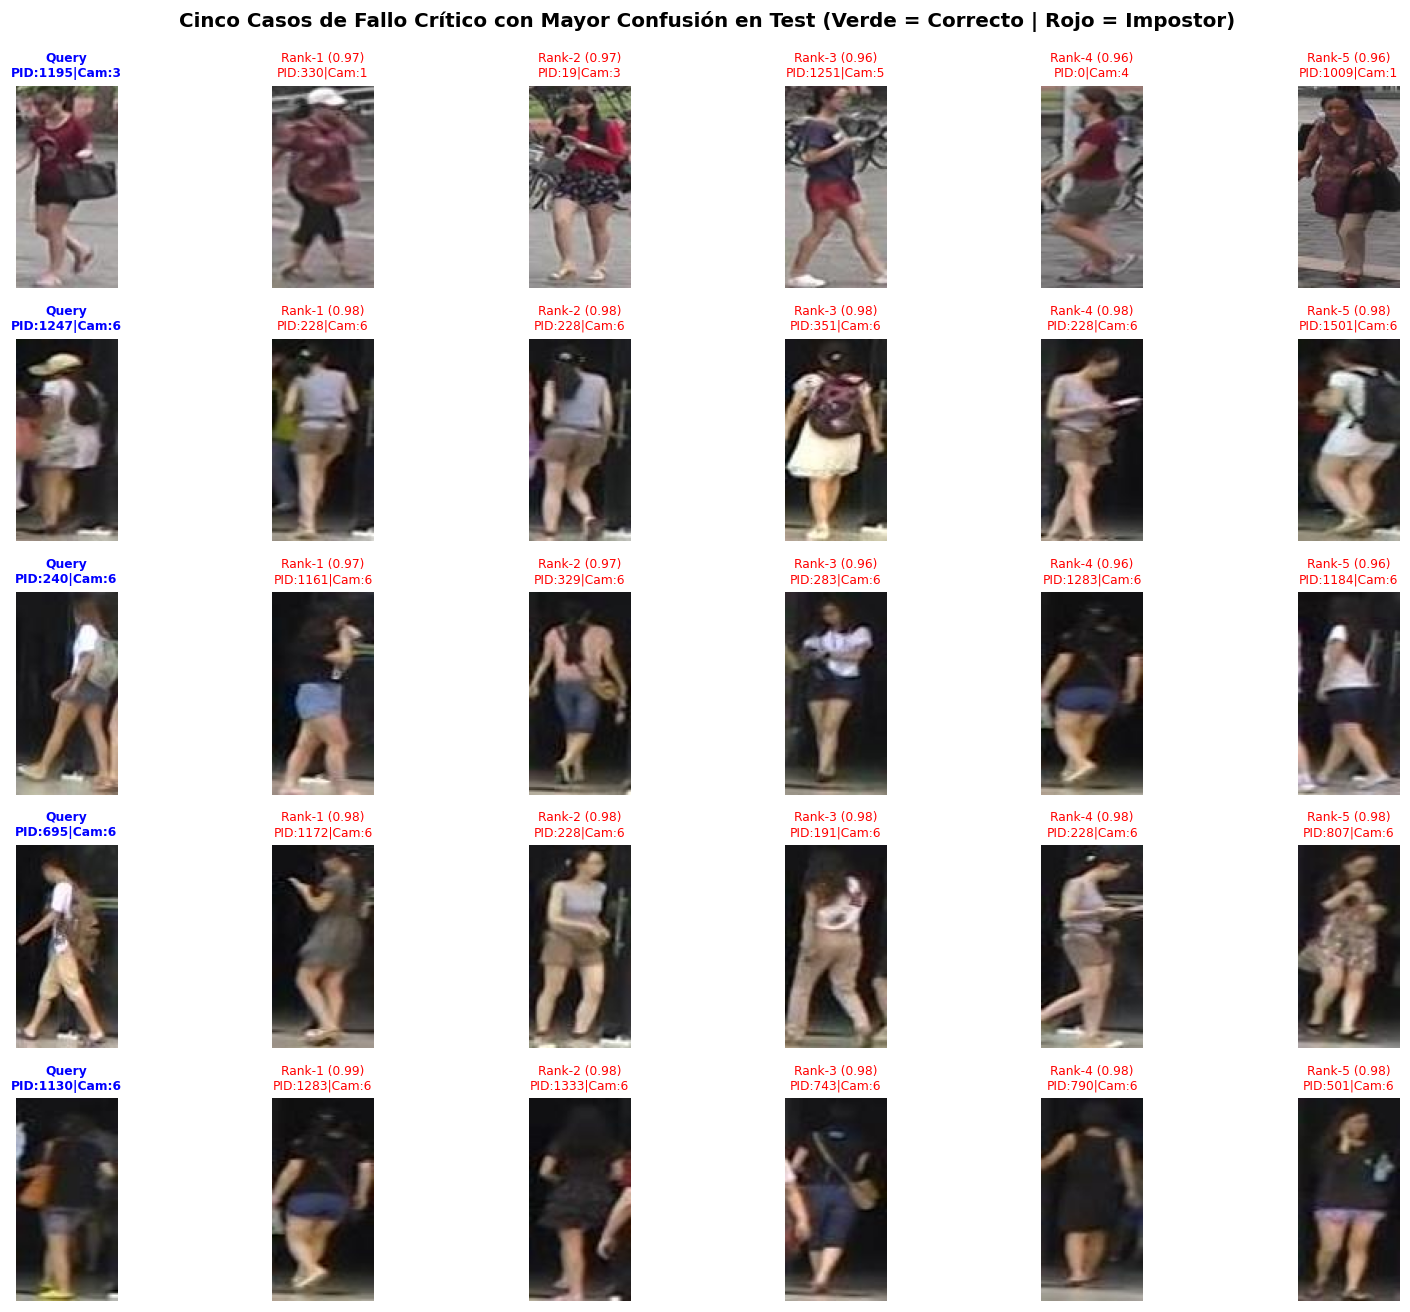

In [80]:
# Visualización de los 5 casos de acierto y 5 de fallo
if EJECUTAR_ENTRENAMIENTO_COMPLETO and all(n in globals() for n in ['model_baseline', 'model_retro', 'model_disco', 'model_nodis', 'model_retro_unadapted', 'teacher_enc', 'teacher_enc_imagenet']):
    if 'top_successes' in globals() and top_successes:
        fig, axes = plt.subplots(5, 6, figsize=(15, 12))
        fig.suptitle("Cinco Casos de Acierto con Mayor Margen en Test (Verde = Correcto | Rojo = Impostor)", fontsize=13, fontweight='bold', y=0.99)

        for row, it in enumerate(top_successes):
            q_img = test_q_images[it['q_idx']].transpose(1, 2, 0)
            axes[row, 0].imshow(q_img)
            axes[row, 0].set_title(f"Query\nPID:{it['qp']}|Cam:{it['qc']}", fontsize=8, color='blue', fontweight='bold')
            axes[row, 0].axis('off')
            
            for col, g_idx in enumerate(it['top5_indices']):
                correct = (test_g_pids[g_idx] == it['qp'])
                axes[row, col+1].imshow(test_g_images[g_idx].transpose(1, 2, 0))
                color = 'green' if correct else 'red'
                for s in axes[row, col+1].spines.values():
                    s.set_color(color)
                    s.set_linewidth(3)
                axes[row, col+1].set_title(f"Rank-{col+1} ({it['top5_sims'][col]:.2f})\nPID:{test_g_pids[g_idx]}|Cam:{test_g_cams[g_idx]}", fontsize=8, color=color)
                axes[row, col+1].axis('off')

        plt.tight_layout()
        plt.savefig(DIR_FIGS / 'cinco_aciertos_reid.png', dpi=150)
        plt.show()

    if 'top_failures' in globals() and top_failures:
        fig, axes = plt.subplots(5, 6, figsize=(15, 12))
        fig.suptitle("Cinco Casos de Fallo Crítico con Mayor Confusión en Test (Verde = Correcto | Rojo = Impostor)", fontsize=13, fontweight='bold', y=0.99)

        for row, it in enumerate(top_failures):
            q_img = test_q_images[it['q_idx']].transpose(1, 2, 0)
            axes[row, 0].imshow(q_img)
            axes[row, 0].set_title(f"Query\nPID:{it['qp']}|Cam:{it['qc']}", fontsize=8, color='blue', fontweight='bold')
            axes[row, 0].axis('off')
            
            for col, g_idx in enumerate(it['top5_indices']):
                correct = (test_g_pids[g_idx] == it['qp'])
                axes[row, col+1].imshow(test_g_images[g_idx].transpose(1, 2, 0))
                color = 'green' if correct else 'red'
                for s in axes[row, col+1].spines.values():
                    s.set_color(color)
                    s.set_linewidth(3)
                axes[row, col+1].set_title(f"Rank-{col+1} ({it['top5_sims'][col]:.2f})\nPID:{test_g_pids[g_idx]}|Cam:{test_g_cams[g_idx]}", fontsize=8, color=color)
                axes[row, col+1].axis('off')

        plt.tight_layout()
        plt.savefig(DIR_FIGS / 'cinco_fallos_reid.png', dpi=150)
        plt.show()
else:
    print("[OMITIDO] Esta celda requiere los modelos entrenados. Ejecuta el paso 2 (EJECUTAR_ENTRENAMIENTO_COMPLETO = True).")


**Análisis de los Casos Observados Basado en Evidencia Visible:**

Recordatorio del protocolo: se excluyen de la galería las fotos de la misma persona en la misma cámara. Por eso, un acierto implica reconocer a la persona **desde otra cámara**, mientras que los impostores sí pueden venir de la misma cámara.

**Aciertos (mayor margen frente al impostor más cercano):**
1. **PID 829 (cámara 5 → 4):** camiseta negra, short rojo y zapatillas naranjas. Las 5 primeras posiciones son la misma persona (similitud 0.96–0.98). La combinación de colores es muy llamativa y facilita la búsqueda.
2. **PID 102 (cámara 4 → 2):** persona en bicicleta con prenda rosada. Acierta en Rank-1 (0.968), pero en Rank-2 aparece un distractor (`pid 0`, recorte con objeto rosado) y en Rank-3 a 5 otra persona con blusa rosada (PID 285). El modelo se apoya en el color dominante; la bicicleta desempata.
3. **PID 422 (cámara 1 → 4):** camiseta verde y pantalón gris. Rank-1 a 4 correctos; el primer impostor (PID 993) viste tonos verde azulados.
4. **PID 889 (cámara 3 → 5):** blusa rosada, bolso blanco y short negro. Rank-1 a 3 correctos; los impostores comparten tonos rosados o morados.
5. **PID 921 (cámara 2 → 1):** blusa naranja, pantalón azul y bolso rosado. Solo Rank-1 es correcto (0.970); los impostores tienen prendas rojas o rosadas.

Patrón de los aciertos: ropa con colores vivos y contrastantes en cámaras bien iluminadas, con margen de 0.024–0.034 sobre el primer impostor. **Los 5 también aciertan con la consulta de baja resolución (32×16)**: el color global sobrevive a la pérdida de resolución, mientras que la textura fina se pierde.

**Fallos (mayor confusión a favor de un impostor):**
1. **PID 1195 (cámara 3):** blusa granate, short negro y bolso negro. Los 5 primeros resultados son otras personas (cámaras 1, 3, 5, 4 y 1, incluido un distractor `pid 0`) que también visten rojo o granate (similitud 0.96–0.97). La primera imagen correcta aparece recién en la posición 14,809 (similitud 0.687). El modelo agrupa por color de ropa y no por identidad.
2. **PID 1247 (cámara 6):** gorra y prenda clara. Los impostores (PID 228, 351, 1501) son todos de la cámara 6, con fondo oscuro y ropa clara; primera imagen correcta en la posición 10,157.
3. **PID 240 (cámara 6):** blusa blanca y short de jean. Los 5 impostores son de la cámara 6 con fondo oscuro; primera imagen correcta en la posición 7,868.
4. **PID 695 (cámara 6):** prenda clara, pantalón beige y mochila. Los 5 impostores son de la cámara 6 (similitud 0.977–0.981); primera imagen correcta en la posición 3,433.
5. **PID 1130 (cámara 6):** ropa oscura sobre fondo oscuro, casi sin información discriminativa. Los 5 impostores son de la cámara 6 (similitud hasta 0.987); primera imagen correcta en la posición 4,367.

Patrón de los fallos:
- **Sesgo de cámara:** 4 de los 5 fallos son de la cámara 6 y sus impostores también son de esa cámara. Al tener fondo oscuro y menor iluminación, el embedding codifica el entorno de la cámara en vez de la persona. Como el protocolo exige buscar en otra cámara, la imagen correcta queda miles de posiciones atrás.
- **Dependencia del color:** sin etiquetas, el modelo junta personas con ropa de color similar.
- **Baja resolución:** los 5 casos también fallan con consultas de 32×16.

Mejoras posibles sin etiquetas: usar `camera_ids` con negativos de la misma cámara o normalización por cámara, aumentaciones de color más fuertes (escala de grises, cambios de tono) y pseudo-etiquetas por clustering.


---
## 16. Interpretabilidad del Espacio Latente (t-SNE)

Proyectamos a 2D las representaciones del estudiante RETRO con maestro adaptado para identidades ($pid > 0$) presentes en varias cámaras.


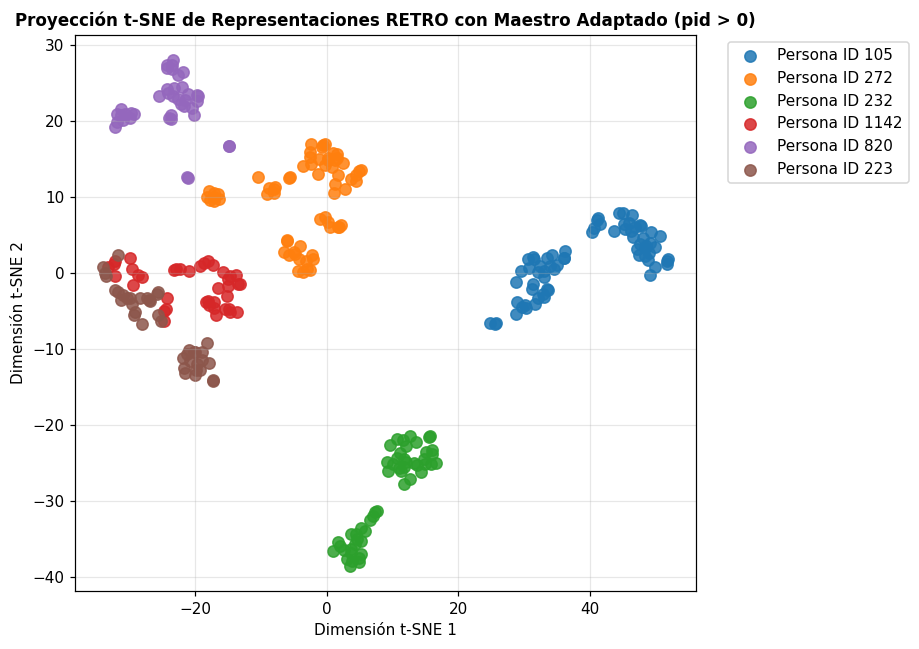

In [81]:
# Proyección t-SNE de representaciones RETRO con maestro adaptado
if EJECUTAR_ENTRENAMIENTO_COMPLETO and all(n in globals() for n in ['model_baseline', 'model_retro', 'model_disco', 'model_nodis', 'model_retro_unadapted', 'teacher_enc', 'teacher_enc_imagenet']):
    from sklearn.manifold import TSNE

    # Seleccionar las 6 identidades más frecuentes estrictamente entre pid > 0
    valid_mask = (val_g_pids > 0)
    valid_pids = val_g_pids[valid_mask]
    unique_pids, counts = np.unique(valid_pids, return_counts=True)
    top_pids = unique_pids[np.argsort(counts)[::-1][:6]]

    mask = np.isin(val_g_pids, top_pids)
    sub_feats = F.normalize(extract_features(model_retro, DataLoader(EvalDataset(val_g_images[mask]), batch_size=BATCH_SIZE, shuffle=False), DEVICE), p=2, dim=1).numpy()
    sub_pids = val_g_pids[mask]

    tsne = TSNE(n_components=2, random_state=SEED, perplexity=min(15, len(sub_pids)//4))
    emb_2d = tsne.fit_transform(sub_feats)

    plt.figure(figsize=(8.5, 6))
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
    for i, pid in enumerate(top_pids):
        m = (sub_pids == pid)
        plt.scatter(emb_2d[m, 0], emb_2d[m, 1], label=f'Persona ID {pid}', s=55, alpha=0.85, c=colors[i])

    plt.title("Proyección t-SNE de Representaciones RETRO con Maestro Adaptado (pid > 0)", fontsize=11, fontweight="bold")
    plt.xlabel("Dimensión t-SNE 1")
    plt.ylabel("Dimensión t-SNE 2")
    plt.legend(bbox_to_anchor=(1.04, 1), loc='upper left')
    plt.tight_layout()
    plt.savefig(DIR_FIGS / 'tsne_representaciones.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("[OMITIDO] Esta celda requiere los modelos entrenados. Ejecuta el paso 2 (EJECUTAR_ENTRENAMIENTO_COMPLETO = True).")


**Interpretación de la Proyección t-SNE:**

- Las 6 identidades graficadas forman grupos compactos y en general separados: el estudiante aprendió a acercar las imágenes de una misma persona sin haber visto etiquetas.
- Varias identidades (105, 272, 232 y 223) aparecen divididas en dos subgrupos, probablemente por cambios de cámara o de pose, lo que refleja la variación entre cámaras vista en los fallos.
- Las identidades 1142 y 223 quedan contiguas y algo mezcladas: confusión visual entre personas parecidas.
- **Precaución:** son solo 6 identidades con muchas imágenes, y t-SNE preserva vecindades locales pero no distancias globales. No contradice el mAP bajo en test, donde cada consulta compite contra 19,732 imágenes de 750 identidades más distractores.


---
## 17. Diferencias con el Paper Original

Estas son las principales diferencias entre lo que hace el paper y lo que implementamos:

1. **Datos y tarea:**
   - *Paper original:* ImageNet-1K (evaluación lineal y semi-supervisada), CIFAR-10 y CIFAR-100 (transferencia), y detección/segmentación en PASCAL VOC y COCO.
   - *Este laboratorio:* reidentificación de personas en Market-1501 (recuperación abierta entre 6 cámaras).
2. **Estrategia del maestro en dos etapas:**
   - *Paper original:* el maestro se preentrena solo en ImageNet y se asume alineado con los datos del estudiante.
   - *Este laboratorio:* como el dominio cambia mucho (ImageNet $\to$ peatones), usamos un maestro ResNet-50 en dos etapas: (1a) preentrenamiento MoCo-v2 en ImageNet; (1b) adaptación no supervisada sobre las 11,043 imágenes de `training.h5`. Probamos el maestro sin adaptar como control.
3. **Estudiante desde cero (`STUDENT_INIT = 'scratch'`):**
   - ResNet-18 no usa pesos preentrenados ni etiquetas de ImageNet; aprende solo con destilación y contraste sobre Market-1501.
4. **Relación de aspecto y resolución:**
   - Cambiamos imágenes cuadradas ($224 \times 224$) por resolución rectangular **$256 \times 128$**, adaptada a peatones.
5. **Tamaño de la cola de negativos:**
   - Redujimos la cola de MoCo de $K = 65,536$ a $K = 4096$ negativos, adecuada para las 11,043 imágenes de `training.h5`.
6. **Protocolo y métricas de evaluación:**
   - En vez de *top-1 accuracy* en clasificación lineal, evaluamos métricas de ranking (**mAP, Rank-1, Rank-5, Rank-10**) excluyendo basura y reteniendo distractores DPM.
7. **Presupuesto de entrenamiento:**
   - *Paper original:* 200 épocas, batch 256, hiperparámetros de MoCo-v2 ($m = 0.999$).
   - *Este laboratorio:* adaptación del maestro 40 épocas; estudiantes 50 épocas; batch 128 en una GPU T4 con precisión mixta; $m = 0.99$ elegido en validación (≈86 iteraciones por época).
8. **Arquitecturas evaluadas:**
   - *Paper original:* varios estudiantes (EfficientNet-B0/B1, MobileNetV3, ResNet-18/34) y maestros (ResNet-50/101/152).
   - *Este laboratorio:* un solo par maestro ResNet-50 $\to$ estudiante ResNet-18.
9. **Aumentación de baja resolución:**
   - Agregamos la degradación aleatoria a 32×16 ($p = 0.3$) para preparar la evaluación con consultas de baja resolución, que no existe en el paper.
10. **Vector de representación:**
    - Para Re-ID usamos $z_s \in \mathbb{R}^{512}$ (GAP del encoder) normalizado en $L_2$ con similitud coseno, no la salida de la cabeza de proyección.
11. **Comparabilidad de resultados:**
    - El paper no reporta métricas de Re-ID (mAP/CMC); solo contrastamos la tendencia de la ablación.
12. **Resultado de la ablación:**
    - El paper reporta que reutilizar la cabeza del maestro supera a DisCo (ResNet-18: 60.6 $\to$ 62.5 de top-1). En nuestro caso ambas variantes empatan (4.39 % vs 4.70 % de mAP, una sola semilla). Atribuimos la diferencia a la debilidad del maestro en Re-ID (ver Sección 14).
13. **Maestro con pseudo-etiquetas (versión 2, sección 19):** en el paper el maestro ya es fuerte en su dominio. Como el nuestro quedó por debajo del baseline, en la versión 2 lo seguimos entrenando con grupos obtenidos por clustering (Jaccard k-recíproca + DBSCAN) sobre `training.h5`, sin etiquetas reales. RETRO no cambia; solo cambia el maestro.
14. **Ablación con el maestro de la versión 2:** con el maestro 1c, la cabeza separada (15.48 % de mAP en test) superó a RETRO (13.50 %). El paper reporta lo contrario (ResNet-18: 60.6 → 62.5 de top-1 en ImageNet). Creemos que se debe a que nuestra cabeza g se entrenó con pseudo-etiquetas y no con MoCo (ver sección 19).
15. **Preentrenamiento del maestro (etapa 1a):** no repetimos el preentrenamiento MoCo-v2 en ImageNet que hace el paper; usamos los pesos públicos (800 épocas, sin etiquetas), porque repetirlo no es viable en una T4. Lo que sí entrenamos fueron las etapas 1b y 1c sobre `training.h5`.


In [82]:
# Resumen Ejecutivo generado dinámicamente desde las variables de resultados
if EJECUTAR_ENTRENAMIENTO_COMPLETO and all(n in globals() for n in ['model_baseline', 'model_retro', 'model_disco', 'model_nodis', 'model_retro_unadapted', 'teacher_enc', 'teacher_enc_imagenet']):
    print("=" * 75)
    print("RESUMEN EJECUTIVO DE RESULTADOS Y DESEMPEÑO (LABORATORIO 3 - VERSIÓN 1)")
    print("=" * 75)

    retro_res = test_results.get('2. RETRO con Maestro Adaptado', {})
    unadapt_res = test_results.get('5. RETRO con Maestro Sin Adaptar (Ablación)', {})
    base_res = test_results.get('1. Baseline (MoCo-v2 solo)', {})
    disco_res = test_results.get('3. Cabeza Separada (DisCo) con Maestro Adaptado', {})
    nodis_res = test_results.get('4. Solo Destilación (γ=0) con Maestro Adaptado', {})
    teach_ad_res = test_results.get('0b. Maestro Adaptado a Market (ResNet-50)', {})
    teach_im_res = test_results.get('0a. Maestro MoCo-v2 ImageNet (ResNet-50)', {})

    if retro_res and unadapt_res:
        r_map = retro_res['orig']['mAP'] * 100
        u_map = unadapt_res['orig']['mAP'] * 100
        gain_adapt = r_map - u_map
        pct_gain = (gain_adapt / u_map) * 100 if u_map > 0 else 0.0
        print(f"1. Impacto de Adaptar el Maestro : RETRO Adaptado {r_map:.2f}% vs Sin Adaptar {u_map:.2f}% (Δ: {gain_adapt:+.2f}%, {pct_gain:+.1f}% rel)")

    if base_res and retro_res:
        b_map = base_res['orig']['mAP'] * 100
        print(f"2. Comparación frente a Baseline : RETRO Adaptado {r_map:.2f}% vs Baseline {b_map:.2f}% (Δ: {r_map - b_map:+.2f}%)")

    if disco_res and retro_res:
        d_map = disco_res['orig']['mAP'] * 100
        print(f"3. Reutilización vs Cabeza Sep.  : RETRO {r_map:.2f}% vs DisCo {d_map:.2f}% (Δ: {r_map - d_map:+.2f}%)")

    if teach_ad_res and teach_im_res:
        ta_map = teach_ad_res['orig']['mAP'] * 100
        ti_map = teach_im_res['orig']['mAP'] * 100
        print(f"4. Desempeño de Maestros en Test : Adaptado {ta_map:.2f}% vs ImageNet {ti_map:.2f}% (Δ: {ta_map - ti_map:+.2f}%)")

    if retro_res and teach_ad_res:
        n_stud = retro_res['n_infer']
        n_teach = teach_ad_res['n_infer']
        print(f"5. Eficiencia de Parámetros      : Estudiante {n_stud:,} vs Maestro {n_teach:,} (~{n_stud/n_teach*100:.1f}%)")
    print("=" * 75)
else:
    print("[OMITIDO] Esta celda requiere los modelos entrenados. Ejecuta el paso 2 (EJECUTAR_ENTRENAMIENTO_COMPLETO = True).")


RESUMEN EJECUTIVO DE RESULTADOS Y DESEMPEÑO (LABORATORIO 3 - VERSIÓN 1)
1. Impacto de Adaptar el Maestro : RETRO Adaptado 4.39% vs Sin Adaptar 2.06% (Δ: +2.33%, +113.3% rel)
2. Comparación frente a Baseline : RETRO Adaptado 4.39% vs Baseline 5.84% (Δ: -1.45%)
3. Reutilización vs Cabeza Sep.  : RETRO 4.39% vs DisCo 4.70% (Δ: -0.31%)
4. Desempeño de Maestros en Test : Adaptado 4.97% vs ImageNet 1.35% (Δ: +3.62%)
5. Eficiencia de Parámetros      : Estudiante 11,176,512 vs Maestro 23,508,032 (~47.5%)


---
## 18. Conclusiones Finales

1. **Implementación:** implementamos RETRO desde cero con maestro ResNet-50 MoCo-v2 congelado, estudiante ResNet-18 desde cero que reutiliza la cabeza de proyección congelada del maestro mediante el adaptador del Apéndice D, Mean Student por EMA y función de pérdida $\mathcal{L} = \mathcal{L}_{dis} + \gamma\mathcal{L}_{con}$ con dos colas. Todo el entrenamiento fue no supervisado; usamos validación para elegir hiperparámetros y test solo para el reporte final.
2. **Adaptar el maestro es imprescindible:** sin adaptación, RETRO obtiene 2.06 % de mAP en test; con el maestro adaptado a Market sin etiquetas, sube a 4.39 % (×2.1), y la caída con consultas de baja resolución baja de 41.8 % a 6.6 %.
3. **La transferencia funciona:** el estudiante, con el 47.5 % de los parámetros, conserva el 88 % del mAP del maestro adaptado (4.39 % vs 4.97 %) y es más robusto a la baja resolución (caída de 6.6 % vs 14.3 %).
4. **El maestro es el techo:** el estudiante alcanza el nivel del maestro en pocas épocas y no lo supera; por eso RETRO no supera al baseline MoCo-v2 entrenado directamente en Market (5.84 % de mAP y caída de solo 0.2 %).
5. **Ablación:** reutilizar la cabeza del maestro no mostró ventaja frente a una cabeza propia (diferencia de 0.3 puntos, dentro del ruido de una sola semilla), a diferencia del paper. El término contrastivo $\mathcal{L}_{con}$ sí aporta robustez ante la baja resolución: sin él, la caída se duplica (13.5 % vs 6.6 %).
6. **Errores dominantes:** sesgo de cámara (4 de 5 fallos en la cámara 6, con impostores de la misma cámara) y dependencia del color de la ropa. Los aciertos corresponden a personas con colores llamativos y también funcionan con consultas de 32×16.
7. **Limitaciones y trabajo futuro:** evaluamos con una sola semilla, 50 épocas y un maestro débil. Para mejorar: probar más semillas para la ablación, un maestro con más épocas, usar `camera_ids` para reducir el sesgo de cámara y pseudo-etiquetas por clustering.

### Conclusiones de la versión 2

1. **Un maestro más fuerte cambia el resultado:** con pseudo-etiquetas, el maestro pasa de 4.97 % a 11.66 % de mAP en test y RETRO pasa de 4.39 % a 13.50 %, superando al baseline (5.84 %) en las dos condiciones.
2. **La transferencia funciona mejor con un buen maestro:** el estudiante, con el 47.5 % de los parámetros, supera a su maestro (116 % del mAP).
3. **Lo que más pesa es la calidad del maestro, no reutilizar su cabeza:** con el maestro 1c, la cabeza separada da el mejor resultado del laboratorio (15.48 % de mAP y 34.41 % de Rank-1). No reproducimos la ventaja de reutilizar la cabeza que reporta el paper.
4. **Limitaciones:** una sola semilla; los clusters (unos 250) probablemente son menos que las personas reales y mezclan personas parecidas; siguen el sesgo de la cámara 6 y la dependencia del color; y no alcanzamos a probar el baseline con clustering, así que no sabemos cuánto aportaría el clustering sin destilación.


---
## 19. Versión 2: RETRO con un maestro entrenado con pseudo-etiquetas

En la versión 1 el maestro adaptado (4.97 % de mAP en test) quedó por debajo del baseline (5.84 %), y como el estudiante aprende de él, RETRO no podía superar al baseline. El paper también muestra (sección 4.4) que RETRO mejora más cuanto mejor es el maestro.

Para tener un maestro más fuerte sin usar etiquetas, agregamos una etapa 1c:
1. Sacamos los vectores $z$ de las 11,043 imágenes de entrenamiento con el maestro.
2. Calculamos la distancia de Jaccard k-recíproca ($k_1=30$, $k_2=6$) y agrupamos con DBSCAN ($\varepsilon = 0.6$). Cada grupo se usa como si fuera una identidad; las imágenes que no caen en ningún grupo se dejan fuera en esa época.
3. Entrenamos el maestro (encoder y cabeza $g$) para acercar cada imagen al centro de su grupo, en $z$ y en $E = g(z)$. Así la cabeza que reutiliza RETRO también aprende estos grupos.
4. Repetimos el agrupamiento en cada época (20 épocas) y nos quedamos con el maestro que tiene mejor mAP en validación.

Después entrenamos RETRO igual que en el experimento 2 (mismo estudiante, pérdidas, épocas y $m$); solo cambia el maestro. La idea de entrenar con grupos viene de los métodos de Re-ID no supervisada como Cluster Contrast (Dai et al., 2022); el código lo escribimos nosotros y solo lo usamos para el maestro.

No usamos etiquetas de identidad: los grupos salen solo de `training.h5`. El maestro y el estudiante se eligen con validación, y test se evalúa una sola vez al final.

Tiempo aproximado en T4: 40 min el maestro, 50 min RETRO y unos 15 min la evaluación.


In [83]:
# Configuración
# v2: reentrenamos el maestro con pseudo-etiquetas (clusters) y luego RETRO otra vez
import gc
from sklearn.cluster import DBSCAN

EJECUTAR_EXTENSION_CC = True
EPOCHS_CC = 20            # épocas del maestro con clusters (~2 min c/u en T4)
CC_LR = 3.5e-5            # Adam (con 3.5e-4 el maestro colapsó)
CC_EPS = 0.6              # eps de DBSCAN (distancia de Jaccard)
CC_MIN_SAMPLES = 4
CC_K1, CC_K2 = 30, 6      # vecinos para Jaccard
CC_TEMP = 0.05
CC_MEM_M = 0.2            # momento para actualizar centroides
CC_BATCH = BATCH_SIZE
EPOCHS_RETRO_CC = EPOCHS_MAIN
RUN_ABLATION_CC = True    # True = también cabeza separada con el maestro nuevo (+50 min)
CC_MIN_CLUSTERS = 50      # con menos clusters algo salió mal

CC_TAG = f"cc_ep{EPOCHS_CC}_eps{CC_EPS}_lr{CC_LR}"
print("config v2:", CC_TAG)


config v2: cc_ep20_eps0.6_lr3.5e-05


In [84]:
# Distancia de Jaccard y clustering
def _k_reciprocal_neigh(initial_rank, i, k1):
    forward = initial_rank[i, :k1 + 1]
    backward = initial_rank[forward, :k1 + 1]
    return forward[np.where(backward == i)[0]]

def compute_jaccard_distance(feats, k1=30, k2=6, chunk=2048):
    # distancia de Jaccard k-recíproca (Zhong et al. 2017), devuelve matriz N x N
    t0 = time.time()
    feats = F.normalize(feats.float(), p=2, dim=1)
    N = feats.size(0)
    feats_dev = feats.to(DEVICE)

    # vecinos más cercanos por coseno (por bloques para no llenar la memoria)
    initial_rank = np.zeros((N, k1 + 1), dtype=np.int64)
    for s in range(0, N, chunk):
        sim = feats_dev[s:s + chunk] @ feats_dev.t()
        initial_rank[s:s + chunk] = sim.topk(k1 + 1, dim=1).indices.cpu().numpy()
    del feats_dev

    nn_k1 = [_k_reciprocal_neigh(initial_rank, i, k1) for i in range(N)]
    nn_k1_half = [_k_reciprocal_neigh(initial_rank, i, int(np.around(k1 / 2))) for i in range(N)]
    feats_np = feats.numpy()

    V = np.zeros((N, N), dtype=np.float32)
    for i in range(N):
        k_rec = nn_k1[i]
        k_rec_exp = k_rec
        for cand in k_rec:
            cand_k = nn_k1_half[cand]
            if len(np.intersect1d(cand_k, k_rec)) > 2 / 3 * len(cand_k):
                k_rec_exp = np.append(k_rec_exp, cand_k)
        k_rec_exp = np.unique(k_rec_exp)
        dist = 2.0 - 2.0 * (feats_np[k_rec_exp] @ feats_np[i])
        w = np.exp(-dist)
        V[i, k_rec_exp] = w / w.sum()

    # expansión con los k2 vecinos
    if k2 != 1:
        V_qe = np.zeros_like(V)
        for i in range(N):
            V_qe[i] = V[initial_rank[i, :k2]].mean(axis=0)
        V = V_qe
        del V_qe

    rows, cols = np.nonzero(V)
    order = np.argsort(cols, kind='stable')
    rows, cols = rows[order], cols[order]
    bounds = np.searchsorted(cols, np.arange(N + 1))
    inv_index = [rows[bounds[c]:bounds[c + 1]] for c in range(N)]

    jaccard = np.zeros((N, N), dtype=np.float32)
    for i in range(N):
        temp_min = np.zeros(N, dtype=np.float32)
        nz = np.where(V[i] != 0)[0]
        for c in nz:
            idx = inv_index[c]
            temp_min[idx] += np.minimum(V[i, c], V[idx, c])
        jaccard[i] = 1.0 - temp_min / (2.0 - temp_min)
    del V
    np.clip(jaccard, 0.0, None, out=jaccard)
    print(f"  jaccard: {time.time() - t0:.1f}s")
    return jaccard

def cluster_pseudo_labels(feats, eps=CC_EPS, min_samples=CC_MIN_SAMPLES, k1=CC_K1, k2=CC_K2):
    # -1 = outlier
    dist = compute_jaccard_distance(feats, k1=k1, k2=k2)
    labels = DBSCAN(eps=eps, min_samples=min_samples, metric='precomputed', n_jobs=-1).fit_predict(dist)
    del dist
    gc.collect()
    return labels


In [85]:
# Etapa 1c: maestro con pseudo-etiquetas
class ClusterDataset(Dataset):
    # solo las imágenes que quedaron en algún cluster, con su pseudo-etiqueta
    def __init__(self, images, indices, labels):
        self.images = images
        self.indices = indices
        self.labels = labels
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, j):
        img = torch.from_numpy(self.images[self.indices[j]]).float() / 255.0
        img = F.interpolate(img.unsqueeze(0), size=(256, 128), mode='bilinear', align_corners=False).squeeze(0)
        return img, int(self.labels[j])

train_eval_loader = DataLoader(EvalDataset(train_images), batch_size=256, shuffle=False, num_workers=2)

@torch.no_grad()
def extract_teacher_z_e(enc, g, loader):
    # z (2048) y E = g(z) (128), normalizados y sin aumentaciones
    enc.eval(); g.eval()
    zs, es = [], []
    for imgs in loader:
        x = normalize_imagenet(imgs.to(DEVICE))
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            z = enc(x)
            e = g(z)
        zs.append(F.normalize(z.float(), p=2, dim=1).cpu())
        es.append(F.normalize(e.float(), p=2, dim=1).cpu())
    return torch.cat(zs), torch.cat(es)

def eval_teacher_val(enc):
    q = extract_features(enc, val_q_loader, DEVICE, is_teacher=True)
    ql = extract_features(enc, val_q_low_loader, DEVICE, is_teacher=True)
    g_ = extract_features(enc, val_g_loader, DEVICE, is_teacher=True)
    r = evaluate_market1501(q, g_, val_q_pids, val_g_pids, val_q_cams, val_g_cams)
    rl = evaluate_market1501(ql, g_, val_q_pids, val_g_pids, val_q_cams, val_g_cams)
    return r, rl

def train_teacher_cluster(start_enc_sd, start_g_sd, epochs=EPOCHS_CC, lr=CC_LR):
    ckpt_best = DIR_CKPT / f"teacher_{CC_TAG}_best.pt"
    ckpt_last = DIR_CKPT / f"teacher_{CC_TAG}_last.pt"

    # si ya terminó antes, solo cargamos
    if ckpt_best.exists() and ckpt_last.exists() and not FORCE_RETRAIN:
        cl = torch.load(ckpt_last, map_location='cpu', weights_only=False)
        if cl['epoch'] >= epochs or cl.get('detenido', False):
            cb = torch.load(ckpt_best, map_location='cpu', weights_only=False)
            print(f"ya entrenado ({cl['epoch']} épocas), mejor val mAP {cb['best_val_mAP']*100:.2f}% en época {cb['epoch']}")
            return cb['enc'], cb['g'], cl['history']

    enc = models.resnet50(weights=None); enc.fc = nn.Identity()
    enc.load_state_dict(start_enc_sd)
    g = nn.Sequential(nn.Linear(2048, 2048), nn.ReLU(inplace=True), nn.Linear(2048, 128))
    g.load_state_dict(start_g_sd)
    enc.to(DEVICE); g.to(DEVICE)
    for p in list(enc.parameters()) + list(g.parameters()):
        p.requires_grad = True

    params = list(enc.parameters()) + list(g.parameters())
    optimizer = torch.optim.Adam(params, lr=lr, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, epochs - 1))
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    history = {'loss': [], 'n_clusters': [], 'n_outliers': [], 'val_mAP': [], 'val_rank1': [], 'val_mAP_low': []}
    start_epoch = 1

    bajas = 0
    if ckpt_last.exists() and not FORCE_RETRAIN:
        cl = torch.load(ckpt_last, map_location=DEVICE, weights_only=False)
        enc.load_state_dict(cl['enc']); g.load_state_dict(cl['g'])
        optimizer.load_state_dict(cl['optimizer']); scheduler.load_state_dict(cl['scheduler'])
        scaler.load_state_dict(cl['scaler'])
        history = cl['history']; best_val_mAP = cl['best_val_mAP']
        start_epoch = cl['epoch'] + 1
        print(f"continuando desde la época {start_epoch}")
    else:
        r0, rl0 = eval_teacher_val(enc)
        best_val_mAP = r0['mAP']
        torch.save({'enc': enc.state_dict(), 'g': g.state_dict(), 'best_val_mAP': best_val_mAP,
                    'val': {'orig': r0, 'low': rl0}, 'epoch': 0}, ckpt_best)
        print(f"época 0 (maestro 1b) | val mAP {r0['mAP']*100:.2f}% | R1 {r0['Rank-1']*100:.2f}% | baja res {rl0['mAP']*100:.2f}%")

    for epoch in range(start_epoch, epochs + 1):
        t0 = time.time()
        # 1) pseudo-etiquetas con el maestro actual
        z_all, e_all = extract_teacher_z_e(enc, g, train_eval_loader)
        labels = cluster_pseudo_labels(z_all)
        keep = np.where(labels >= 0)[0]
        n_cls = int(labels.max()) + 1 if len(keep) > 0 else 0
        n_out = int((labels < 0).sum())
        if n_cls < CC_MIN_CLUSTERS:
            # los clusters se están fusionando: paramos y nos quedamos con el mejor maestro guardado
            print(f"solo {n_cls} clusters: se detiene y se usa el mejor maestro guardado")
            torch.save({'enc': enc.state_dict(), 'g': g.state_dict(), 'history': history,
                        'best_val_mAP': best_val_mAP, 'epoch': epoch - 1, 'detenido': True}, ckpt_last)
            break

        # 2) centroides de cada cluster (en z y en E)
        y_keep = torch.from_numpy(labels[keep]).long()
        def centroids(f):
            c = torch.zeros(n_cls, f.size(1))
            c.index_add_(0, y_keep, f[keep])
            return F.normalize(c, p=2, dim=1).to(DEVICE)
        mem_z, mem_e = centroids(z_all), centroids(e_all)
        del z_all, e_all

        # 3) entrenar acercando cada imagen al centroide de su cluster
        loader = DataLoader(ClusterDataset(train_images, keep, labels[keep]), batch_size=CC_BATCH,
                            shuffle=True, drop_last=True, num_workers=2, pin_memory=(DEVICE.type == 'cuda'))
        enc.train(); g.train()
        total, nb = 0.0, 0
        for it, (bx, by) in enumerate(loader):
            if epoch == 1:  # warmup
                for pg in optimizer.param_groups:
                    pg['lr'] = lr * (it + 1) / len(loader)
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                x = normalize_imagenet(batch_augment(bx))
                z = enc(x)
                e = g(z)
            zn = F.normalize(z.float(), p=2, dim=1)
            en = F.normalize(e.float(), p=2, dim=1)
            loss = F.cross_entropy(zn @ mem_z.t() / CC_TEMP, by) + F.cross_entropy(en @ mem_e.t() / CC_TEMP, by)

            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(params, max_norm=5.0)
            scaler.step(optimizer)
            scaler.update()

            with torch.no_grad():  # actualizar centroides
                for mem, f in ((mem_z, zn.detach()), (mem_e, en.detach())):
                    upd = torch.zeros_like(mem).index_add_(0, by, f)
                    cnt = torch.bincount(by, minlength=mem.size(0)).float().unsqueeze(1)
                    hit = cnt.squeeze(1) > 0
                    mem[hit] = F.normalize(CC_MEM_M * mem[hit] + (1 - CC_MEM_M) * upd[hit] / cnt[hit], p=2, dim=1)
            total += loss.item(); nb += 1
        if epoch > 1:
            scheduler.step()

        r, rl = eval_teacher_val(enc)
        history['loss'].append(total / max(nb, 1)); history['n_clusters'].append(n_cls); history['n_outliers'].append(n_out)
        history['val_mAP'].append(r['mAP']); history['val_rank1'].append(r['Rank-1']); history['val_mAP_low'].append(rl['mAP'])
        print(f"época {epoch}/{epochs} ({time.time() - t0:.0f}s) | clusters {n_cls} | outliers {n_out} | "
              f"loss {total / max(nb, 1):.3f} | val mAP {r['mAP']*100:.2f}% | R1 {r['Rank-1']*100:.2f}% | baja res {rl['mAP']*100:.2f}%")

        if r['mAP'] > best_val_mAP:
            best_val_mAP = r['mAP']
            torch.save({'enc': enc.state_dict(), 'g': g.state_dict(), 'best_val_mAP': best_val_mAP,
                        'val': {'orig': r, 'low': rl}, 'epoch': epoch}, ckpt_best)
            print("  guardado como mejor")
        # si el val mAP cae más de 3 puntos bajo el mejor dos épocas seguidas, paramos
        bajas = bajas + 1 if r['mAP'] < best_val_mAP - 0.03 else 0
        detenido = bajas >= 2
        torch.save({'enc': enc.state_dict(), 'g': g.state_dict(), 'optimizer': optimizer.state_dict(),
                    'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict(),
                    'history': history, 'best_val_mAP': best_val_mAP, 'epoch': epoch, 'detenido': detenido}, ckpt_last)
        del mem_z, mem_e, loader
        gc.collect()
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
        if detenido:
            print("val mAP cayendo dos épocas seguidas: se detiene y se usa el mejor maestro guardado")
            break

    cb = torch.load(ckpt_best, map_location='cpu', weights_only=False)
    print(f"mejor maestro: época {cb['epoch']}, val mAP {cb['best_val_mAP']*100:.2f}%")
    return cb['enc'], cb['g'], history

if EJECUTAR_EXTENSION_CC and EJECUTAR_ENTRENAMIENTO_COMPLETO:
    cc_enc_sd, cc_g_sd, cc_history = train_teacher_cluster(teacher_enc.state_dict(), teacher_g.state_dict())

    # maestro final congelado
    teacher_enc_cc = models.resnet50(weights=None); teacher_enc_cc.fc = nn.Identity()
    teacher_enc_cc.load_state_dict(cc_enc_sd)
    teacher_g_cc = nn.Sequential(nn.Linear(2048, 2048), nn.ReLU(inplace=True), nn.Linear(2048, 128))
    teacher_g_cc.load_state_dict(cc_g_sd)
    for p in list(teacher_enc_cc.parameters()) + list(teacher_g_cc.parameters()):
        p.requires_grad = False
    teacher_enc_cc.eval().to(DEVICE); teacher_g_cc.eval().to(DEVICE)
else:
    print("v2 desactivada")


ya entrenado (20 épocas), mejor val mAP 28.03% en época 15


In [86]:
# RETRO con el maestro nuevo
# igual que el experimento 2, solo cambia el maestro
if EJECUTAR_EXTENSION_CC and EJECUTAR_ENTRENAMIENTO_COMPLETO:
    stud_cc = ResNet18Student(init=STUDENT_INIT).to(DEVICE)
    adapt_cc = AdapterAppendixD(512, 2048).to(DEVICE)
    model_retro_cc = RETROModel(stud_cc, teacher_enc_cc, teacher_g_cc, adapter=adapt_cc, reuse_proj=True).to(DEVICE)
    hist_retro_cc, val_retro_cc = train_experiment(f"exp6_retro_full_{CONFIG_ID}_{CC_TAG}", model_retro_cc,
                                                   epochs=EPOCHS_RETRO_CC, gamma=1.0, use_distill=True, use_contrastive=True)
    if RUN_ABLATION_CC:
        stud_disco_cc = ResNet18Student(init=STUDENT_INIT).to(DEVICE)
        model_disco_cc = RETROModel(stud_disco_cc, teacher_enc_cc, teacher_g_cc, adapter=None, reuse_proj=False).to(DEVICE)
        hist_disco_cc, val_disco_cc = train_experiment(f"exp7_separate_head_{CONFIG_ID}_{CC_TAG}", model_disco_cc,
                                                       epochs=EPOCHS_RETRO_CC, gamma=1.0, use_distill=True, use_contrastive=True)
else:
    print("v2 desactivada")


[CACHE] Experimento 'exp6_retro_full_bs128_scratch_ep50_m0.99_cc_ep20_eps0.6_lr3.5e-05' ya completó 50/50 épocas.
        Cargando mejor modelo desde: exp6_retro_full_bs128_scratch_ep50_m0.99_cc_ep20_eps0.6_lr3.5e-05_best.pt

INICIANDO / REANUDANDO ENTRENAMIENTO: exp7_separate_head_bs128_scratch_ep50_m0.99_cc_ep20_eps0.6_lr3.5e-05
Épocas Objetivo: 50 | LR: 0.01500 | Gamma: 1.0 | Momento: 0.99 | AMP: True


/tmp/ipykernel_57725/2366739633.py:38: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
/tmp/ipykernel_57725/2366739633.py:74: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=USE_AMP):


Época [01/50] (55.1s) | Loss: 9.2953 (Dis: 2.3294, Con: 6.9659) | Val mAP: 13.67%, Rank-1: 29.00% | Baja Res mAP: 11.65%
  -> Nuevo mejor modelo guardado en exp7_separate_head_bs128_scratch_ep50_m0.99_cc_ep20_eps0.6_lr3.5e-05_best.pt (Val mAP: 13.67%)
Época [02/50] (57.6s) | Loss: 8.5380 (Dis: 1.8308, Con: 6.7073) | Val mAP: 20.38%, Rank-1: 42.00% | Baja Res mAP: 19.90%
  -> Nuevo mejor modelo guardado en exp7_separate_head_bs128_scratch_ep50_m0.99_cc_ep20_eps0.6_lr3.5e-05_best.pt (Val mAP: 20.38%)
Época [03/50] (58.8s) | Loss: 7.4759 (Dis: 1.4860, Con: 5.9899) | Val mAP: 23.40%, Rank-1: 45.00% | Baja Res mAP: 22.42%
  -> Nuevo mejor modelo guardado en exp7_separate_head_bs128_scratch_ep50_m0.99_cc_ep20_eps0.6_lr3.5e-05_best.pt (Val mAP: 23.40%)
Época [04/50] (58.5s) | Loss: 6.8186 (Dis: 1.2803, Con: 5.5383) | Val mAP: 25.73%, Rank-1: 47.00% | Baja Res mAP: 24.28%
  -> Nuevo mejor modelo guardado en exp7_separate_head_bs128_scratch_ep50_m0.99_cc_ep20_eps0.6_lr3.5e-05_best.pt (Val mAP: 

In [87]:
# Test
if EJECUTAR_EXTENSION_CC and EJECUTAR_ENTRENAMIENTO_COMPLETO:
    test_q_loader = DataLoader(EvalDataset(test_q_images), batch_size=BATCH_SIZE, shuffle=False)
    test_q_low_loader = DataLoader(EvalDataset(test_q_low_images), batch_size=BATCH_SIZE, shuffle=False)
    test_g_loader = DataLoader(EvalDataset(test_g_images), batch_size=BATCH_SIZE, shuffle=False)

    ext_models = {
        'Baseline (MoCo-v2)': (model_baseline, False),
        'Maestro 1b (adaptado)': (teacher_enc, True),
        'RETRO con maestro 1b': (model_retro, False),
        'Maestro 1c (clusters)': (teacher_enc_cc, True),
        'RETRO con maestro 1c': (model_retro_cc, False),
    }
    if RUN_ABLATION_CC:
        ext_models['Cabeza separada con maestro 1c'] = (model_disco_cc, False)

    ext_rows, ext_results = [], {}
    for name, (m, is_t) in ext_models.items():
        print("evaluando", name)
        qf = extract_features(m, test_q_loader, DEVICE, is_teacher=is_t)
        qlf = extract_features(m, test_q_low_loader, DEVICE, is_teacher=is_t)
        gf = extract_features(m, test_g_loader, DEVICE, is_teacher=is_t)
        r = evaluate_market1501(qf, gf, test_q_pids, test_g_pids, test_q_cams, test_g_cams)
        rl = evaluate_market1501(qlf, gf, test_q_pids, test_g_pids, test_q_cams, test_g_cams)
        d = r['mAP'] - rl['mAP']
        ext_results[name] = {'orig': r, 'low': rl, 'delta_mAP': d, 'pct_drop_mAP': 100 * d / r['mAP'] if r['mAP'] > 0 else 0.0}
        ext_rows.append({'Modelo': name, 'mAP': f"{r['mAP']*100:.2f}%", 'R1': f"{r['Rank-1']*100:.2f}%",
                         'R5': f"{r['Rank-5']*100:.2f}%", 'R10': f"{r['Rank-10']*100:.2f}%",
                         'mAP baja res': f"{rl['mAP']*100:.2f}%", 'R1 baja res': f"{rl['Rank-1']*100:.2f}%",
                         'caída': f"{ext_results[name]['pct_drop_mAP']:.1f}%"})

    with open(DIR_OUT / f'test_results_v2_{CC_TAG}.json', 'w', encoding='utf-8') as f:
        json.dump(ext_results, f, indent=2)
    df_ext = pd.DataFrame(ext_rows)
    df_ext.to_csv(DIR_OUT / f'test_summary_v2_{CC_TAG}.csv', index=False)
    display(df_ext) if 'display' in dir() else print(df_ext.to_string())

    b = ext_results['Baseline (MoCo-v2)']['orig']['mAP']
    rc = ext_results['RETRO con maestro 1c']['orig']['mAP']
    tc = ext_results['Maestro 1c (clusters)']['orig']['mAP']
    print(f"RETRO 1c {rc*100:.2f}% vs baseline {b*100:.2f}% ({100*(rc-b):+.2f} pts); el estudiante llega al {100*rc/tc:.0f}% del maestro")
else:
    print("v2 desactivada")


evaluando Baseline (MoCo-v2)
evaluando Maestro 1b (adaptado)
evaluando RETRO con maestro 1b
evaluando Maestro 1c (clusters)
evaluando RETRO con maestro 1c
evaluando Cabeza separada con maestro 1c
                           Modelo     mAP      R1      R5     R10 mAP baja res R1 baja res  caída
0              Baseline (MoCo-v2)   5.84%  14.58%  27.38%  34.32%        5.83%      14.70%   0.2%
1           Maestro 1b (adaptado)   4.97%  15.29%  26.96%  34.29%        4.26%      13.00%  14.3%
2            RETRO con maestro 1b   4.39%  11.61%  23.46%  31.12%        4.10%      10.18%   6.6%
3           Maestro 1c (clusters)  11.66%  27.76%  42.73%  49.73%        9.63%      22.27%  17.4%
4            RETRO con maestro 1c  13.50%  31.00%  46.44%  53.62%       12.13%      26.90%  10.2%
5  Cabeza separada con maestro 1c  15.48%  34.41%  49.82%  56.77%       14.18%      31.00%   8.4%
RETRO 1c 13.50% vs baseline 5.84% (+7.66 pts); el estudiante llega al 116% del maestro


Aciertos 1: query 1221 (cám 3) | top-5 (1221, c5, 0.979), (1221, c5, 0.974), (1221, c5, 0.943), (1221, c1, 0.924), (0, c6, 0.917) | primer acierto en 1 | baja res: no
Aciertos 2: query 41 (cám 5) | top-5 (41, c3, 0.984), (41, c1, 0.943), (41, c3, 0.936), (182, c1, 0.923), (94, c6, 0.921) | primer acierto en 1 | baja res: sí
Aciertos 3: query 238 (cám 2) | top-5 (238, c3, 0.947), (238, c3, 0.942), (238, c3, 0.935), (238, c5, 0.892), (921, c2, 0.886) | primer acierto en 1 | baja res: sí
Aciertos 4: query 889 (cám 3) | top-5 (889, c5, 0.981), (889, c5, 0.972), (889, c5, 0.971), (889, c4, 0.949), (889, c4, 0.945) | primer acierto en 1 | baja res: sí
Aciertos 5: query 1196 (cám 3) | top-5 (1196, c5, 0.981), (1196, c5, 0.964), (1196, c5, 0.926), (831, c5, 0.923), (819, c5, 0.922) | primer acierto en 1 | baja res: sí


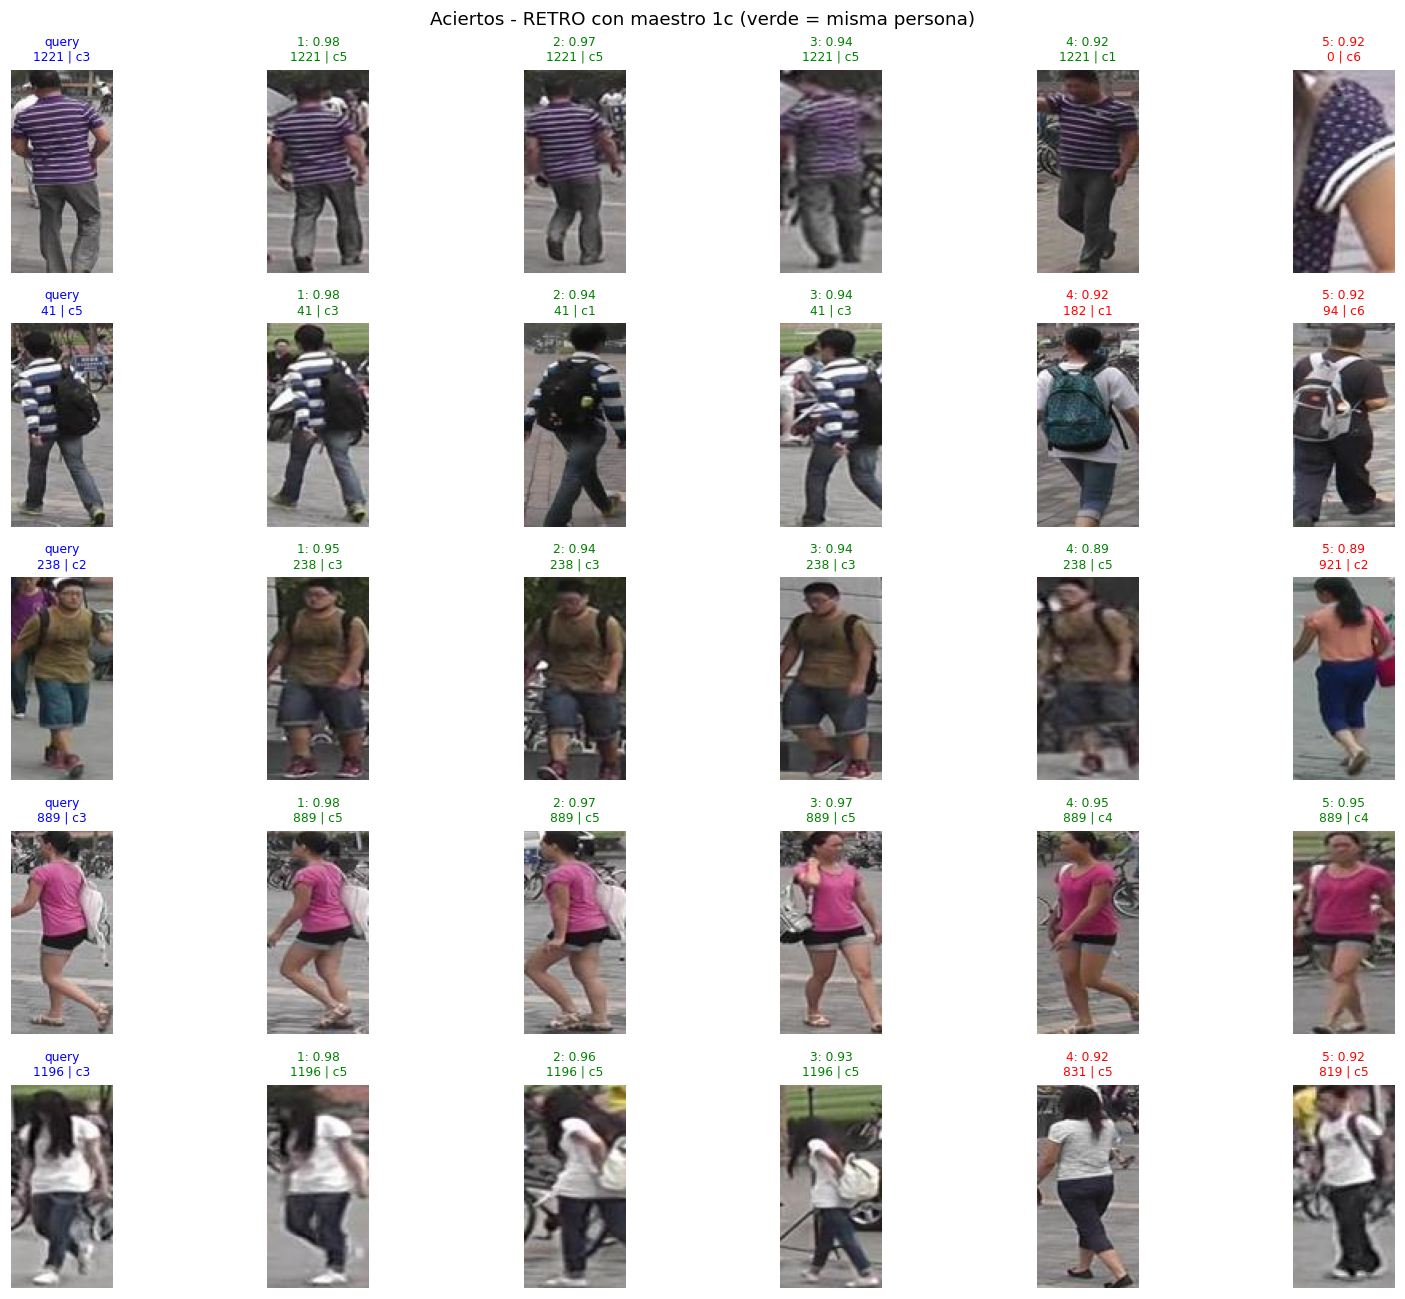

Fallos 1: query 1499 (cám 6) | top-5 (1376, c1, 0.999), (1396, c2, 0.999), (812, c6, 0.999), (1153, c1, 0.999), (805, c6, 0.999) | primer acierto en 769 | baja res: no
Fallos 2: query 678 (cám 6) | top-5 (1248, c6, 0.977), (286, c6, 0.970), (286, c6, 0.970), (286, c6, 0.969), (1362, c6, 0.968) | primer acierto en 2861 | baja res: no
Fallos 3: query 1040 (cám 6) | top-5 (925, c6, 0.979), (813, c6, 0.972), (897, c6, 0.969), (717, c6, 0.968), (1042, c6, 0.968) | primer acierto en 2945 | baja res: no
Fallos 4: query 213 (cám 6) | top-5 (790, c6, 0.981), (675, c6, 0.973), (790, c6, 0.972), (790, c6, 0.969), (600, c6, 0.967) | primer acierto en 3351 | baja res: no
Fallos 5: query 1414 (cám 6) | top-5 (165, c6, 0.961), (1382, c6, 0.961), (1283, c6, 0.960), (1419, c6, 0.955), (743, c6, 0.954) | primer acierto en 6187 | baja res: no


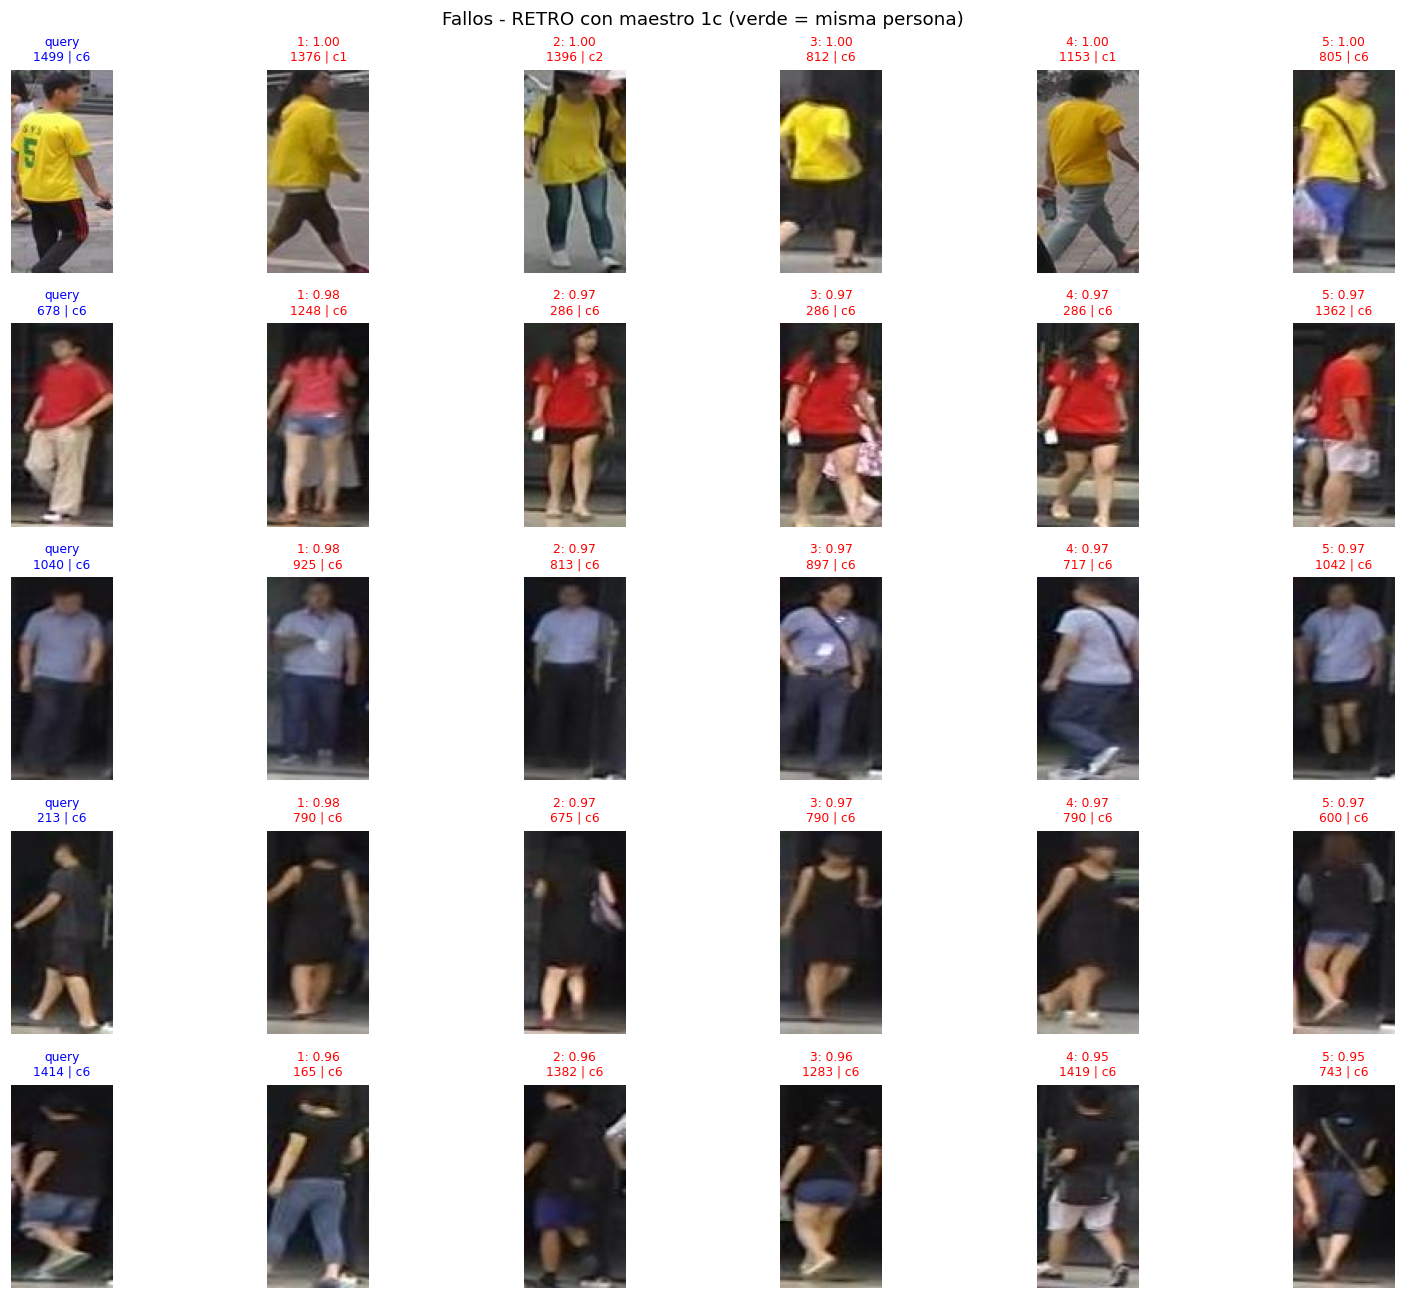

In [88]:
# Aciertos y fallos de RETRO con maestro 1c
def select_cases(model, n=5):
    # mismo criterio que en la sección 15: mayor margen (aciertos) y mayor confusión (fallos)
    qf = F.normalize(extract_features(model, test_q_loader, DEVICE), p=2, dim=1)
    qlf = F.normalize(extract_features(model, test_q_low_loader, DEVICE), p=2, dim=1)
    gf = F.normalize(extract_features(model, test_g_loader, DEVICE), p=2, dim=1)
    sim, sim_low = (qf @ gf.t()).numpy(), (qlf @ gf.t()).numpy()
    qp_a, qc_a = np.asarray(test_q_pids), np.asarray(test_q_cams)
    gp_a, gc_a = np.asarray(test_g_pids), np.asarray(test_g_cams)
    oks, fails = [], []
    for i in range(len(qp_a)):
        qp, qc = qp_a[i], qc_a[i]
        order = np.argsort(-sim[i])
        valid = order[~(((gp_a[order] == qp) & (gc_a[order] == qc)) | (gp_a[order] == -1))]
        pos = np.where(gp_a[valid] == qp)[0]
        neg = np.where(gp_a[valid] != qp)[0]
        if len(valid) < 5 or len(pos) == 0:
            continue
        order_l = np.argsort(-sim_low[i])
        valid_l = order_l[~(((gp_a[order_l] == qp) & (gc_a[order_l] == qc)) | (gp_a[order_l] == -1))]
        c_sim = sim[i, valid[pos[0]]]
        it = {'q_idx': i, 'qp': qp, 'qc': qc, 'top5_indices': valid[:5],
              'top5_pids': gp_a[valid[:5]].tolist(), 'top5_cams': gc_a[valid[:5]].tolist(),
              'top5_sims': [float(sim[i, j]) for j in valid[:5]],
              'first_correct_rank': int(pos[0] + 1), 'first_correct_sim': float(c_sim),
              'margin': float(c_sim - (sim[i, valid[neg[0]]] if len(neg) else 0.0)),
              'confusion': float(sim[i, valid[0]] - c_sim),
              'succeeds_low_res': bool(gp_a[valid_l[0]] == qp)}
        (oks if gp_a[valid[0]] == qp else fails).append(it)
    return (sorted(oks, key=lambda x: x['margin'], reverse=True)[:n],
            sorted(fails, key=lambda x: x['confusion'], reverse=True)[:n])

def show_cases(cases, title, fname):
    if not cases:
        print("no hay casos:", title)
        return
    for k, it in enumerate(cases, 1):
        print(f"{title} {k}: query {it['qp']} (cám {it['qc']}) | top-5 " +
              ", ".join(f"({p}, c{c}, {s:.3f})" for p, c, s in zip(it['top5_pids'], it['top5_cams'], it['top5_sims'])) +
              f" | primer acierto en {it['first_correct_rank']} | baja res: {'sí' if it['succeeds_low_res'] else 'no'}")
    fig, axes = plt.subplots(len(cases), 6, figsize=(15, 2.4 * len(cases)), squeeze=False)
    fig.suptitle(f"{title} - RETRO con maestro 1c (verde = misma persona)", fontsize=12)
    for r, it in enumerate(cases):
        axes[r, 0].imshow(test_q_images[it['q_idx']].transpose(1, 2, 0))
        axes[r, 0].set_title(f"query\n{it['qp']} | c{it['qc']}", fontsize=8, color='blue'); axes[r, 0].axis('off')
        for c, gi in enumerate(it['top5_indices']):
            col = 'green' if test_g_pids[gi] == it['qp'] else 'red'
            axes[r, c + 1].imshow(test_g_images[gi].transpose(1, 2, 0))
            axes[r, c + 1].set_title(f"{c+1}: {it['top5_sims'][c]:.2f}\n{test_g_pids[gi]} | c{test_g_cams[gi]}", fontsize=8, color=col)
            axes[r, c + 1].axis('off')
    plt.tight_layout()
    plt.savefig(DIR_FIGS / fname, dpi=150)
    plt.show()

if EJECUTAR_EXTENSION_CC and EJECUTAR_ENTRENAMIENTO_COMPLETO:
    cc_successes, cc_failures = select_cases(model_retro_cc)
    show_cases(cc_successes, "Aciertos", 'aciertos_retro_cc.png')
    show_cases(cc_failures, "Fallos", 'fallos_retro_cc.png')
else:
    print("v2 desactivada")


### Resultados de la versión 2

Resultados en test (3,368 consultas contra 19,732 imágenes de galería):

| Modelo | mAP | R1 | R5 | R10 | mAP baja res | Caída |
|---|---|---|---|---|---|---|
| Baseline MoCo-v2 (ResNet-18) | 5.84 % | 14.58 % | 27.38 % | 34.32 % | 5.83 % | 0.2 % |
| Maestro 1b (ResNet-50, v1) | 4.97 % | 15.29 % | 26.96 % | 34.29 % | 4.26 % | 14.3 % |
| RETRO con maestro 1b (v1) | 4.39 % | 11.61 % | 23.46 % | 31.12 % | 4.10 % | 6.6 % |
| Maestro 1c (ResNet-50, clusters) | 11.66 % | 27.76 % | 42.73 % | 49.73 % | 9.63 % | 17.4 % |
| RETRO con maestro 1c | 13.50 % | 31.00 % | 46.44 % | 53.62 % | 12.13 % | 10.2 % |
| Cabeza separada con maestro 1c | 15.48 % | 34.41 % | 49.82 % | 56.77 % | 14.18 % | 8.4 % |

**1. El maestro mejoró.** Con pseudo-etiquetas, el maestro pasó de 15.47 % a 28.03 % de mAP en validación (mejor época: 15) y de 4.97 % a 11.66 % en test. Los clusters se mantuvieron entre 240 y 290, y los outliers bajaron de 3,169 a 754. En el primer intento, con learning rate 3.5e-4, el maestro colapsó: los clusters se fueron fusionando (de 372 a 44) y el mAP de validación cayó a 2.3 %. Con 3.5e-5 el entrenamiento fue estable.

**2. RETRO ahora supera al baseline.** Con el maestro 1c, RETRO llega a 13.50 % de mAP frente a 5.84 % del baseline (2.3 veces más), y el Rank-1 pasa de 14.58 % a 31.00 %. También gana con consultas de baja resolución (12.13 % frente a 5.83 %). Era lo que esperábamos después de la versión 1: el estudiante depende de su maestro, así que con un maestro mejor que el baseline, el estudiante también lo supera.

**3. El estudiante supera a su maestro.** Con el 47.5 % de los parámetros, RETRO obtiene el 116 % del mAP del maestro 1c (13.50 % frente a 11.66 %) y cae menos con baja resolución (10.2 % frente a 17.4 %). Pensamos que pasa porque el estudiante no solo imita al maestro: también aprende con su propia pérdida contrastiva y con el mean student, y eso suaviza los errores de los clusters.

**4. Ablación con el maestro fuerte.** Repetimos la comparación entre reutilizar la cabeza del maestro (RETRO) y entrenar una cabeza propia (como DisCo). La cabeza separada ganó: 15.48 % frente a 13.50 % de mAP en test, y también ganó en Rank-1, en baja resolución y en validación (34.97 % frente a 32.75 %). Esto no coincide con el paper, donde reutilizar la cabeza mejora el resultado (ResNet-18: 60.6 → 62.5 de top-1). Nuestra explicación: en el paper la cabeza g viene de MoCo y separa imágenes individuales; en nuestra versión 2 la cabeza g se entrenó para separar unos 250 grupos, así que resume cada imagen en su grupo, incluidos los errores del clustering (personas distintas en un mismo grupo). Al congelarla, el estudiante tiene que pasar por ese espacio; una cabeza propia puede guardar más detalle. Solo corrimos una semilla, pero la diferencia aparece tanto en validación como en test.

**5. Baja resolución.** El baseline sigue siendo el que menos cae (0.2 %), pero sus valores son mucho más bajos. RETRO con maestro 1c cae 10.2 % y la cabeza separada 8.4 %, y ambos quedan muy por encima del baseline en las dos condiciones.

**Aciertos de RETRO con maestro 1c** (los 5 con mayor margen):
1. PID 1221 (cámara 3): polo a rayas moradas y pantalón gris. Las 4 primeras posiciones son la misma persona en las cámaras 5 y 1. Con la consulta en baja resolución falla: a 32×16 las rayas desaparecen.
2. PID 41 (cámara 5): camisa a rayas azul y blanca con mochila negra. Las 3 primeras posiciones son correctas (cámaras 3 y 1); los impostores llevan mochila.
3. PID 238 (cámara 2): polo verde oliva, bermuda de jean y zapatillas rojas. Las 4 primeras posiciones son correctas (cámaras 3 y 5).
4. PID 889 (cámara 3): blusa rosada y short negro. Las 5 primeras posiciones son correctas (cámaras 5 y 4).
5. PID 1196 (cámara 3): polo blanco y cabello largo. Las 3 primeras son correctas; los impostores también visten de blanco.

En la versión 1 los aciertos dependían casi solo de colores llamativos. Ahora vimos que el modelo también reconoce patrones (rayas), combinaciones de prendas y accesorios. 4 de los 5 aciertos también funcionan con baja resolución.

**Fallos de RETRO con maestro 1c** (los 5 con mayor confusión):
1. PID 1499 (cámara 6): camiseta amarilla. Los 5 impostores llevan camiseta amarilla y vienen de las cámaras 1, 2 y 6, con similitud 0.999. El color domina la representación. La primera imagen correcta está en la posición 769.
2. PID 678 (cámara 6): polo rojo. Los impostores son de la cámara 6 y también visten de rojo. Primera imagen correcta en la posición 2,861.
3. PID 1040 (cámara 6): camisa celeste y pantalón oscuro. Los impostores son de la cámara 6 con ropa casi igual. Posición 2,945.
4. PID 213 (cámara 6): ropa oscura sobre fondo oscuro. Los impostores son de la cámara 6 con vestidos o polos negros. Posición 3,351.
5. PID 1414 (cámara 6): polo negro y short de jean, fondo oscuro. Impostores de la cámara 6 con ropa parecida. Posición 6,187.

Los 5 fallos tienen la consulta en la cámara 6, y los 5 fallan también con baja resolución. Se mantienen los dos problemas de la versión 1, el sesgo de cámara y la dependencia del color, pero los impostores ahora se parecen de verdad a la persona buscada y la imagen correcta aparece antes (posiciones 769 a 6,187, frente a 3,433 a 14,809 en la versión 1).


In [89]:
# Respaldo automático de figuras y salidas a Google Drive
if IN_COLAB and DIR_CKPT.exists():
    print(f"Respaldando figuras y reportes generados en Google Drive: {DIR_CKPT}...")
    drive_figs = DIR_CKPT / 'figs'
    drive_out = DIR_CKPT / 'salidas'
    drive_figs.mkdir(exist_ok=True)
    drive_out.mkdir(exist_ok=True)
    
    n_figs = 0
    for f in DIR_FIGS.glob('*.*'):
        shutil.copy2(f, drive_figs / f.name)
        n_figs += 1
        
    n_outs = 0
    for f in DIR_OUT.glob('*.*'):
        shutil.copy2(f, drive_out / f.name)
        n_outs += 1
        
    print(f"[OK] {n_figs} figuras y {n_outs} archivos de salida respaldados exitosamente en Drive.")
else:
    print("[INFO] Ejecución local o Drive no conectado. Los archivos permanecen guardados en figs/ y salidas/ locales.")


Respaldando figuras y reportes generados en Google Drive: /content/drive/MyDrive/Lab3_RETRO...
[OK] 14 figuras y 4 archivos de salida respaldados exitosamente en Drive.
